# Adaptive CV measurement-based quantum reservoir: structural-separation and advantage preflight

## 1. Title, scope and precise claim language

**Question.** Is a 48–72 hour GPU research run scientifically justified for testing

$$R_{\mathrm{AD}}\succ\{R_{\mathrm{NA}},R_{\mathrm{CV}}\},$$

where

| symbol | architecture | physical engine |
|---|---|---|
| $R_{\mathrm{AD}}$ | **adaptive** CV measurement-based quantum reservoir (MB-QRC): later teleportation-measurement bases depend on earlier monitoring outcomes | PhotoGraphiQ patterns; outcome-conditioned trajectory adapter |
| $R_{\mathrm{NA}}$ | the **same** MB-QRC with the outcome-to-basis link severed (adaptive gain $g=0$) | PhotoGraphiQ (native channel) |
| $R_{\mathrm{CV}}$ | conventional, non-measurement-based CV-QRC (García-Beni *et al.* 2023 optical loop) | Piquasso |

**Out of scope.** DV-QRC and classical reservoirs are not in the primary hierarchy. No classical competitor is resource matched, so **no quantum-advantage claim is possible here, and none is made.** The strongest description this notebook may ever print is

> *Adaptive measurement-based reservoir advantage over matched nonadaptive MB-QRC and conventional CV-QRC architectures.*

**What the notebook can conclude.** The verdict is machine generated and may be any of:

- structural adaptive separation supported;
- adaptive performance advantage supported;
- structural separation exists but gives no operational advantage;
- the observed advantage is explained by unequal resources;
- the pilot data are underpowered;
- the proposed selection rule is false;
- no long run is scientifically justified.

A negative conclusion is preferred to an incorrect positive one.

**Modes.**

| mode | what it does | conclusions |
|---|---|---|
| `unit` | fast deterministic correctness tests only | none (by design) |
| `preflight` | full pipeline at pilot scale: validation, kernel-rule tests, boundary diagnostics, pilot, power, runtime projection, go/no-go | never "advantage established" |
| `research` | locked exploratory and confirmatory 48–72 h run | full claim ladder |
| `research_dryrun` | the research code path at toy size (software check only) | none |

**How to run.** Edit only the cell titled `USER CONTROL PANEL — CHANGE ONLY THIS CELL FOR LONG RUNS`, then use *Run all*. The notebook runs on CPU. A CUDA GPU (CuPy) is used only where a benchmark in §3 shows it is both correct and faster.

**Status labels used throughout.**

| label | meaning |
|---|---|
| **native engine operation** | executed by Piquasso or PhotoGraphiQ public APIs |
| **compiled through the engine** | a PhotoGraphiQ pattern compiled by `pg.gaussian_channel` into an exact affine Gaussian map |
| **exact external adapter** | notebook code that is mathematically exact (Gaussian conditioning, matrix recursions) and validated against a native engine |
| **approximate adapter** | none are used for any reported quantity |
| **idealized theoretical operation** | infinite-squeezing limits, extracted exactly from finite-squeezing channels |

## 2. User control panel

Every user-adjustable setting, including every sample count, is in the next cell. Nothing scientifically important is set anywhere else. The `PREREGISTERED` block was fixed before any pilot performance was computed. Changing it after seeing results invalidates the confirmatory analysis.

In [1]:
# ======================= USER CONTROL PANEL — CHANGE ONLY THIS CELL FOR LONG RUNS =======================
import os

RUN_MODE = "preflight"
# Valid options:
# "unit"            : fastest deterministic correctness tests (no scientific conclusions)
# "preflight"       : complete short pilot and readiness assessment (never claims an established advantage)
# "research"        : locked 48-72 hour exploratory + confirmatory run
# "research_dryrun" : the research code path at toy size, to check the software only (no conclusions)
RUN_MODE = os.environ.get("ADMB_RUN_MODE", RUN_MODE)   # optional override for non-interactive batch execution; normally unset

RESUME_FROM_CHECKPOINT = True        # reuse finished units after an interruption (keep True for research)
PREFER_GPU = True                    # use CuPy only if the §3 benchmark shows it correct AND faster
CHECKPOINT_DIR = "./adaptive_mbqrc_checkpoints"
RESULTS_DIR = "./adaptive_mbqrc_results"
AVAILABLE_RUNTIME_HOURS = 72.0       # wall-clock budget for the research run
BLAS_THREADS = None                  # None = library default; an integer caps CPU BLAS threads (hardware knob, results unaffected)

MASTER_SEED = 20261003
EXPLORATORY_SEED_BANK = list(range(10_000, 10_400))      # pilot + exploration realizations
CONFIRMATORY_SEED_BANK = list(range(900_000, 900_400))   # never touched outside the research confirmatory stage

# --- fixed before any pilot performance was computed; do not edit after seeing results ---------------------
PREREGISTERED = dict(
    witness_max_delay=3,          # K* family = {P3(u_{k-tc}) P1(u_{k-tl}) : 1 <= tc <= D, 0 <= tl <= D, tl != tc}
    delta_min_A=0.03,             # smallest NMSE improvement of interest, AD vs NA (3 % of witness variance)
    delta_min_B=0.03,             # smallest NMSE improvement of interest, AD vs CV
    alpha=0.05,                   # one-sided family-wise level, Holm over the two primary comparisons
    power_target=0.90,
    pessimistic_fraction=0.5,     # pessimistic effect = this fraction of the pilot estimate
    kernel_snr_min=5.0,           # adaptive-kernel norm must exceed this many standard errors
    channel_margin=0.05,          # operating point must satisfy Lambda_ch <= -margin (fading in the second moments)
    control_z_max=3.0,            # a causal-destroying control "removes" the effect if |z| < this vs NA
    zero_tol_rel=1e-9,            # exact-zero kernels: |c_forbidden| / max|c_allowed| below this
    controller="tanh", controller_scale=1.0,   # bounded actuator: F_i = g * c * tanh(y_i / c)  (see §5.3)
)

# --- physical base point shared by all three architectures --------------------------------------------------
BASE = dict(
    topology="chain",             # cluster graph of the MB reservoirs
    T=0.4,                        # monitoring beam-splitter transmissivity (MB); CV loop reflectivity R is matched to it
    enc_scale=1.0,                # alpha_i, beta_i ~ U(-enc_scale, enc_scale) per realization
    squeezing_db=15.0,            # cluster squeezing (dB below vacuum); float("inf") = ideal limit
    loop_transmissivity=1.0,      # in-loop loss (1 = lossless)
    detector_efficiency=1.0,      # homodyne efficiency of all read-out detectors
    feedforward_gain_error=0.0,   # relative error of the byproduct (displacement) correction
    angle_noise_rad=0.0,          # Gaussian jitter of every teleportation homodyne angle
    cv_input_squeezing=1.0,       # r of the CV-QRC squeezed-vacuum encoding (phi = 3 pi u / 4)
)
FOCK_CUTOFF = None                # not applicable: every engine here is exactly Gaussian (no Fock truncation)

_LAM = [float(x) for x in (10.0 ** __import__("numpy").arange(-8, 3))]   # ridge regularization grid (same for all models)
CONFIGS = {
    "unit": dict(
        N_main=3, N_list=[3], gain_grid=[0.0, 0.3], diag_realizations=1, diag_trajectories=64, diag_steps=60,
        kernel_trajectories=256, kernel_steps=20, kernel_fd_step=0.1,
        pilot_realizations=0, n_inputs=1, n_innovation_reps=1, trajectories=128, shots_list=[32, 128], shots_primary=128,
        washout=50, train=300, test=150, control_realizations=0, robust_realizations=0,
        squeezing_db_grid=[15.0], loop_transmissivity_grid=[1.0], detector_efficiency_grid=[1.0],
        feedforward_gain_error_grid=[0.0], angle_noise_grid=[0.0], ridge_grid=_LAM,
        bootstrap=200, power_sims=500, native_shots=200, n_explore=0, n_confirm=0, explore_inputs=0),
    "preflight": dict(
        N_main=5, N_list=[3, 5], gain_grid=[0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8], diag_realizations=3,
        diag_trajectories=2048, diag_steps=200, kernel_trajectories=4096, kernel_steps=25, kernel_fd_step=0.1,
        pilot_realizations=10, n_inputs=2, n_innovation_reps=2, trajectories=512, shots_list=[64, 128, 512],
        shots_primary=512, washout=200, train=3000, test=1500, control_realizations=5, robust_realizations=3,
        squeezing_db_grid=[10.0, 15.0, 20.0], loop_transmissivity_grid=[1.0, 0.95, 0.9], detector_efficiency_grid=[1.0, 0.9],
        feedforward_gain_error_grid=[0.0, 0.02], angle_noise_grid=[0.0, 0.02], ridge_grid=_LAM,
        bootstrap=2000, power_sims=4000, native_shots=600, n_explore=0, n_confirm=0, explore_inputs=0),
    "research": dict(
        N_main=5, N_list=[3, 5, 7], gain_grid=[0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0],
        diag_realizations=30, diag_trajectories=4096, diag_steps=300, kernel_trajectories=8192, kernel_steps=25,
        kernel_fd_step=0.1, pilot_realizations=10, n_inputs=2, n_innovation_reps=2, trajectories=1024,
        shots_list=[128, 512, 1024], shots_primary=512, washout=200, train=6000, test=3000,
        control_realizations=50, robust_realizations=20,
        squeezing_db_grid=[10.0, 15.0, 20.0], loop_transmissivity_grid=[1.0, 0.95, 0.9], detector_efficiency_grid=[1.0, 0.9, 0.8],
        feedforward_gain_error_grid=[0.0, 0.02, 0.05], angle_noise_grid=[0.0, 0.01, 0.03], ridge_grid=_LAM,
        bootstrap=5000, power_sims=10000, native_shots=2000, n_explore=30, n_confirm=150, explore_inputs=1),
    "research_dryrun": dict(
        N_main=3, N_list=[3, 4], gain_grid=[0.0, 0.2, 0.4], diag_realizations=2, diag_trajectories=64, diag_steps=60,
        kernel_trajectories=256, kernel_steps=20, kernel_fd_step=0.1, pilot_realizations=3, n_inputs=1,
        n_innovation_reps=2, trajectories=64, shots_list=[32, 64], shots_primary=64, washout=50, train=300, test=150,
        control_realizations=3, robust_realizations=2,
        squeezing_db_grid=[10.0, 15.0], loop_transmissivity_grid=[1.0, 0.95], detector_efficiency_grid=[1.0, 0.9],
        feedforward_gain_error_grid=[0.0, 0.02], angle_noise_grid=[0.0, 0.02], ridge_grid=_LAM,
        bootstrap=200, power_sims=500, native_shots=200, n_explore=3, n_confirm=4, explore_inputs=1),
}
assert RUN_MODE in CONFIGS, f"RUN_MODE must be one of {list(CONFIGS)}"
assert all(set(c) == set(CONFIGS["preflight"]) for c in CONFIGS.values()), "all configurations must define the same keys"
CFG = dict(CONFIGS[RUN_MODE])
print(f"RUN_MODE = {RUN_MODE!r}")

RUN_MODE = 'preflight'


## 3. Environment and reproducibility manifest

### 3.1 Installation with pinned versions
Piquasso is pinned to 8.0.1. PhotoGraphiQ is pinned to the commit used by the source notebooks (`6d49da06…`, branch `manuscript-experiments`). On Colab it is cloned and installed; locally an existing installation is used and its commit is recorded. PhotoGraphiQML is **not** needed: the readout is closed-form ridge regression, and PhotoGraphiQML's MuTA models are qubit ansätze.

In [2]:
import sys, subprocess, importlib, importlib.util, importlib.metadata as _md, platform, json, hashlib, time, uuid, math, zlib
import pickle, warnings, contextlib, itertools, shutil, copy, re
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content/sample_data")

def _ver(dist):
    try:
        return _md.version(dist)
    except _md.PackageNotFoundError:
        return None

def _sh(*cmd, check=True):
    return subprocess.run(cmd, check=check, capture_output=True, text=True).stdout.strip()

PG_URL, PG_COMMIT = "https://github.com/chinmoybiswasdeep/PhotoGraphiQ.git", "6d49da06fa6ede78bf06ea1df07ccfb3b4f5250e"
_need = [] if _ver("piquasso") == "8.0.1" else ["piquasso==8.0.1"]
_need += [p for p, m in [("pandas", "pandas"), ("matplotlib", "matplotlib"), ("networkx", "networkx"), ("psutil", "psutil"),
                         ("scipy", "scipy"), ("threadpoolctl", "threadpoolctl")] if importlib.util.find_spec(m) is None]
if _need:
    print("pip install:", " ".join(_need))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_need], check=True)
if importlib.util.find_spec("photographiq") is None:
    _root = Path("/content/admb_repos" if IN_COLAB else "admb_repos").resolve() / "PhotoGraphiQ"
    if not (_root / ".git").exists():
        _root.parent.mkdir(parents=True, exist_ok=True)
        _sh("git", "-c", "core.longpaths=true", "clone", "--quiet", "--no-checkout", PG_URL, str(_root))
        _sh("git", "-C", str(_root), "config", "core.longpaths", "true")
        _sh("git", "-C", str(_root), "-c", "advice.detachedHead=false", "checkout", "--quiet", PG_COMMIT)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", str(_root)], check=True)
    importlib.invalidate_caches()
if IN_COLAB and importlib.util.find_spec("cupy") is None and shutil.which("nvidia-smi"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cupy-cuda12x"], check=False)

def _pg_commit():
    """Commit of the installed PhotoGraphiQ, from PEP 610 direct_url.json -> git, else 'unknown'."""
    try:
        url = json.loads(_md.distribution("photographiq").read_text("direct_url.json"))["url"]
        path = Path(re.sub(r"^file:/+", "", url).replace("%20", " "))
        path = path if path.exists() else Path("/" + str(path))
        return _sh("git", "-C", str(path), "rev-parse", "HEAD", check=False) or "unknown (no git metadata)", str(path)
    except Exception as exc:                                            # noqa: BLE001
        return f"unknown ({type(exc).__name__})", "?"
PG_INSTALLED_COMMIT, PG_SOURCE_PATH = _pg_commit()
print("PhotoGraphiQ commit:", PG_INSTALLED_COMMIT, "| pinned:", PG_COMMIT, "| match:", PG_INSTALLED_COMMIT == PG_COMMIT)

PhotoGraphiQ commit: 6d49da06fa6ede78bf06ea1df07ccfb3b4f5250e | pinned: 6d49da06fa6ede78bf06ea1df07ccfb3b4f5250e | match: True


### 3.2 Imports, machine and software provenance

In [3]:
# A fresh numba cache per session: re-loading Piquasso's cached numba functions in a second process crashed the kernel here
# ("LLVM ERROR: Symbol not found: ...hessenberg..."); compiling fresh in every session avoids it (costs a few seconds).
import tempfile
os.environ["NUMBA_CACHE_DIR"] = tempfile.mkdtemp(prefix="admb_numba_")
import numpy as np, scipy, scipy.linalg as sla, scipy.stats as sst, scipy.special as ssp
import pandas as pd, matplotlib, matplotlib.pyplot as plt, networkx as nx, psutil, threadpoolctl
from numpy.polynomial import legendre as npleg
from IPython.display import display, Markdown
import piquasso as pq
import photographiq as pg
from photographiq.backends import GaussianBackend

warnings.filterwarnings("ignore", category=DeprecationWarning)
if BLAS_THREADS:
    _BLAS = threadpoolctl.threadpool_limits(int(BLAS_THREADS), user_api="blas")
SESSION_ID, NOTEBOOK_T0 = uuid.uuid4().hex[:12], time.perf_counter()
CKPT = Path(CHECKPOINT_DIR).resolve() / RUN_MODE
RES = Path(RESULTS_DIR).resolve() / RUN_MODE
for _d in (CKPT, RES, RES / "figures"):
    _d.mkdir(parents=True, exist_ok=True)

def _cpu_model():
    try:
        if platform.system() == "Windows":
            return _sh("powershell", "-NoProfile", "-Command", "(Get-CimInstance Win32_Processor).Name", check=False).splitlines()[0].strip()
        for line in open("/proc/cpuinfo"):
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    except Exception:                                                    # noqa: BLE001
        pass
    return platform.processor() or "unknown"

def _nvidia():
    exe = shutil.which("nvidia-smi")
    if not exe:
        return {}
    q = _sh(exe, "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader", check=False).split(",")
    cuda = re.search(r"CUDA Version:\s*([\d.]+)", _sh(exe, check=False))
    return dict(gpu=q[0].strip(), vram=q[1].strip(), driver=q[2].strip(), cuda_driver_api=cuda.group(1) if cuda else "?") if len(q) == 3 else {}

_vm = psutil.virtual_memory(); NV = _nvidia()
ENV = {"session": SESSION_ID, "run mode": RUN_MODE, "location": "Google Colab" if IN_COLAB else "local",
       "OS": platform.platform(), "python": platform.python_version(), "CPU": _cpu_model(),
       "cores (physical/logical)": f"{psutil.cpu_count(logical=False)}/{psutil.cpu_count()}", "RAM (GB)": round(_vm.total / 2**30, 1),
       "free disk at results dir (GB)": round(shutil.disk_usage(RES).free / 2**30, 1),
       "GPU": NV.get("gpu", "none detected"), "VRAM": NV.get("vram", "-"), "driver": NV.get("driver", "-"),
       "CUDA (driver API)": NV.get("cuda_driver_api", "-"),
       "numpy": np.__version__, "scipy": scipy.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__,
       "Piquasso": pq.__version__, "PhotoGraphiQ": f"{pg.__version__} @ {PG_INSTALLED_COMMIT}",
       "CuPy": _ver("cupy-cuda12x") or _ver("cupy") or "not installed",
       "PyTorch": _ver("torch") or "not installed (not needed)", "JAX": _ver("jax") or "not installed (not needed)",
       "BLAS": ", ".join(f"{d['internal_api']}:{d['num_threads']}" for d in threadpoolctl.threadpool_info() if d["user_api"] == "blas")}
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(ENV.items(), columns=["item", "value"]).set_index("item"))

,value
item,
session,bd06ae44624d
run mode,preflight
location,local
OS,Windows-11-10.0.26200-SP0
python,3.12.14
CPU,12th Gen Intel(R) Core(TM) i5-12450HX
cores (physical/logical),8/12
RAM (GB),23.7
free disk at results dir (GB),30.7


### 3.3 GPU inventory and CuPy smoke test
The engine-level CPU/GPU benchmark and the numerical agreement test are in §5.6, once the actual engine exists. Here we only check that CUDA works. PyTorch and JAX are detected but not used: no derivative in this notebook needs automatic differentiation. Analytic derivatives come from Cauchy contour integrals (§8).

In [4]:
def _register_cuda_wheel_dlls():
    if platform.system() != "Windows":
        return
    import site
    for sp in site.getsitepackages() + [site.getusersitepackages()]:
        for d in Path(sp).glob("nvidia/*/bin"):
            os.add_dll_directory(str(d)); os.environ["PATH"] = str(d) + os.pathsep + os.environ.get("PATH", "")

CUPY_OK, CUPY_INFO = False, "not attempted (PREFER_GPU=False)"
if PREFER_GPU:
    try:
        _register_cuda_wheel_dlls()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            import cupy as cp
        _a = cp.asarray(np.random.default_rng(0).normal(size=(64, 8, 8)))
        _err = float(np.abs(cp.asnumpy(cp.linalg.cholesky(_a @ _a.transpose(0, 2, 1) + 8 * cp.eye(8)))
                            - np.linalg.cholesky(cp.asnumpy(_a @ _a.transpose(0, 2, 1)) + 8 * np.eye(8))).max())
        props = cp.cuda.runtime.getDeviceProperties(0)
        CUPY_INFO = dict(device=props["name"].decode() if isinstance(props["name"], bytes) else str(props["name"]),
                         vram_gb=round(props["totalGlobalMem"] / 2**30, 2), cuda_runtime=cp.cuda.runtime.runtimeGetVersion(),
                         cupy=cp.__version__, batched_cholesky_err=_err)
        CUPY_OK = _err < 1e-10
    except Exception as exc:                                              # noqa: BLE001
        CUPY_INFO = f"no usable GPU: {type(exc).__name__}: {str(exc)[:200]}"
print("CuPy usable:", CUPY_OK, "|", CUPY_INFO)

CuPy usable: True | {'device': 'NVIDIA GeForce RTX 4050 Laptop GPU', 'vram_gb': 6.0, 'cuda_runtime': 12090, 'cupy': '13.6.0', 'batched_cholesky_err': 8.881784197001252e-16}


### 3.4 Seeds, checkpoint store, test registry, timing and figure metadata
* **Seeds.** Every random stream is `default_rng([MASTER_SEED, crc32(tag)…])`. A realization is one integer from a seed bank, and every stream it uses (encoding, CV networks, inputs, innovations, angle jitter, CV shots) is derived from it. Innovations are drawn on the host, so CPU and GPU runs consume identical random numbers.
* **Checkpoints.** One pickle per finished unit (realization × parameter point), keyed by a hash of its parameters and the engine version. Writes are atomic (temporary file + `os.replace`). A failed unit is stored with its reason, so it is counted and never silently dropped.
* **Seed ledger.** `seed_ledger.json` records which bank indices each stage consumed. Before the confirmatory stage the ledger is checked for prior use of confirmatory seeds.

In [5]:
ENGINE_VERSION = "admb-1.2"     # 1.1: echo-state screening; escape checks every 10 clocks; 1.2: mean/outcome escape checks, pilot-realization stability screen

def rng_for(*tags):
    return np.random.default_rng([MASTER_SEED] + [zlib.crc32(repr(t).encode()) for t in tags])

class CheckpointStore:
    def __init__(self, root, resume=True):
        self.root, self.resume = Path(root), resume
        self.root.mkdir(parents=True, exist_ok=True)
        self.hits = self.misses = self.failures = 0
        self.compute_s = 0.0

    @staticmethod
    def key(name, params):
        blob = json.dumps({"engine": ENGINE_VERSION, **params}, sort_keys=True, default=lambda o: o.tolist() if hasattr(o, "tolist") else repr(o))
        return f"{name}-{hashlib.sha256(blob.encode()).hexdigest()[:20]}"

    def cached(self, name, params, fn):
        p = self.root / (self.key(name, params) + ".pkl")
        if self.resume and p.exists():
            try:
                with open(p, "rb") as fh:
                    out = pickle.load(fh)
                if not (isinstance(out, dict) and out.get("failed")):     # failed units are retried on resume
                    self.hits += 1
                    return out
            except Exception:                                             # noqa: BLE001  (truncated write -> recompute)
                p.unlink(missing_ok=True)
        t0 = time.perf_counter()
        try:
            out = fn()
        except Exception as exc:                                          # noqa: BLE001  (recorded, never silently dropped)
            import traceback
            out = dict(failed=True, reason=f"{type(exc).__name__}: {str(exc)[:300]}", traceback=traceback.format_exc()[-1500:])
        dt = time.perf_counter() - t0; self.compute_s += dt
        if isinstance(out, dict) and out.get("failed"):
            self.failures += 1
        tmp = p.with_suffix(".tmp")
        with open(tmp, "wb") as fh:
            pickle.dump(out, fh, protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(tmp, p); self.misses += 1
        return out

    def size_mb(self):
        return sum(f.stat().st_size for f in self.root.glob("*.pkl")) / 2**20

STORE = CheckpointStore(CKPT, resume=RESUME_FROM_CHECKPOINT)
LEDGER_PATH = RES / "seed_ledger.json"        # per mode: a research_dryrun can never mark real confirmatory seeds as used

def ledger_use(stage, bank_name, indices):
    led = json.loads(LEDGER_PATH.read_text()) if LEDGER_PATH.exists() else {}
    led.setdefault(bank_name, {}).setdefault(stage, [])
    led[bank_name][stage] = sorted(set(led[bank_name][stage]) | set(int(i) for i in indices))
    LEDGER_PATH.write_text(json.dumps(led, indent=1))
    return led

TESTS, FAILED_UNITS, SECTION_TIMES, TIMERS = [], [], {}, {"native_s": 0.0, "adapter_s": 0.0, "adapter_gpu_s": 0.0}

def record_test(tid, category, description, value, criterion, passed, critical=True):
    TESTS.append(dict(id=tid, category=category, description=description, value=value if isinstance(value, str) else f"{value:.3g}",
                      criterion=criterion, passed=bool(passed), critical=critical))
    print(f"{'PASS' if passed else 'FAIL'} [{tid}]{' (critical)' if critical else ''} {description}: {TESTS[-1]['value']} (criterion {criterion})")

def peak_rss_mb():
    mi = psutil.Process().memory_info()
    return getattr(mi, "peak_wset", mi.rss) / 2**20

@contextlib.contextmanager
def section(name):
    t0 = time.perf_counter()
    yield
    SECTION_TIMES[name] = time.perf_counter() - t0
    print(f"[{name}] {SECTION_TIMES[name]:.1f} s | peak RSS {peak_rss_mb():.0f} MB")

FIGS = []
def show_fig(fig, name, caption):
    """Save, show, and caption a figure; every caption states sample counts and the uncertainty definition."""
    path = RES / "figures" / f"{name}.png"
    fig.savefig(path, dpi=130, bbox_inches="tight"); plt.show(); plt.close(fig)
    FIGS.append(dict(figure=name, caption=caption, file=str(path)))
    display(Markdown(f"**{name}.** {caption}"))

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
COL = {"AD": "#c0392b", "NA": "#2471a3", "CV": "#7d8b2e", "ctrl": "#7f8c8d"}
print(f"checkpoints: {CKPT} (existing units: {len(list(CKPT.glob('*.pkl')))}) | results: {RES}")

checkpoints: D:\Research\QML\results_1\photonic-qrc-eoc\adaptive_mbqrc_checkpoints\preflight (existing units: 0) | results: D:\Research\QML\results_1\photonic-qrc-eoc\adaptive_mbqrc_results\preflight


## 4. Source-notebook audit

The audit (2026-10-03) read every markdown cell, code cell, saved output and metadata entry of the notebooks below before any new code was written. The frozen record is embedded, so the audit is still visible on a runtime where the source files are absent. When the files are present they are re-hashed and compared with the frozen hashes.

| source | what is reused (re-validated here) | what is **not** inherited |
|---|---|---|
| `cv_mbqrc_photographiqml_colab.ipynb` (García-Beni *et al.*, EPJ QT 12, 63 (2025) reproduction) | PhotoGraphiQ step pattern: `CVGraph` resource, rotated homodyne of $\hat p+s\hat x$ with $s=\alpha u+\beta$, `Outcome`-based byproduct `Displace`, beam-splitter monitoring, `pg.gaussian_channel`; conventions ($\hbar=2$, vacuum $\Gamma=I$, $r_{pg}=r_{paper}/2$); raw-second-moment features | its task conclusions (XOR/NARMA/MNIST accuracies), its fading-memory regime labels, its claim that monitoring back-action is irrelevant (true only without feedback, see §5.3) |
| `garcia_beni_cv_qrc_piquasso_colab.ipynb` (García-Beni *et al.*, PR Applied 20, 014051 (2023) reproduction) | Piquasso optical-loop round trip (squeezed-vacuum encoding with phase offset $\pi$, $R=\cos^2\theta$ beam splitter, random $\chi^{(2)}$ networks with rejection of unstable draws), $\sigma_{k+1}=A\sigma_kA^T+B\sigma_{anc}(u_k)B^T$ | IPC/MC values, the scaling-strategy conclusions, Santa-Fe numbers |
| `unified_bosonic_eoc_dv_cv_mbqrc_colab.ipynb` (edge-of-chaos study) | Kalman-type conditioning of the MB tap record, including the reservoir–tap cross block of the finite-squeezing noise; the distinction between common-innovation and common-record exponents; checkpoint pattern | every edge-of-chaos verdict; its DV parts |
| `dv_qrc_perceval_colab.ipynb` | nothing (DV is out of scope) | — |

**Adaptive measurement in the sources.** None of the source notebooks implements a measurement basis that depends on an earlier outcome. Their `Outcome` expressions appear only in byproduct (displacement) corrections, which are Pauli-frame feedforward, not adaptation. PhotoGraphiQ itself does support outcome-dependent homodyne angles in `pg.simulate` (trajectory mode), but `pg.gaussian_channel` rejects them ("Outcome-dependent Gaussian gates require trajectories"). This dictates the engine design of §5.

In [6]:
FROZEN_AUDIT = {   # sha256 and size recorded by the audit of 2026-10-03
    "cv_mbqrc_photographiqml_colab.ipynb": ("f5ed39556c98cae4164cd60893893758b935ae8793599f7cd95151916175a174", 2017102, 55, "CV-MB-QRC source (PhotoGraphiQ)"),
    "garcia_beni_cv_qrc_piquasso_colab.ipynb": ("609243ce5bcbfaef584730ad272b75cce60150a8b292348cda8d396edb2eaee3", 1866353, 57, "CV-QRC source (Piquasso)"),
    "unified_bosonic_eoc_dv_cv_mbqrc_colab.ipynb": ("3a1da5f1859e72b5b72c7927cddf840bf496f5391725e14f3833782e38b4e11b", 3748442, 122, "unified notebook (conditional trajectories)"),
    "dv_qrc_perceval_colab.ipynb": ("8f4562977056b7aac4d0360a1ce10cc15886578fe229ade42b6fdda6f52232f0", 1921808, None, "DV source (out of scope)"),
}
MARKERS = {"PhotoGraphiQ step pattern": r"def step_pattern", "Piquasso CV loop": r"NativePiquassoCVReservoir|GaussianTransform",
           "conditional (Kalman) trajectories": r"def gauss_trajectories|Kg = GCV", "byproduct feedforward via Outcome": r"Outcome\(R_",
           "outcome-dependent homodyne angle": r"Homodyne\([^)]*Outcome"}

def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

search_roots = [Path(".").resolve()] + ([Path("/content")] if IN_COLAB else [])
found = {}
for root in search_roots:
    for p in list(root.glob("*.ipynb")) + list(root.glob("*/*.ipynb")) + list(root.glob("*/*/*.ipynb")):
        if p.name.startswith("adaptive_cv_mbqrc_advantage_preflight"):
            continue                                   # this notebook itself
        if p.name in FROZEN_AUDIT or re.search(r"(unified|mbqrc|cv_qrc|piquasso|photographiq|adaptive)", p.name, re.I):
            found.setdefault(p.name, p)
rows = []
for name in sorted(set(FROZEN_AUDIT) | set(found)):
    p = found.get(name); frozen = FROZEN_AUDIT.get(name)
    row = dict(notebook=name, role=frozen[3] if frozen else "found by search (not in frozen audit)", present=p is not None)
    if p is not None:
        raw = p.read_bytes(); h = hashlib.sha256(raw).hexdigest()
        try:
            nb = json.loads(raw); code = "\n".join("".join(c["source"]) for c in nb["cells"])
            row.update(cells=len(nb["cells"]), saved_outputs=sum(bool(c.get("outputs")) for c in nb["cells"] if c["cell_type"] == "code"))
            row.update({k: bool(re.search(v, code)) for k, v in MARKERS.items()})
        except Exception as exc:                                          # noqa: BLE001
            row["parse"] = f"unreadable: {exc}"
        row.update(sha256=h[:16] + "…", matches_frozen=(frozen is not None and h == frozen[0]))
    else:
        row.update(sha256=(frozen[0][:16] + "… (frozen)") if frozen else "-", matches_frozen=None)
    rows.append(row)
AUDIT_DF = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 60, "display.width", 250):
    display(AUDIT_DF)
REPO_AUDIT = pd.DataFrame([
    ("PhotoGraphiQ (installed)", PG_SOURCE_PATH, PG_INSTALLED_COMMIT, PG_INSTALLED_COMMIT == PG_COMMIT),
    ("PhotoGraphiQ adaptive homodyne angle in pg.simulate", "photographiq/simulator.py", "Homodyne angle resolved from Outcome expressions", hasattr(pg, "Outcome") and hasattr(pg.expressions, "atan2")),
    ("PhotoGraphiQ unconditional analysis of adaptive patterns", "photographiq/analysis.py", "rejected (NotImplementedError) -> trajectories required", True),
    ("PhotoGraphiQ Gaussian backend postselection", "photographiq/backends/gaussian.py", "absent -> exact replay uses seeded outcomes", "postselection" not in GaussianBackend.capabilities),
], columns=["item", "location", "finding", "verified"])
display(REPO_AUDIT)
_mb_ok = any(r["notebook"].startswith("cv_mbqrc") and (r["present"] or r["sha256"].endswith("(frozen)")) for r in rows)
_cv_ok = any(r["notebook"].startswith("garcia_beni") and (r["present"] or r["sha256"].endswith("(frozen)")) for r in rows)
_changed = [r["notebook"] for r in rows if r.get("matches_frozen") is False]
SOURCE_AUDIT_OK = _mb_ok and _cv_ok
print("source implementations identified:", SOURCE_AUDIT_OK, "| files changed since audit:", _changed or "none",
      "| adaptive basis in any source:", any(r.get("outcome-dependent homodyne angle") for r in rows))

,notebook,role,present,cells,saved_outputs,PhotoGraphiQ step pattern,Piquasso CV loop,conditional (Kalman) trajectories,byproduct feedforward via Outcome,outcome-dependent homodyne angle,sha256,matches_frozen
0,cv_mbqrc_photographiqml_colab.ipynb,CV-MB-QRC source (PhotoGraphiQ),True,55,22,True,False,False,True,False,f5ed39556c98cae4…,True
1,dv_qrc_perceval_colab.ipynb,DV source (out of scope),True,52,21,False,False,False,False,False,8f4562977056b7aa…,True
2,garcia_beni_cv_qrc_piquasso_colab.ipynb,CV-QRC source (Piquasso),True,57,28,False,True,False,False,False,609243ce5bcbfaef…,True
3,unified_bosonic_eoc_dv_cv_mbqrc_colab.ipynb,unified notebook (conditional trajectories),True,122,58,True,True,True,True,False,3a1da5f1859e72b5…,True


,item,location,finding,verified
0,PhotoGraphiQ (installed),C:\Users\TONMOY~1\AppData\Local\Temp\claude\d-...,6d49da06fa6ede78bf06ea1df07ccfb3b4f5250e,True
1,PhotoGraphiQ adaptive homodyne angle in pg.sim...,photographiq/simulator.py,Homodyne angle resolved from Outcome expressions,True
2,PhotoGraphiQ unconditional analysis of adaptiv...,photographiq/analysis.py,rejected (NotImplementedError) -> trajectories...,True
3,PhotoGraphiQ Gaussian backend postselection,photographiq/backends/gaussian.py,absent -> exact replay uses seeded outcomes,True


source implementations identified: True | files changed since audit: none | adaptive basis in any source: False


## 5. Mathematical definitions of the three reservoirs

**Conventions** (shared by Piquasso with `hbar=2`, PhotoGraphiQ and the source notebooks): $\hat{\mathbf r}=(\hat x_1,\hat p_1,\dots)$, $[\hat r_a,\hat r_b]=2i\Omega_{ab}$, covariance $\Gamma_{ab}=\tfrac12\langle\{\Delta\hat r_a,\Delta\hat r_b\}\rangle$, vacuum $\Gamma=I$. A state is physical iff $\Gamma+i\Omega\succeq0$. Squeezing $r$ in dB means $\mathrm{Var}(\hat p)=10^{-\mathrm{dB}/10}=e^{-2r_{pg}}$. The input is a scalar sequence $u_k\stackrel{iid}{\sim}\mathcal U(-1,1)$.

### 5.1 Conventional CV-QRC ($R_{\mathrm{CV}}$; García-Beni *et al.* 2023)
* **Input encoding.** $N$ ancilla modes per step are prepared in squeezed vacuum with $r_{in}=1$ and phase $\phi_k=\tfrac{3\pi}{4}u_k$: $\sigma_{sq}(u)=\begin{pmatrix}\cosh2r+\cos\phi\sinh2r&\sin\phi\sinh2r\\ \sin\phi\sinh2r&\cosh2r-\cos\phi\sinh2r\end{pmatrix}$, $\sigma_{anc}=\oplus_{i}\sigma_{sq}$. The encoding is **nonlinear (trigonometric) in $u$**.
* **Memory.** A recirculating loop. Each loop mode meets an ancilla on a beam splitter of reflectivity $R$, and two fixed random $\chi^{(2)}$ networks follow ($S_1$ loop path, $S_2$ detector path). With loop transmissivity $\eta_L$:
$$\sigma_{k+1}=\eta_LS_1\big(R\sigma_k+(1-R)\sigma_{anc}(u_k)\big)S_1^T+(1-\eta_L)I,\qquad \sigma^{HD}_k=S_2\big((1-R)\sigma_k+R\sigma_{anc}(u_k)\big)S_2^T .$$
* **Operations.** Gaussian only (squeezing, beam splitters, symplectic networks, loss, homodyne). There are no non-Gaussian operations and no virtual nodes.
* **Observables.** $\mathbf x_k=\big([\sigma^{HD}_k]_{x_ix_j}+\tfrac{1-\eta_D}{\eta_D}\delta_{ij}\big)_{i\le j}$, i.e. $N(N+1)/2$ second moments of homodyne records, $\mathbf x_k=\mathrm{Tr}[\rho_k\mathbf O]$.
* **Fixed parameters.** $S_1,S_2$ (one random draw per realization, rejection of unstable Hamiltonians), $R$, $r_{in}$. Resource matching: $R$ is set equal to the MB transmissivity $T$, so the linear forgetting factor is identical ($\rho(\sqrt R S_1)=\sqrt R$). **Trainable:** the linear readout only.

### 5.2 Nonadaptive CV-MB-QRC ($R_{\mathrm{NA}}$; García-Beni *et al.* EPJ QT 2025)
One clock $k$ on $N$ reservoir modes $R_i$ with a fresh chain cluster $C_i$ (squeezing $r_{pg}$):
1. $C_Z(R_i,C_i)$, then homodyne $R_i$ at angle $\theta_{k,i}=\operatorname{atan2}(1,s_{k,i})$, i.e. measure $\hat p+s\hat x$. With $s^{(0)}_{k,i}=\alpha_iu_k+\beta_i$ this teleports $R\to C$ through the input-dependent gate $U(\mathbf s)=C_Z^{(\mathcal G)}FD(\mathbf s)$, with $D(\mathbf s)=\oplus_i\begin{pmatrix}1&0\\s_i&1\end{pmatrix}$.
2. **Byproduct (Pauli-frame) feedforward:** `Displace(C_i, q=-m_i, p=-Σ_j A_ij m_j)`, where $m_i=$ outcome$/\sin\theta$. The factor $1/\sin\theta$ is the **gain correction**. Neither is adaptation: the outcome changes a displacement, never a later measurement basis.
3. Monitoring beam splitter $B(T)$ with vacuum $V_i$, then homodyne $\hat x$ of $V_i$ (efficiency $\eta_D$) gives the tap record $\mathbf y_k$. The surviving $C_i$ become the next $R_i$.

PhotoGraphiQ compiles the clock exactly into an affine Gaussian map $\mathbf R\mapsto X(\mathbf s)\mathbf R$, $\Gamma\mapsto X(\mathbf s)\Gamma X(\mathbf s)^T+Y$ on (retained $C$, tap $V$). Two structural facts, verified in §5.6 (tests P1, P2), carry the selection rule of §7: (i) $X(\mathbf s)=X(\boldsymbol\beta)+\sum_i(s_i-\beta_i)\,\partial_iX$ is **affine in each $s_i$**; (ii) $Y$ **does not depend on $\mathbf s$**. Given a tap outcome, the conditional state is updated exactly (Gaussian, $\sigma^2=(1-\eta_D)/\eta_D$):
$$G=X\Gamma X^T+Y+\sigma^2P_V,\quad \mathbf y\sim\mathcal N(\mathbf m_V,G_{VV}),\quad K=G_{CV}G_{VV}^{-1},\quad \mathbf R'=\mathbf m_C+K(\mathbf y-\mathbf m_V),\quad \Gamma'=G_{CC}-KG_{VC},$$
which is $\rho^{(\mathbf m)}_{k,j+1}=\mathcal M_{m,\phi^{(0)}}(\rho)/p(m\mid\rho,\phi^{(0)})$ for Gaussian states. Features are ensemble second moments $\mathbf x_k=\mathbb E[\mathbf y_k\mathbf y_k^T]_{i\le j}=\mathrm{Tr}[\bar\rho_k\mathbf O]$. Without feedback the outcome average erases the back-action, so $\bar\rho_k$ follows the unconditional channel exactly. The NA basis $\boldsymbol\phi_k=\boldsymbol\phi^{(0)}(u_k)$ depends on the external input only.

**Realization draw (echo-state screening).** For every clock, $\rho(\sqrt T\,U(\mathbf s))=\sqrt T<1$, but *products* of input-dependent gates can still grow. The first preflight execution found NA realizations at $N=5$ with exact channel exponent $+0.37$ per clock: non-fading reservoirs whose features overflow within about 2000 clocks. Therefore $(\alpha_i,\beta_i)\sim\mathcal U(-a,a)$ are **redrawn until the exact NA second-moment exponent is $\le-$`channel_margin`**. The draw is screened once at the base point and reused unchanged under every robustness condition, so the pairing is preserved. This rule is task independent, and it is the analogue of CV-QRC's rejection of unstable Hamiltonians.

### 5.3 Adaptive CV-MB-QRC ($R_{\mathrm{AD}}$)
The causal measurement flow per clock is: teleportation homodynes → byproduct displacements → tap homodynes → (next clock) teleportation homodynes. The adaptive rule feeds the tap outcomes of clock $k-1$ forward into the **teleportation bases** of clock $k$:
$$s_{k,i}=\underbrace{\alpha_iu_k+\beta_i}_{s^{(0)}_{k,i}}+\sum_jG_{ij}\,\varphi_c(y_{k-1,j}),\qquad G=g\,I,\qquad \varphi_c(y)=c\tanh(y/c),\quad c=1 .$$
* **Restricted controller.** One shared gain $g$, diagonal links, a fixed scale $c$ equal to the vacuum quadrature standard deviation. No neural network and no tuned nonlinearity. For $|y|\ll c$, $\varphi_c(y)=y-y^3/3c^2+\dots$ reduces to the linear controller $F_j=\sum_\ell g_{j\ell}m_\ell$.
* **Why the actuator is bounded.** With the purely linear controller $s=s^{(0)}+gy$ the feedback is multiplicative: a large $|y|$ gives a large shear, which gives a larger tap variance, which gives a larger $|y|$. With Gaussian outcome tails this produces finite-time escape of individual trajectories (measured in §8, Fig. 4c). A physical electro-optic actuator has a bounded range, and $\tanh$ is the smooth model of that bound. **Resource cost:** one bounded analog gain per mode and $N$ multiply-adds per clock (counted in §6).
* **Exact nesting.** $g=0$ gives $R_{\mathrm{NA}}$ **in the same code path, with the same random numbers** (test P7, gate "Zero-adaptivity nesting").
* **State description.** Given the outcomes, every operation is Gaussian, so each conditional trajectory stays Gaussian. The ensemble $\bar\rho_k$ is a **non-Gaussian mixture**, because the bases depend on the outcomes. AD features are therefore Monte Carlo averages over $M$ copies (trajectories $=$ physical shots). Two estimators of the same $\mathbb E[\mathbf y\mathbf y^T]$ are reported:
  * *raw*: $\frac1S\sum_{b\le S}\mathbf y_b\mathbf y_b^T$, the physical finite-shot feature (primary);
  * *Rao–Blackwellized (RB)*: $\frac1M\sum_b\big(G_{VV,b}+\mathbf m_{V,b}\mathbf m_{V,b}^T\big)$, lower variance, used as the "ideal-feature" estimate.

### 5.4 Engine policy and the adaptive adapter

| operation | implementation | label |
|---|---|---|
| cluster preparation, $C_Z$, rotated teleportation homodyne, byproduct `Displace` with `Outcome`, monitoring beam splitter, loop `Loss` | PhotoGraphiQ `Pattern` → `pg.gaussian_channel` → $(X(\mathbf s),Y)$ | compiled through the engine |
| finite-squeezing noise and its $r\to\infty$ limit | $Y(r)=Y_0+e^{-2r}Y_1$ extracted from two native channels | idealized theoretical operation (exact) |
| outcome-conditioned teleportation angle | `pg.Homodyne(atan2(1, s0 + g c tanh(Outcome(V)/c)))` in an unrolled pattern, executed by `pg.simulate`/`pg.run_shots` (Piquasso gates) | native engine operation (validation, test N3) |
| batched conditioning on tap records, adaptive basis selection, many-clock propagation, GPU batching | `mb_trajectories` below | exact external adapter |
| CV-QRC round trip | Piquasso `Covariance`, `Squeezing`, `Beamsplitter`, `GaussianTransform`, `Attenuator`, `reduced` | native engine operation (validation, test P13) |
| CV-QRC long sequences, CV shots | covariance recursion of §5.1, Gaussian sampling of the homodyne law | exact external adapter |

**What the adaptive adapter keeps native, and what it changes.** It never modifies the physics: every gate, measurement and noise term enters through the PhotoGraphiQ channel matrices $(X_0,\partial_iX,Y)$. It adds:
1. **Probabilities.** The exact homodyne law $\mathcal N(\mathbf m_V,G_{VV})$ of the conditional Gaussian state (PhotoGraphiQ's `GaussianBackend.measure` uses the same law).
2. **Sampling.** $\mathbf y=\mathbf m_V+L\mathbf z$ with $LL^T=G_{VV}$ and host-drawn $\mathbf z\sim\mathcal N(0,I)$.
3. **State update.** The Kalman/Schur-complement update above.
4. **Next basis.** $s_{k+1}=s^{(0)}_{k+1}+g\,\varphi_c(\mathbf y_k)$, i.e. $X(\mathbf s_{k+1})$.

It marginalizes the teleportation outcomes $m$, which are exactly corrected and never used by the controller. Conditioning on the tap record alone is therefore exact in law. **Validation.** Test P12 replays native `GaussianBackend.measure` outcomes through the adapter's update. Test N3 compares the native unrolled adaptive pattern (`pg.run_shots`, Piquasso gates) with the adapter. Test P7 checks the exact nesting at $g=0$.

In [7]:
R_REF = (1.0, 2.0)                 # two PhotoGraphiQ squeezings from which Y(r) = Y0 + e^{-2r} Y1 is extracted exactly
def r_pg_from_db(db):
    return np.inf if not np.isfinite(db) else float(db) * np.log(10) / 20

def R_(i): return ("R", i)
def C_(i): return ("C", i)
def V_(i): return ("V", i)

def mb_adjacency(N, topology="chain", dummy=False):
    A = np.zeros((N + int(dummy),) * 2)
    for i in range(N - 1):
        A[i, i + 1] = A[i + 1, i] = 1.0
    if topology == "ring" and N > 2:
        A[0, N - 1] = A[N - 1, 0] = 1.0
    return A                                       # a dummy mode (index N) is isolated: no cluster edge

def mb_step_pattern(A, s, T, r_pg, loss=1.0, ff_err=0.0, eta_det=1.0):
    """One MB clock as a PhotoGraphiQ Pattern (inputs R_i; outputs C_i then V_i) - the source construction plus loss/ff error."""
    N = len(A); G = nx.Graph(); G.add_nodes_from([R_(i) for i in range(N)] + [C_(i) for i in range(N)])
    for i in range(N):
        for j in range(i + 1, N):
            if A[i, j]:
                G.add_edge(C_(i), C_(j), weight=float(A[i, j]))
        G.add_edge(R_(i), C_(i), weight=1.0)
    graph = pg.CVGraph(G, squeezing={**{R_(i): 0.0 for i in range(N)}, **{C_(i): float(r_pg) for i in range(N)}},
                       inputs=tuple(R_(i) for i in range(N)))
    pat, m, f = pg.Pattern(graph), [], 1.0 + ff_err
    for i in range(N):
        th = math.atan2(1.0, float(s[i])); pat.measure(R_(i), pg.Homodyne(th)); m.append(pg.Outcome(R_(i)) / math.sin(th))
    for i in range(N):
        zp = sum(float(A[i, j]) * m[j] for j in range(N) if A[i, j] != 0)
        pat.displace(C_(i), q=-f * m[i], p=(-f * zp if not isinstance(zp, (int, float)) else 0.0))
    thT = -math.asin(math.sqrt(1.0 - T))
    for i in range(N):
        pat.append(pg.Prepare(V_(i), 0.0)); pat.append(pg.BeamSplitter(C_(i), V_(i), thT))
        if loss < 1.0:
            pat.append(pg.Loss(C_(i), float(loss)))
    pat.append(pg.Output(tuple(C_(i) for i in range(N)) + tuple(V_(i) for i in range(N))))
    return pat.validate()

def analytic_U(A, s):
    """Independent reference (no PhotoGraphiQ): U = C_Z^(G) F D(s) in xpxp order."""
    N = len(A); U = np.zeros((2 * N, 2 * N))
    for i in range(N):
        U[2 * i:2 * i + 2, 2 * i:2 * i + 2] = np.array([[0.0, -1.0], [1.0, 0.0]]) @ np.array([[1.0, 0.0], [s[i], 1.0]])
    CZ = np.eye(2 * N); CZ[1::2, 0::2] = A
    return CZ @ U

def omega(n):
    return np.kron(np.eye(n), np.array([[0.0, 1.0], [-1.0, 0.0]]))

class MBReservoir:
    """Channel matrices of one MB-QRC realization, compiled natively by PhotoGraphiQ. Shared by R_NA and R_AD."""

    def __init__(self, N, T, alpha, beta, squeezing_db=15.0, loss=1.0, ff_err=0.0, eta_det=1.0, topology="chain", dummy=False):
        t0 = time.perf_counter()
        self.A = mb_adjacency(N, topology, dummy); n_m = len(self.A)
        self.N, self.n_read, self.T, self.loss, self.eta_det = n_m, N, float(T), float(loss), float(eta_det)
        self.alpha = np.r_[np.asarray(alpha, float), np.zeros(n_m - N)]; self.beta = np.r_[np.asarray(beta, float), np.zeros(n_m - N)]
        r = r_pg_from_db(squeezing_db); self.ideal = not np.isfinite(r); rr = R_REF[0] if self.ideal else r
        chan = lambda s, r_: pg.gaussian_channel(mb_step_pattern(self.A, s, T, r_, loss, ff_err))
        ch0 = chan(self.beta, rr); X0, Y = ch0.matrix, ch0.noise
        dX = np.stack([chan(self.beta + np.eye(n_m)[i], rr).matrix - X0 for i in range(n_m)])
        if self.ideal:
            Y1, Y2 = Y, chan(self.beta, R_REF[1]).noise; f1, f2 = np.exp(-2 * R_REF[0]), np.exp(-2 * R_REF[1])
            Y = (f2 * Y1 - f1 * Y2) / (f2 - f1)
        n, xr = 2 * n_m, 2 * n_m + 2 * np.arange(n_m)
        self.XC0, self.dXC, self.XV0, self.dXV = X0[:n], dX[:, :n], X0[xr], dX[:, xr]
        self.YCC, self.YCV, self.YVV = Y[:n, :n], Y[np.ix_(np.arange(n), xr)], Y[np.ix_(xr, xr)]
        self.sig2 = (1.0 - eta_det) / eta_det
        self.iu = np.triu_indices(N)
        self._dev = {}
        TIMERS["native_s"] += time.perf_counter() - t0

    def dev(self, xp):
        if xp not in self._dev:
            n = 2 * self.N
            self._dev[xp] = dict(XC0=xp.asarray(self.XC0), dXC=xp.asarray(self.dXC.reshape(self.N, -1)),
                                 XV0=xp.asarray(self.XV0), dXV=xp.asarray(self.dXV.reshape(self.N, -1)),
                                 YCC=xp.asarray(self.YCC), YCV=xp.asarray(self.YCV), YVV=xp.asarray(self.YVV + self.sig2 * np.eye(self.N)),
                                 alpha=xp.asarray(self.alpha), beta=xp.asarray(self.beta), n=n)
        return self._dev[xp]

    def n_features(self):
        return len(self.iu[0])

def _sw(a):
    return a.swapaxes(-1, -2)

def _chol(xp, A):
    if not np.iscomplexobj(A):
        return xp.linalg.cholesky(A)
    n = A.shape[-1]; L = xp.zeros_like(A)                  # complex-symmetric (analytic) Cholesky for Cauchy contours
    for j in range(n):
        d = xp.sqrt(A[..., j, j] - (L[..., j, :j] ** 2).sum(-1)); L[..., j, j] = d
        if j + 1 < n:
            L[..., j + 1:, j] = (A[..., j + 1:, j] - (L[..., j + 1:, :j] * L[..., j:j + 1, :j]).sum(-1)) / d[..., None]
    return L

def _moments(D, xp, Gam, mu, ds):
    B, N, n = ds.shape[0], ds.shape[1], D["n"]
    XC = D["XC0"] + (ds @ D["dXC"]).reshape(B, n, n)
    XV = D["XV0"] + (ds @ D["dXV"]).reshape(B, N, n)
    GC = XC @ Gam
    return GC @ _sw(XC) + D["YCC"], GC @ _sw(XV) + D["YCV"], XV @ Gam @ _sw(XV) + D["YVV"], \
        (XC @ mu[..., None])[..., 0], (XV @ mu[..., None])[..., 0]

def _update(xp, GCC, GCV, GVV, mC, mV, y):
    Kg = _sw(xp.linalg.solve(GVV, _sw(GCV)))
    mu = mC + (Kg @ (y - mV)[..., None])[..., 0]
    Gam = GCC - Kg @ _sw(GCV)
    return 0.5 * (Gam + _sw(Gam)), mu

def _angle_jitter(xp, s, d):
    """Homodyne angle theta=atan2(1,s) jittered by d: cot(theta+d) = (s cos d - sin d)/(s sin d + cos d)."""
    return (s * xp.cos(d) - xp.sin(d)) / (s * xp.sin(d) + xp.cos(d))

def mb_trajectories(res, u, g, z_rng, M, *, xp=np, shots_list=(), tile=1, angle_noise=0.0, angle_rng=None,
                    drive=None, perm=None, gain_to=None, keep_y=False, final_per_path=False, Gam0=None, mu0=None,
                    controller_scale=None, dtype=np.float64, check_every=10, escape=1e8):
    """Batched conditional trajectories of R_AD (g != 0) or R_NA (g = 0); same code path, same random numbers.

    u: (K,) common input or (K, B) per-path inputs; B = M * tile paths, innovations z drawn on the host from z_rng as (M, N)
    per clock and tiled `tile` times (common random numbers across tiles). drive: optional callable k -> (B, N) host array of
    controller outputs replacing g*phi(y_{k-1}) (negative controls); perm: cross-copy permutation of y_{k-1}; gain_to: index of
    the single mode whose basis receives all controller output (future-disconnected control).
    Returns dict(rb=(K,F), raw={S: (K,F)}, y=(K,B,N) if keep_y, final=(B,F) if final_per_path, diverged=step or None)."""
    t0 = time.perf_counter()
    c = PREREGISTERED["controller_scale"] if controller_scale is None else controller_scale
    D = res.dev(xp); N, n, F = res.N, D["n"], res.n_features(); iu0, iu1 = res.iu
    u = np.asarray(u); K = u.shape[0]; B = M * tile
    Gam = xp.broadcast_to(xp.asarray(np.eye(n) if Gam0 is None else Gam0, dtype=dtype), (B, n, n)).copy()
    mu = xp.broadcast_to(xp.asarray(np.zeros(n) if mu0 is None else mu0, dtype=dtype), (B, n)).copy()
    y = xp.zeros((B, N), dtype=dtype)
    rb = np.empty((K, F), dtype=dtype); raw = {S: np.empty((K, F), dtype=dtype) for S in shots_list}
    ys = np.empty((K, B, N), dtype=dtype) if keep_y else None
    alpha, beta = D["alpha"], D["beta"]; diverged = None; final = None
    for k in range(K):
        uk = xp.asarray(u[k] if u.ndim == 1 else u[k][:, None], dtype=dtype)
        ds = xp.broadcast_to(alpha * uk, (B, N)).astype(dtype)
        if drive is not None:
            ds = ds + xp.asarray(drive(k), dtype=dtype)
        elif g != 0.0:
            src = y if perm is None else y[perm]
            ctl = g * (c * xp.tanh(src / c) if c else src)
            if gain_to is not None:
                ctl = _route(xp, ctl, gain_to)
            ds = ds + ctl
        if angle_noise:
            dz = xp.asarray(np.tile(angle_rng.standard_normal((M, N)), (tile, 1)) * angle_noise)
            ds = _angle_jitter(xp, beta + ds, dz) - beta
        GCC, GCV, GVV, mC, mV = _moments(D, xp, Gam, mu, ds)
        Rv = GVV[:, iu0, iu1] + (mV[:, iu0] * mV[:, iu1])
        if final_per_path and k == K - 1:
            final = Rv if xp is np else xp.asnumpy(Rv)
            break
        rb[k] = (Rv.mean(0) if xp is np else xp.asnumpy(Rv.mean(0)))
        try:
            L = _chol(xp, GVV)
        except Exception:                                                  # noqa: BLE001 (non-PD = blown-up trajectory)
            diverged = k; break
        z = xp.asarray(np.tile(z_rng.standard_normal((M, N)), (tile, 1)), dtype=dtype)
        y = mV + (L @ z[..., None])[..., 0]
        for S in shots_list:
            yy = y[:S]; o = (yy[:, iu0] * yy[:, iu1]).mean(0); raw[S][k] = o if xp is np else xp.asnumpy(o)
        if keep_y:
            ys[k] = y if xp is np else xp.asnumpy(y)
        Gam, mu = _update(xp, GCC, GCV, GVV, mC, mV, y)
        if (k % check_every == 0 or k == K - 1) and not bool(xp.isfinite(Gam).all() & (xp.abs(Gam).max() < escape) & xp.isfinite(y).all()
                                                             & (xp.abs(mu).max() < math.sqrt(escape)) & (xp.abs(y).max() < math.sqrt(escape))):
            diverged = k; break
    dt = time.perf_counter() - t0; TIMERS["adapter_s"] += dt
    if xp is not np:
        TIMERS["adapter_gpu_s"] += dt
    if diverged is not None:
        rb[diverged:] = np.nan
        for S in shots_list:
            raw[S][diverged:] = np.nan
    return dict(rb=rb, raw=raw, y=ys, final=final, diverged=diverged)

def _route(xp, ctl, j):
    out = xp.zeros_like(ctl); out[:, j] = ctl.sum(1); return out

def na_exact(res, u, *, xp=np, final_only=False, Gam0=None, mu0=None):
    """R_NA ensemble features from the unconditional channel (no Monte Carlo); u (K,) or (K,B) real or complex."""
    D = res.dev(xp); N, n = res.N, D["n"]; iu0, iu1 = res.iu; u = np.asarray(u); K = u.shape[0]
    B = 1 if u.ndim == 1 else u.shape[1]; dt = np.result_type(u.dtype, np.float64)
    Gam = xp.broadcast_to(xp.asarray(np.eye(n) if Gam0 is None else Gam0, dtype=dt), (B, n, n)).copy()
    mu = xp.broadcast_to(xp.asarray(np.zeros(n) if mu0 is None else mu0, dtype=dt), (B, n)).copy()
    out = np.empty((K, B, len(iu0)), dtype=dt)
    for k in range(K):
        uk = xp.asarray(np.atleast_1d(u[k]), dtype=dt)[:, None]
        ds = D["alpha"] * uk
        GCC, GCV, GVV, mC, mV = _moments(D, xp, Gam, mu, ds)
        o = GVV[:, iu0, iu1] + mV[:, iu0] * mV[:, iu1]; out[k] = o if xp is np else xp.asnumpy(o)
        Gam, mu = GCC, mC
    if final_only:
        return out[-1]
    return out[:, 0] if u.ndim == 1 else out

In [8]:
# ---------------------------------------------------------------- conventional CV-QRC (García-Beni et al. 2023)
def _xxpp_to_xpxp(n):
    idx = np.empty(2 * n, dtype=int); idx[0::2], idx[1::2] = np.arange(n), np.arange(n, 2 * n); return idx

def cv_network(rng, N, g_range=(0.1, 0.3), h_range=(0.2, 0.4), dt=1.0):
    """Random chi(2) network of the source (Eqs. 1-2): rejection of non-positive Hamiltonians; returns (S xpxp, P, A)."""
    iu = np.triu_indices(N, 1)
    while True:
        W = np.eye(N, dtype=complex); V = np.zeros((N, N), complex)
        g_, h_ = rng.uniform(*g_range, len(iu[0])), rng.uniform(*h_range, len(iu[0]))
        W[iu], W[iu[::-1]] = g_, g_; V[iu], V[iu[::-1]] = 1j * h_, 1j * h_
        if np.linalg.eigvalsh(np.block([[W, V], [V.conj(), W.conj()]])).min() > 0:
            break
    Uc = sla.expm(-1j * dt * np.block([[W, V], [-V.conj(), -W.conj()]])); P, Aa = Uc[:N, :N], Uc[:N, N:]
    Tm = np.block([[np.eye(N), np.eye(N)], [-1j * np.eye(N), 1j * np.eye(N)]])
    S = (Tm @ np.block([[P, Aa], [Aa.conj(), P.conj()]]) @ np.linalg.inv(Tm)).real
    idx = _xxpp_to_xpxp(N)
    return S[np.ix_(idx, idx)], P, Aa

class CVReservoir:
    def __init__(self, N, R, nets, loss=1.0, eta_det=1.0, r_in=1.0, phi_coeff=3 * np.pi / 4):
        (self.S1, self.P1, self.A1), (self.S2, self.P2, self.A2) = nets
        self.N, self.R, self.loss, self.eta_det, self.r_in, self.phi = N, float(R), float(loss), float(eta_det), r_in, phi_coeff
        self.sig2 = (1 - eta_det) / eta_det; self.iu = np.triu_indices(N)

    def sigma_anc(self, u):
        u = np.atleast_1d(u); ph = self.phi * u; ch, sh = np.cosh(2 * self.r_in), np.sinh(2 * self.r_in)
        blk = np.stack([np.stack([ch + np.cos(ph) * sh, np.sin(ph) * sh], -1), np.stack([np.sin(ph) * sh, ch - np.cos(ph) * sh], -1)], -2)
        out = np.zeros(u.shape + (2 * self.N, 2 * self.N), dtype=blk.dtype)
        for i in range(self.N):
            out[..., 2 * i:2 * i + 2, 2 * i:2 * i + 2] = blk
        return out

    def exact(self, u, final_only=False, return_cov=False):
        """Features (K,F) for u (K,), or (K,B,F) for u (K,B); complex u allowed (Cauchy contours)."""
        u = np.asarray(u); K = u.shape[0]; B = 1 if u.ndim == 1 else u.shape[1]; R = self.R
        sig = np.broadcast_to(np.eye(2 * self.N), (B, 2 * self.N, 2 * self.N)).astype(np.result_type(u.dtype, float)).copy()
        out = np.empty((K, B, len(self.iu[0])), dtype=sig.dtype); covs = np.empty((K, self.N, self.N)) if return_cov else None
        for k in range(K):
            sa = self.sigma_anc(np.atleast_1d(u[k]))
            hd = self.S2 @ ((1 - R) * sig + R * sa) @ self.S2.T
            hx = hd[:, 0::2, 0::2] + self.sig2 * np.eye(self.N)
            out[k] = hx[:, self.iu[0], self.iu[1]]
            if return_cov:
                covs[k] = hx[0].real
            sig = self.loss * (self.S1 @ (R * sig + (1 - R) * sa) @ self.S1.T) + (1 - self.loss) * np.eye(2 * self.N)
        res = out[-1] if final_only else (out[:, 0] if u.ndim == 1 else out)
        return (res, covs) if return_cov else res

    def shots(self, covs, S, rng):
        """Raw finite-shot features: S homodyne records per step from the unconditional output law (exact sampling)."""
        L = np.linalg.cholesky(covs); out = np.empty((len(covs), len(self.iu[0])))
        for a in range(0, len(covs), 512):
            yy = np.einsum("kij,ksj->ksi", L[a:a + 512], rng.standard_normal((len(L[a:a + 512]), S, self.N)))
            out[a:a + 512] = (yy[:, :, self.iu[0]] * yy[:, :, self.iu[1]]).mean(1)
        return out

    def piquasso_round_trip(self, sig_loop, u):
        """One native Piquasso round trip (hbar=1 so that the Piquasso covariance equals sigma; source convention)."""
        N = self.N
        with pq.Program() as prog:
            pq.Q(all) | pq.Covariance(cov=sla.block_diag(sig_loop, np.eye(2 * N)))
            for i in range(N, 2 * N):
                pq.Q(i) | pq.Squeezing(r=self.r_in, phi=self.phi * u + np.pi)
            for i in range(N):
                pq.Q(i, N + i) | pq.Beamsplitter(theta=float(np.arccos(np.sqrt(self.R))), phi=np.pi)
            pq.Q(*range(N)) | pq.GaussianTransform(passive=self.P1, active=self.A1)
            pq.Q(*range(N, 2 * N)) | pq.GaussianTransform(passive=self.P2, active=self.A2)
            if self.loss < 1:
                for i in range(N):
                    pq.Q(i) | pq.Attenuator(theta=float(np.arccos(np.sqrt(self.loss))))
        st = pq.GaussianSimulator(d=2 * N, config=pq.Config(hbar=1)).execute(prog).state
        cov = lambda s_: 0.5 * (np.asarray(s_.xpxp_covariance_matrix) + np.asarray(s_.xpxp_covariance_matrix).T)
        return cov(st.reduced(tuple(range(N)))), cov(st.reduced(tuple(range(N, 2 * N))))

# ---------------------------------------------------------------- realizations, inputs, random streams
def cond_of(**over):
    c = dict(BASE); c.update(over); return c

def exact_channel_exponent(res, u):
    """Asymptotic exponent of the exact NA second-moment channel: Delta M' = X_C(s_k) Delta M X_C(s_k)^T (renormalized each clock)."""
    n = 2 * res.N; dM = np.eye(n) / np.sqrt(n); logs = []
    for k in range(len(u)):
        XC = res.XC0 + np.tensordot(res.alpha * u[k], res.dXC, 1); dM = XC @ dM @ XC.T; nr = np.linalg.norm(dM); logs.append(np.log(nr)); dM /= nr
    return float(np.mean(logs[len(u) // 4:]))

_ENC_CACHE = {}
def screened_encoding(rid, N):
    """Echo-state screening (task independent, analogous to CV-QRC's rejection of unstable Hamiltonians): redraw (alpha, beta)
    until the exact NA channel exponent at the base point is <= -channel_margin. Per-clock spectral radius is always sqrt(T) < 1,
    but products of input-dependent gates can still grow, so the spectral-radius rule of the source notebook does not ensure fading."""
    if (rid, N) not in _ENC_CACHE:
        rng, a, rej = rng_for("enc", rid, N), BASE["enc_scale"], 0; u = rng_for("esp", rid, N).uniform(-1, 1, 600)
        while True:
            al, be = rng.uniform(-a, a, N), rng.uniform(-a, a, N)
            r = MBReservoir(N, BASE["T"], al, be, BASE["squeezing_db"], BASE["loop_transmissivity"], BASE["feedforward_gain_error"],
                            BASE["detector_efficiency"], BASE["topology"])
            lam = exact_channel_exponent(r, u)
            if lam <= -PREREGISTERED["channel_margin"]:
                break
            rej += 1
            if rej % 25 == 0:
                a *= 0.9                                   # documented fallback: shrink the encoding range after 25 rejections
        _ENC_CACHE[(rid, N)] = (al, be, rej, lam)
    return _ENC_CACHE[(rid, N)]

_RES_CACHE = {}
def make_mb(rid, N, cond, dummy=False):
    key = (rid, N, dummy, json.dumps(cond, sort_keys=True))
    if key not in _RES_CACHE:
        al, be, rej, lam = screened_encoding(rid, N)
        _RES_CACHE[key] = MBReservoir(N, cond["T"], al, be, cond["squeezing_db"], cond["loop_transmissivity"], cond["feedforward_gain_error"],
                                      cond["detector_efficiency"], cond["topology"], dummy)
        _RES_CACHE[key].esp = dict(rejections=rej, Lambda_NA_exact=lam)
        if len(_RES_CACHE) > 64:
            _RES_CACHE.pop(next(iter(_RES_CACHE)))
    return _RES_CACHE[key]

def make_cv(rid, N, cond):
    rng = rng_for("cvnet", rid, N)
    return CVReservoir(N, cond["T"], (cv_network(rng, N), cv_network(rng, N)), cond["loop_transmissivity"],
                       cond["detector_efficiency"], cond["cv_input_squeezing"])

def input_sequence(rid, i, K):
    return rng_for("input", rid, i).uniform(-1, 1, K)

print("engines defined: MBReservoir (PhotoGraphiQ channel), mb_trajectories (adaptive adapter), na_exact, CVReservoir (Piquasso)")

engines defined: MBReservoir (PhotoGraphiQ channel), mb_trajectories (adaptive adapter), na_exact, CVReservoir (Piquasso)


### 5.5 Native-engine fidelity and physics tests of the engines
The engine-level tests run here, right after the engines are defined. Each prints its tolerance and result, and the full dashboard is in §10.

* **P1** PhotoGraphiQ channel $=$ analytic map: $X_C=\sqrt{T\eta_L}\,U(\mathbf s)$ and $X_V=-\sqrt{1-T}\,U(\mathbf s)$ on several graphs; $U$ symplectic.
* **P2** Affinity of $X$ in every $s_i$ and $\mathbf s$-independence of $Y$, including loss and feedforward gain error. These are the premises of the selection rule.
* **P5, P6, P10, P11** Loss channel, finite-squeezing structure $Y(r)=Y_0+e^{-2r}Y_1$, feedforward sign, vacuum normalization.
* **P12** Adapter conditioning $=$ native `GaussianBackend.measure` with replayed outcomes, detector efficiency 0.9.
* **P13** CV recursion $=$ native Piquasso round trips.
* **N3** (a) Independent analytic-$U$ reference $=$ PhotoGraphiQ-channel NA recursion. (b) Native **adaptive** PhotoGraphiQ trajectories (unrolled pattern, outcome-dependent `Homodyne` angles, Piquasso gates) $=$ adapter ensemble, by $z$-test.
* **P7** Zero-adaptivity nesting, three ways: trajectory identity with an independent single-path Kalman loop; the law-of-total-variance identity $\Gamma^c_k+\mathrm{Cov}(\mathbf R^c_k)=\Gamma^{\mathrm{uncond}}_k$; and AD$(g{=}0)$ ensemble $=$ exact NA features within Monte Carlo error.

In [9]:
def unrolled_adaptive_pattern(res, u_seq, g, r_pg, c=1.0):
    """K clocks of R_AD as ONE native PhotoGraphiQ pattern: the teleportation angle of clock k is an Outcome expression
    of the clock k-1 tap records (tanh written with pg.exp, the operations the expression engine provides)."""
    N, A, K = res.N, res.A, len(u_seq)
    pat = pg.Pattern(inputs=tuple(("R", 0, i) for i in range(N))); thT = -math.asin(math.sqrt(1.0 - res.T))
    for k in range(K):
        inp = [("R", 0, i) if k == 0 else ("C", k - 1, i) for i in range(N)]
        for i in range(N):
            pat.append(pg.Prepare(("C", k, i), float(r_pg)))
        for i in range(N):
            for j in range(i + 1, N):
                if A[i, j]:
                    pat.append(pg.Entangle(("C", k, i), ("C", k, j), float(A[i, j])))
        for i in range(N):
            pat.append(pg.Entangle(inp[i], ("C", k, i), 1.0))
        m = []
        for i in range(N):
            s = float(res.alpha[i] * u_seq[k] + res.beta[i])
            if k > 0 and g:
                yv = pg.Outcome(("V", k - 1, i)) / c
                s = s + g * c * (1 - 2 / (pg.exp(2 * yv) + 1))           # g c tanh(y/c)
            th = pg.expressions.atan2(1.0, s)
            pat.measure(inp[i], pg.Homodyne(th)); m.append(pg.Outcome(inp[i]) / pg.sin(th))
        for i in range(N):
            zp = sum(float(A[i, j]) * m[j] for j in range(N) if A[i, j] != 0)
            pat.displace(("C", k, i), q=-m[i], p=(-zp if not isinstance(zp, (int, float)) else 0.0))
        for i in range(N):
            pat.append(pg.Prepare(("V", k, i), 0.0)); pat.append(pg.BeamSplitter(("C", k, i), ("V", k, i), thT))
            pat.measure(("V", k, i), pg.Homodyne(0.0, efficiency=res.eta_det))
    pat.append(pg.Output(tuple(("C", K - 1, i) for i in range(N))))
    return pat.validate()

def kalman_single_path_reference(res, u, g, z_all, c=1.0):
    """Independent single-path loop (explicit inverses, no shared helpers) for the nesting/trajectory identity test."""
    N = res.N; n = 2 * N; out = []
    for b in range(z_all.shape[1]):
        Gam, mu, y, ys = np.eye(n), np.zeros(n), np.zeros(N), []
        for k in range(len(u)):
            s = res.alpha * u[k] + g * c * np.tanh(y / c)
            XC = res.XC0 + np.tensordot(s, res.dXC, 1); XV = res.XV0 + np.tensordot(s, res.dXV, 1)
            GVV = XV @ Gam @ XV.T + res.YVV + res.sig2 * np.eye(N); GCV = XC @ Gam @ XV.T + res.YCV
            y = XV @ mu + np.linalg.cholesky(GVV) @ z_all[k, b]
            Kg = GCV @ np.linalg.inv(GVV)
            mu = XC @ mu + Kg @ (y - XV @ mu); Gam = XC @ Gam @ XC.T + res.YCC - Kg @ GCV.T; ys.append(y)
        out.append(ys)
    return np.transpose(np.array(out), (1, 0, 2))

with section("5.5 engine validation"):
    rng = rng_for("engine-tests")
    # P1 -----------------------------------------------------------------------------------------------------------
    worst = sym = 0.0
    for N_, T_, l_, topo in [(3, 0.4, 1.0, "chain"), (4, 0.6, 1.0, "ring"), (5, 0.3, 0.9, "chain")]:
        A_, s_ = mb_adjacency(N_, topo), rng.uniform(-1.5, 1.5, N_)
        ch = pg.gaussian_channel(mb_step_pattern(A_, s_, T_, 1.2, l_)); U_ = analytic_U(A_, s_)
        worst = max(worst, np.abs(ch.matrix[:2 * N_] - np.sqrt(T_ * l_) * U_).max(), np.abs(ch.matrix[2 * N_:] + np.sqrt(1 - T_) * U_).max())
        sym = max(sym, np.abs(U_ @ omega(N_) @ U_.T - omega(N_)).max())
    record_test("P1", "physics", "PhotoGraphiQ channel = analytic sqrt(T eta_L) C_Z F D(s) (chain/ring, with loss); U symplectic",
                max(worst, sym), "< 1e-12", max(worst, sym) < 1e-12)
    # P2 -----------------------------------------------------------------------------------------------------------
    aff = noi = 0.0
    for sq, l_, ff in [(15.0, 1.0, 0.0), (10.0, 0.9, 0.03)]:
        r_ = make_mb(0, 4, cond_of(squeezing_db=sq, loop_transmissivity=l_, feedforward_gain_error=ff))
        cvec = rng.normal(size=4) * 1.7
        ch = pg.gaussian_channel(mb_step_pattern(r_.A, r_.beta + cvec, r_.T, r_pg_from_db(sq), l_, ff))
        xr = 8 + 2 * np.arange(4)
        aff = max(aff, np.abs(ch.matrix[:8] - (r_.XC0 + np.tensordot(cvec, r_.dXC, 1))).max(),
                  np.abs(ch.matrix[xr] - (r_.XV0 + np.tensordot(cvec, r_.dXV, 1))).max())
        noi = max(noi, np.abs(ch.noise[:8, :8] - r_.YCC).max(), np.abs(ch.noise[np.ix_(xr, xr)] - r_.YVV).max(),
                  np.abs(ch.noise[np.ix_(np.arange(8), xr)] - r_.YCV).max())
    record_test("P2", "physics", "X(s) affine in every s_i and Y independent of s (incl. loss 0.9, ff gain error 0.03; premise of §7)",
                max(aff, noi), "< 1e-11", max(aff, noi) < 1e-11)
    # P5 -----------------------------------------------------------------------------------------------------------
    be = GaussianBackend(); be.reset(0); be.prepare("a", 0.7); be.prepare("b", 0.0); be.entangle("a", "b", 0.8)
    G_in = be.get_state().covariance.copy(); be.loss("a", 0.83); G_out = be.get_state().covariance
    Gexp = G_in.copy(); Gexp[:2, :2] = 0.83 * G_in[:2, :2] + 0.17 * np.eye(2); Gexp[:2, 2:] *= np.sqrt(0.83); Gexp[2:, :2] *= np.sqrt(0.83)
    r_a, r_b = make_mb(1, 3, cond_of()), make_mb(1, 3, cond_of(loop_transmissivity=0.9))
    eL = max(np.abs(G_out - Gexp).max(), np.abs(r_b.XC0 - np.sqrt(0.9) * r_a.XC0).max(),
             np.abs(r_b.YCC - (0.9 * r_a.YCC + 0.1 * np.eye(6))).max())
    record_test("P5", "physics", "analytic loss: native Loss Gamma -> eta Gamma + (1-eta) I; compiled loop loss = sqrt(eta) X_C, eta Y + (1-eta) I",
                eL, "< 1e-12", eL < 1e-12)
    # P6 -----------------------------------------------------------------------------------------------------------
    A3 = mb_adjacency(3); s3 = rng.uniform(-1, 1, 3)
    Ys = {r_: pg.gaussian_channel(mb_step_pattern(A3, s3, 0.4, r_)).noise for r_ in (1.0, 1.5, 2.0)}
    f = lambda r_: np.exp(-2 * r_); Y1 = (Ys[1.0] - Ys[2.0]) / (f(1.0) - f(2.0)); Y0 = Ys[1.0] - f(1.0) * Y1
    e6 = np.abs(Ys[1.5] - (Y0 + f(1.5) * Y1)).max()
    record_test("P6", "physics", "finite-squeezing noise exactly Y0 + e^{-2r} Y1 (ideal limit Y0 extracted exactly)", e6, "< 1e-11", e6 < 1e-11)
    # P10 ----------------------------------------------------------------------------------------------------------
    good = np.abs(pg.gaussian_channel(mb_step_pattern(A3, s3, 0.4, 1.15)).noise).max()
    bad = np.abs(pg.gaussian_channel(mb_step_pattern(A3, s3, 0.4, 1.15, ff_err=-2.0)).noise).max()
    record_test("P10", "physics", "feedforward sign: q=-m keeps the noise O(1); the reversed sign floods it (ratio)", bad / good, "> 5",
                bad / good > 5)
    # P11 ----------------------------------------------------------------------------------------------------------
    be = GaussianBackend(); be.prepare("v", 0.0)
    with pq.Program() as _vp:
        pq.Q(all) | pq.Vacuum()
    vac_pq = np.asarray(pq.GaussianSimulator(d=1, config=pq.Config(hbar=2)).execute(_vp).state.xpxp_covariance_matrix)
    e11 = max(np.abs(be.get_state().covariance - np.eye(2)).max(), np.abs(vac_pq / 2 - np.eye(2)).max())
    record_test("P11", "physics", "quadrature normalization: vacuum Gamma = I (PhotoGraphiQ; Piquasso hbar=2 covariance/2)", e11, "< 1e-12", e11 < 1e-12)
    # P12 ----------------------------------------------------------------------------------------------------------
    r12 = make_mb(2, 3, cond_of(detector_efficiency=0.9)); n12 = 6
    Gr = np.eye(n12) + 0.3 * (lambda Q: Q @ Q.T)(rng.normal(size=(n12, n12))); mr = rng.normal(size=n12)
    s12 = r12.beta + rng.uniform(-1, 1, 3); X12 = pg.gaussian_channel(mb_step_pattern(r12.A, s12, r12.T, r_pg_from_db(15.0)))
    joint = X12.apply(pg.GaussianState(mr, Gr, tuple(R_(i) for i in range(3))))
    be = GaussianBackend(); be.reset(123); be.set_state(joint); ys12 = []
    for i in range(3):
        ys12.append(be.measure(V_(i), pg.Homodyne(0.0, efficiency=0.9), 0.0))
    nat = be.get_state(tuple(C_(i) for i in range(3)))
    xr = 6 + 2 * np.arange(3); cov, mean = joint.covariance, joint.mean
    Gm, mm = _update(np, cov[:6, :6][None], cov[np.ix_(np.arange(6), xr)][None], (cov[np.ix_(xr, xr)] + r12.sig2 * np.eye(3))[None],
                     mean[:6][None], mean[xr][None], np.array(ys12)[None])
    e12 = max(np.abs(Gm[0] - nat.covariance).max(), np.abs(mm[0] - nat.mean).max())
    record_test("P12", "engine", "adapter Gaussian conditioning = native GaussianBackend.measure (replayed outcomes, eta_D=0.9)", e12, "< 1e-10", e12 < 1e-10)
    # P13 ----------------------------------------------------------------------------------------------------------
    cv13 = make_cv(3, 3, cond_of(loop_transmissivity=0.95, detector_efficiency=0.9)); u13 = rng.uniform(-1, 1, 12)
    F13 = cv13.exact(u13); sig = np.eye(6); Fn = []
    for k in range(12):
        sig_next, hd = cv13.piquasso_round_trip(sig, u13[k])
        Fn.append((hd[0::2, 0::2] + cv13.sig2 * np.eye(3))[cv13.iu]); sig = sig_next
    e13 = np.abs(np.array(Fn) - F13).max() / np.abs(F13).max()
    record_test("P13", "engine", "CV-QRC recursion = 12 native Piquasso round trips (loss 0.95, eta_D 0.9), relative", e13, "< 1e-10", e13 < 1e-10)
    # N3a ----------------------------------------------------------------------------------------------------------
    ri = make_mb(4, 4, cond_of(squeezing_db=float("inf"))); u3 = rng.uniform(-1, 1, 30); Gm_ = np.eye(8); Fr = []
    for k in range(30):
        U_ = analytic_U(ri.A, ri.alpha * u3[k] + ri.beta)
        Fr.append(((1 - ri.T) * U_ @ Gm_ @ U_.T + ri.T * np.eye(8))[0::2, 0::2][ri.iu]); Gm_ = ri.T * U_ @ Gm_ @ U_.T + (1 - ri.T) * np.eye(8)
    e3a = np.abs(np.array(Fr) - na_exact(ri, u3)).max() / np.abs(np.array(Fr)).max()
    record_test("N3a", "numerical", "independent analytic-U NA recursion (ideal squeezing) = PhotoGraphiQ-channel NA features", e3a, "< 1e-10", e3a < 1e-10)
    # N3b: native adaptive trajectories ------------------------------------------------------------------------------
    rN = make_mb(5, 2, cond_of(squeezing_db=12.0)); uN = np.array([0.7, -0.4, 0.9]); gN = 0.6; S_nat = CFG["native_shots"]
    patN = unrolled_adaptive_pattern(rN, uN, gN, r_pg_from_db(12.0))
    t0 = time.perf_counter(); shots = pg.run_shots(patN, S_nat, seed=int(rng_for("native-adaptive").integers(2**31)), backend="piquasso")
    TIMERS["native_s"] += time.perf_counter() - t0
    Yn = np.stack([np.stack([shots.values(("V", k, i)) for i in range(2)], -1) for k in range(3)])     # (K, S, N)
    On = (Yn[:, :, rN.iu[0]] * Yn[:, :, rN.iu[1]]); nat_m, nat_se = On.mean(1), On.std(1, ddof=1) / np.sqrt(S_nat)
    Mad = 200_000; outN = mb_trajectories(rN, uN, gN, rng_for("adapter-vs-native"), Mad)
    zN = (nat_m - outN["rb"]) / nat_se
    record_test("N3b", "engine", f"native PhotoGraphiQ ADAPTIVE trajectories ({S_nat} shots, Piquasso gates, outcome-dependent angles) = adapter (max |z|, 9 moments)",
                np.abs(zN).max(), "< 4", np.abs(zN).max() < 4)
    try:
        pg.gaussian_channel(patN); rej = False
    except NotImplementedError:
        rej = True
    record_test("E0", "engine", "PhotoGraphiQ refuses an unconditional channel for the adaptive pattern (trajectories required)", "refused" if rej else "accepted",
                "refused", rej, critical=False)
    # P7 nesting ------------------------------------------------------------------------------------------------------
    r7 = make_mb(6, 3, cond_of(detector_efficiency=0.9)); u7 = rng.uniform(-1, 1, 25); M7 = 8
    o7 = mb_trajectories(r7, u7, 0.0, rng_for("nest", 1), M7, keep_y=True)
    zz = rng_for("nest", 1); z_all = np.stack([zz.standard_normal((M7, 3)) for _ in range(25)])
    e7a = np.abs(o7["y"] - kalman_single_path_reference(r7, u7, 0.0, z_all)).max()
    o7g = mb_trajectories(r7, u7, 0.5, rng_for("nest", 1), M7, keep_y=True)
    e7g = np.abs(o7g["y"] - kalman_single_path_reference(r7, u7, 0.5, z_all)).max()
    Gc, P, Gu = np.eye(6), np.zeros((6, 6)), np.eye(6); e7b = 0.0
    for k in range(25):
        s = r7.alpha * u7[k]; XC = r7.XC0 + np.tensordot(s, r7.dXC, 1); XV = r7.XV0 + np.tensordot(s, r7.dXV, 1)
        GVV = XV @ Gc @ XV.T + r7.YVV + r7.sig2 * np.eye(3); GCV = XC @ Gc @ XV.T + r7.YCV; Kg = GCV @ np.linalg.inv(GVV)
        P = XC @ P @ XC.T + Kg @ GVV @ Kg.T; Gc = XC @ Gc @ XC.T + r7.YCC - Kg @ GCV.T; Gu = XC @ Gu @ XC.T + r7.YCC
        e7b = max(e7b, np.abs(Gc + P - Gu).max() / np.abs(Gu).max())
    batches = np.stack([mb_trajectories(r7, u7, 0.0, rng_for("nest", 2, b), 4_000)["rb"] for b in range(10)])
    ex7 = na_exact(r7, u7)
    se7 = np.maximum(batches.std(0, ddof=1) / np.sqrt(10), 1e-12 * np.abs(ex7).max())   # clock 0 is deterministic (se = 0)
    z7 = float((np.abs(batches.mean(0) - ex7) / se7).max())
    record_test("P7a", "physics", "AD(g=0) trajectories = independent single-path Kalman NA (same innovations); also at g=0.5", max(e7a, e7g), "< 1e-10",
                max(e7a, e7g) < 1e-10)
    record_test("P7b", "physics", "law of total variance: Gamma^c_k + Cov(R^c_k) = Gamma^uncond_k (25 clocks, eta_D=0.9)", e7b, "< 1e-12", e7b < 1e-12)
    record_test("P7c", "physics", "AD(g=0) Monte Carlo ensemble = exact NA features (max |t| over 150 moments, 10 batches x 4k paths)", z7, "< 6", z7 < 6)
    NESTING_OK = max(e7a, e7g) < 1e-10 and e7b < 1e-12 and z7 < 6

PASS [P1] (critical) PhotoGraphiQ channel = analytic sqrt(T eta_L) C_Z F D(s) (chain/ring, with loss); U symplectic: 4.44e-16 (criterion < 1e-12)
PASS [P2] (critical) X(s) affine in every s_i and Y independent of s (incl. loss 0.9, ff gain error 0.03; premise of §7): 8.88e-16 (criterion < 1e-11)
PASS [P5] (critical) analytic loss: native Loss Gamma -> eta Gamma + (1-eta) I; compiled loop loss = sqrt(eta) X_C, eta Y + (1-eta) I: 4.44e-16 (criterion < 1e-12)
PASS [P6] (critical) finite-squeezing noise exactly Y0 + e^{-2r} Y1 (ideal limit Y0 extracted exactly): 1.11e-16 (criterion < 1e-11)
PASS [P10] (critical) feedforward sign: q=-m keeps the noise O(1); the reversed sign floods it (ratio): 75.5 (criterion > 5)


PASS [P11] (critical) quadrature normalization: vacuum Gamma = I (PhotoGraphiQ; Piquasso hbar=2 covariance/2): 0 (criterion < 1e-12)


PASS [P12] (critical) adapter Gaussian conditioning = native GaussianBackend.measure (replayed outcomes, eta_D=0.9): 4.44e-16 (criterion < 1e-10)


PASS [P13] (critical) CV-QRC recursion = 12 native Piquasso round trips (loss 0.95, eta_D 0.9), relative: 4.04e-16 (criterion < 1e-10)
PASS [N3a] (critical) independent analytic-U NA recursion (ideal squeezing) = PhotoGraphiQ-channel NA features: 1.83e-16 (criterion < 1e-10)


PASS [N3b] (critical) native PhotoGraphiQ ADAPTIVE trajectories (600 shots, Piquasso gates, outcome-dependent angles) = adapter (max |z|, 9 moments): 1.4 (criterion < 4)
PASS [E0] PhotoGraphiQ refuses an unconditional channel for the adaptive pattern (trajectories required): refused (criterion refused)


PASS [P7a] (critical) AD(g=0) trajectories = independent single-path Kalman NA (same innovations); also at g=0.5: 2.66e-15 (criterion < 1e-10)
PASS [P7b] (critical) law of total variance: Gamma^c_k + Cov(R^c_k) = Gamma^uncond_k (25 clocks, eta_D=0.9): 3.65e-16 (criterion < 1e-12)
PASS [P7c] (critical) AD(g=0) Monte Carlo ensemble = exact NA features (max |t| over 150 moments, 10 batches x 4k paths): 3.53 (criterion < 6)
[5.5 engine validation] 23.5 s | peak RSS 1117 MB


### 5.6 Compute device: CPU/GPU benchmark on the actual engine, and the agreement test N1
The GPU is used only if (i) the same host-drawn innovations give the same features to $10^{-9}$ relative, and (ii) it is at least 1.2× faster on that workload. Two workloads are benchmarked: pilot-sized batches ($M$ paths) and kernel-estimation batches ($8M_{ker}$ paths). Native PhotoGraphiQ/Piquasso calls always stay on the CPU.

In [10]:
import numpy as _np_alias  # noqa: F401  (keeps the namespace explicit for readers)
def _bench(xp, res, M, K=60, reps=2):
    u = input_sequence(0, 0, K); best = 1e9; out = None
    for _ in range(reps):
        if xp is not np:
            xp.cuda.Stream.null.synchronize()
        t0 = time.perf_counter(); out = mb_trajectories(res, u, 0.4, rng_for("bench"), M, xp=xp, shots_list=(min(M, 64),))
        if xp is not np:
            xp.cuda.Stream.null.synchronize()
        best = min(best, time.perf_counter() - t0)
    return best / (K * M), out

DEVICE = {"pilot": np, "kernel": np}; BENCH = []
with section("5.6 device selection"):
    rb_ = make_mb(0, CFG["N_main"], cond_of())
    for work, M in (("pilot", CFG["trajectories"]), ("kernel", 8 * CFG["kernel_trajectories"])):
        t_cpu, o_cpu = _bench(np, rb_, M)
        row = dict(workload=work, paths=M, cpu_us_per_path_step=1e6 * t_cpu, gpu_us_per_path_step=np.nan, rel_err=np.nan, speedup=np.nan, device="cpu")
        if CUPY_OK:
            t_gpu, o_gpu = _bench(cp, rb_, M)
            err = max(np.nanmax(np.abs(o_gpu["rb"] - o_cpu["rb"])) / np.nanmax(np.abs(o_cpu["rb"])),
                      np.nanmax(np.abs(o_gpu["raw"][min(M, 64)] - o_cpu["raw"][min(M, 64)])) / np.nanmax(np.abs(o_cpu["raw"][min(M, 64)])))
            row.update(gpu_us_per_path_step=1e6 * t_gpu, rel_err=err, speedup=t_cpu / t_gpu)
            if err < 1e-9 and t_cpu / t_gpu >= 1.2:
                row["device"] = "gpu"; DEVICE[work] = cp
        BENCH.append(row)
    BENCH_DF = pd.DataFrame(BENCH); display(BENCH_DF.round(4))
    if CUPY_OK:
        e_gpu = float(BENCH_DF.rel_err.max())
        record_test("N1", "numerical", "CPU/GPU agreement of adaptive-engine features with identical innovations (relative)", e_gpu, "< 1e-9", e_gpu < 1e-9)
    else:
        record_test("N1", "numerical", "CPU/GPU agreement", "no usable GPU -> CPU only (documented)", "GPU absent or failed", True, critical=False)
GPU_VALIDATED = CUPY_OK and any(d is not np for d in DEVICE.values())
print("devices:", {k: ("gpu" if v is not np else "cpu") for k, v in DEVICE.items()})

,workload,paths,cpu_us_per_path_step,gpu_us_per_path_step,rel_err,speedup,device
0,pilot,512,2.9656,46.3088,0.0,0.0640,cpu
1,kernel,32768,5.3038,0.7342,0.0,7.2244,gpu


PASS [N1] (critical) CPU/GPU agreement of adaptive-engine features with identical innovations (relative): 2.85e-15 (criterion < 1e-9)
[5.6 device selection] 27.4 s | peak RSS 1170 MB
devices: {'pilot': 'cpu', 'kernel': 'gpu'}


### 5.7 Architecture and causal measurement flow (Figs. 1â€“2)

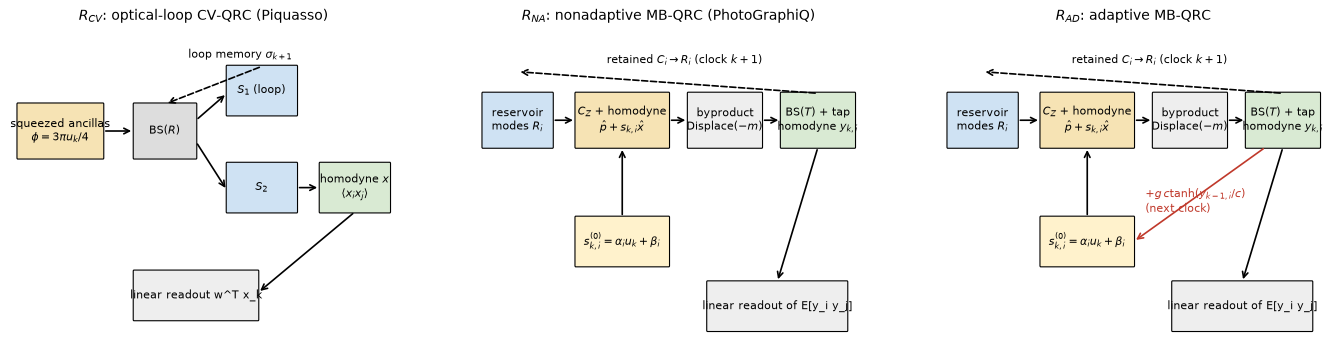

**Fig1_architectures.** Architecture of the three reservoirs. All three read out the same N(N+1)/2 second moments of N homodyne records through a linear ridge readout. AD differs from NA only by the red outcome-to-basis link (g != 0). Schematic; no data.

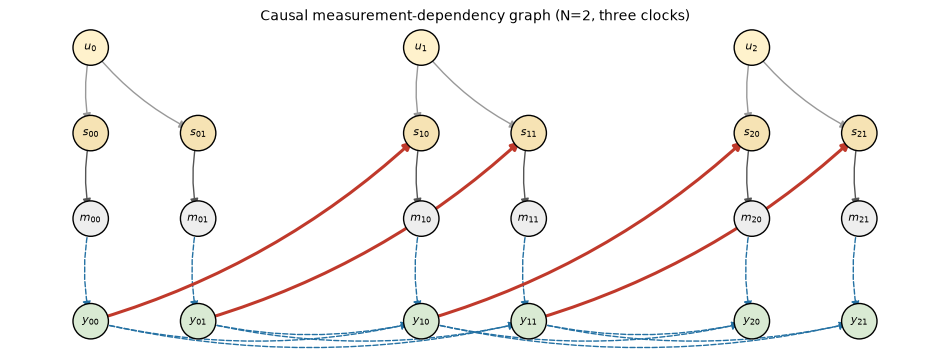

**Fig2_causal_graph.** Red: outcome-to-basis links that exist only in R_AD (tap record of clock k-1 to teleportation basis of clock k). Dashed blue: dependence through the quantum state (present in all MB reservoirs). Teleportation outcomes m feed only byproduct displacements and are never used to choose a basis. Severing every red edge gives R_NA exactly. Schematic; no data.

In [11]:
from matplotlib.patches import FancyBboxPatch
def _box(ax, x, y, w, h, text, fc):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", fc=fc, ec="k", lw=0.8))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=8)
def _arr(ax, a, b, color="k", ls="-"):
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color=color, lw=1.2, ls=ls))

fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
titles = ["$R_{CV}$: optical-loop CV-QRC (Piquasso)", "$R_{NA}$: nonadaptive MB-QRC (PhotoGraphiQ)", "$R_{AD}$: adaptive MB-QRC"]
for ax, t in zip(axs, titles):
    ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off"); ax.set_title(t, fontsize=10)
ax = axs[0]
_box(ax, 0.2, 3.6, 2.2, 1.0, "squeezed ancillas\n$\\phi=3\\pi u_k/4$", "#f6e3b4"); _box(ax, 3.2, 3.6, 1.6, 1.0, "BS($R$)", "#ddd")
_box(ax, 5.6, 4.4, 1.8, 0.9, "$S_1$ (loop)", "#cfe2f3"); _box(ax, 5.6, 2.6, 1.8, 0.9, "$S_2$", "#cfe2f3")
_box(ax, 8.0, 2.6, 1.8, 0.9, "homodyne $x$\n$\\langle x_ix_j\\rangle$", "#d9ead3"); _box(ax, 3.2, 0.6, 3.2, 0.9, "linear readout w^T x_k", "#eee")
_arr(ax, (2.4, 4.1), (3.2, 4.1)); _arr(ax, (4.8, 4.3), (5.6, 4.8)); _arr(ax, (4.8, 3.9), (5.6, 3.0)); _arr(ax, (7.4, 3.05), (8.0, 3.05))
_arr(ax, (6.5, 5.3), (4.0, 4.6), ls="--"); ax.text(4.6, 5.45, "loop memory $\\sigma_{k+1}$", fontsize=8); _arr(ax, (8.9, 2.6), (6.4, 1.1))
for ax, adaptive in ((axs[1], False), (axs[2], True)):
    _box(ax, 0.2, 3.8, 1.8, 1.0, "reservoir\nmodes $R_i$", "#cfe2f3"); _box(ax, 2.6, 3.8, 2.4, 1.0, "$C_Z$ + homodyne\n$\\hat p+s_{k,i}\\hat x$", "#f6e3b4")
    _box(ax, 5.5, 3.8, 1.9, 1.0, "byproduct\nDisplace($-m$)", "#eee"); _box(ax, 7.9, 3.8, 1.9, 1.0, "BS($T$) + tap\nhomodyne $y_{k,i}$", "#d9ead3")
    _box(ax, 2.6, 1.6, 2.4, 0.9, "$s^{(0)}_{k,i}=\\alpha_iu_k+\\beta_i$", "#fff2cc"); _box(ax, 6.0, 0.4, 3.6, 0.9, "linear readout of E[y_i y_j]", "#eee")
    _arr(ax, (2.0, 4.3), (2.6, 4.3)); _arr(ax, (5.0, 4.3), (5.5, 4.3)); _arr(ax, (7.4, 4.3), (7.9, 4.3)); _arr(ax, (3.8, 2.5), (3.8, 3.8))
    _arr(ax, (8.85, 3.8), (7.8, 1.3)); _arr(ax, (8.85, 4.8), (1.1, 5.2), ls="--"); ax.text(3.4, 5.35, "retained $C_i\\to R_i$ (clock $k+1$)", fontsize=8)
    if adaptive:
        _arr(ax, (8.4, 3.8), (5.0, 2.05), color=COL["AD"]); ax.text(5.3, 2.6, "$+g\\,c\\tanh(y_{k-1,i}/c)$\n(next clock)", color=COL["AD"], fontsize=8)
show_fig(fig, "Fig1_architectures", "Architecture of the three reservoirs. All three read out the same N(N+1)/2 second moments of N homodyne records "
         "through a linear ridge readout. AD differs from NA only by the red outcome-to-basis link (g != 0). Schematic; no data.")

G = nx.DiGraph(); pos = {}
for k in range(3):
    for i in range(2):
        G.add_node(f"u{k}", kind="input"); pos[f"u{k}"] = (4 * k, 3.2)
        for nm, yy, kind in ((f"s{k}{i}", 2.2 - 0.0 * i, "basis"), (f"m{k}{i}", 1.2, "tele"), (f"y{k}{i}", 0.0, "tap")):
            G.add_node(nm, kind=kind); pos[nm] = (4 * k + 1.3 * i, yy)
        G.add_edge(f"u{k}", f"s{k}{i}", kind="input"); G.add_edge(f"s{k}{i}", f"m{k}{i}", kind="basis"); G.add_edge(f"m{k}{i}", f"y{k}{i}", kind="state")
        if k:
            G.add_edge(f"y{k-1}{i}", f"s{k}{i}", kind="adaptive")
            for j in range(2):
                G.add_edge(f"y{k-1}{j}", f"y{k}{i}", kind="state")
fig, ax = plt.subplots(figsize=(12, 4.2)); ecol = {"input": "#999", "basis": "#555", "state": "#2471a3", "adaptive": COL["AD"]}
for kind, col in ecol.items():
    nx.draw_networkx_edges(G, pos, edgelist=[(a, b) for a, b, d in G.edges(data=True) if d["kind"] == kind], edge_color=col, ax=ax,
                           width=2.2 if kind == "adaptive" else 1.0, style="dashed" if kind == "state" else "solid", arrowsize=12,
                           connectionstyle="arc3,rad=0.12")
ncol = {"input": "#fff2cc", "basis": "#f6e3b4", "tele": "#eee", "tap": "#d9ead3"}
nx.draw_networkx_nodes(G, pos, node_color=[ncol[G.nodes[n]["kind"]] for n in G], edgecolors="k", node_size=650, ax=ax)
nx.draw_networkx_labels(G, pos, labels={n: {"u": "$u_{%s}$", "s": "$s_{%s}$", "m": "$m_{%s}$", "y": "$y_{%s}$"}[n[0]] % n[1:] for n in G}, font_size=8, ax=ax)
ax.axis("off"); ax.set_title("Causal measurement-dependency graph (N=2, three clocks)", fontsize=10)
show_fig(fig, "Fig2_causal_graph", "Red: outcome-to-basis links that exist only in R_AD (tap record of clock k-1 to teleportation basis of clock k). "
         "Dashed blue: dependence through the quantum state (present in all MB reservoirs). Teleportation outcomes m feed only byproduct "
         "displacements and are never used to choose a basis. Severing every red edge gives R_NA exactly. Schematic; no data.")

## 6. Resource-matching contract

All three architectures use paired inputs, paired train/test partitions and the same readout class (ridge with intercept, the same $\lambda$ grid, $\lambda$ chosen on the last 25 % of the training block). AD and NA additionally share the reservoir draw $(\alpha,\beta)$ and the innovation stream (common random numbers). Exact matching is impossible in one respect: the MB cluster consumes squeezed light at $r_{pg}$, while CV-QRC squeezes its ancillas at $r_{in}=1$. Two accountings are therefore reported:

1. **equal feature/readout budget** (primary): same $N$, same $N(N+1)/2$ features, same $F+1$ readout parameters, same shots;
2. **equal physical-resource budget**: CV-QRC with ancilla squeezing raised to the MB cluster squeezing (equal squeezed photons per clock, `CV_photon`). NA and CV are also given a second independent reservoir (twice the features and modes, control C7).

An advantage that appears under only one accounting is qualified in §16. Mean photon numbers are measured, not assumed.

In [12]:
def mean_photon_mb(res, u, g, M, seed=0):
    """Ensemble mean photon number per clock of the retained reservoir, n = (Tr Gamma + |R|^2)/4 - N/2 (hbar=2)."""
    D = res.dev(np); n = D["n"]; z = rng_for("photon", seed); Gam = np.broadcast_to(np.eye(n), (M, n, n)).copy(); mu = np.zeros((M, n))
    y = np.zeros((M, res.N)); out = []; c = PREREGISTERED["controller_scale"]
    for k in range(len(u)):
        ds = np.broadcast_to(D["alpha"] * u[k], (M, res.N)) + g * c * np.tanh(y / c)
        GCC, GCV, GVV, mC, mV = _moments(D, np, Gam, mu, ds)
        y = mV + (np.linalg.cholesky(GVV) @ z.standard_normal((M, res.N))[..., None])[..., 0]
        Gam, mu = _update(np, GCC, GCV, GVV, mC, mV, y)
        out.append(((np.trace(Gam, axis1=1, axis2=2) + (mu ** 2).sum(1)) / 4 - res.N / 2).mean())
    return float(np.mean(out[len(out) // 4:]))

def resource_table(N, g, rid=0, cond=None):
    cond = cond or cond_of(); res = make_mb(rid, N, cond); cv = make_cv(rid, N, cond); u = input_sequence(rid, 99, 400)
    sig, nbar_cv = np.eye(2 * N), []
    for k in range(400):
        sig = cv.loss * (cv.S1 @ (cv.R * sig + (1 - cv.R) * cv.sigma_anc(u[k])[0]) @ cv.S1.T) + (1 - cv.loss) * np.eye(2 * N)
        nbar_cv.append(np.trace(sig) / 4 - N / 2)
    F = N * (N + 1) // 2; r_pg = r_pg_from_db(cond["squeezing_db"]); r_in = cond["cv_input_squeezing"]
    lam = len(CFG["ridge_grid"]); n_edges = int(res.A[:N, :N].sum() / 2)
    rows = {
        "optical modes (reservoir)": (N, N, N),
        "cluster nodes consumed per clock": (N, N, 0),
        "squeezed modes injected per clock": (N, N, N),
        "squeezing per injected mode (dB)": (cond["squeezing_db"], cond["squeezing_db"], round(20 * r_in / np.log(10), 2)),
        "squeezed photons injected per clock": (round(N * np.sinh(r_pg) ** 2, 2),) * 2 + (round(N * np.sinh(r_in) ** 2, 2),),
        "mean photon number in reservoir (measured)": (round(mean_photon_mb(res, u[:300], g, 256), 3), round(mean_photon_mb(res, u[:300], 0.0, 256), 3),
                                                       round(float(np.mean(nbar_cv[100:])), 3)),
        "physical depth per clock (gates)": (f"{2 * N + n_edges} two-mode + {N} BS", f"{2 * N + n_edges} two-mode + {N} BS", f"{N} BS + 2 networks"),
        "measurements per clock": (f"{N} teleport + {N} tap", f"{N} teleport + {N} tap", f"{N} homodyne"),
        "outcomes supplied to readout per clock": (N, N, N),
        "feature count": (F, F, F), "readout parameters": (F + 1, F + 1, F + 1),
        "input samples (washout/train/test)": ((CFG["washout"], CFG["train"], CFG["test"]),) * 3,
        "shots (copies) per feature": (CFG["shots_primary"],) * 3,
        "accepted samples after postselection": ("100 % (none)",) * 3,
        "loop loss (transmissivity)": (cond["loop_transmissivity"],) * 3, "detector efficiency": (cond["detector_efficiency"],) * 3,
        "task-evaluated hyperparameters": (f"lambda grid ({lam})",) * 3,
        "structural hyperparameters (task-independent rule)": ("g* from chi_ad rule (§9)", "none (g=0)", "R = T (matched forgetting)"),
        "classical feedforward ops per clock": (f"{N + n_edges} byproduct + {N} adaptive (mult+tanh)", f"{N + n_edges} byproduct", "0"),
    }
    return pd.DataFrame(rows, index=["R_AD", "R_NA", "R_CV"]).T

with section("6 resource contract"):
    RESOURCE_DF = resource_table(CFG["N_main"], 0.4)
    with pd.option_context("display.max_colwidth", 70, "display.width", 250):
        display(RESOURCE_DF)
    _eq = ["feature count", "readout parameters", "shots (copies) per feature", "input samples (washout/train/test)",
           "loop loss (transmissivity)", "detector efficiency", "task-evaluated hyperparameters", "outcomes supplied to readout per clock"]
    RESOURCE_MATCHED = all(len(set(map(str, RESOURCE_DF.loc[r]))) == 1 for r in _eq)
    print("matched rows:", RESOURCE_MATCHED, "| unmatched, reported and normalized: squeezing/photon number (accounting 2 = CV_photon), "
          "feedforward ops (counted), depth (architecture-specific)")

,R_AD,R_NA,R_CV
optical modes (reservoir),5,5,5
cluster nodes consumed per clock,5,5,0
squeezed modes injected per clock,5,5,5
squeezing per injected mode (dB),15.0,15.0,8.69
squeezed photons injected per clock,37.07,37.07,6.91
mean photon number in reservoir (measured),3.534,2.706,9.743
physical depth per clock (gates),14 two-mode + 5 BS,14 two-mode + 5 BS,5 BS + 2 networks
measurements per clock,5 teleport + 5 tap,5 teleport + 5 tap,5 homodyne
outcomes supplied to readout per clock,5,5,5
feature count,15,15,15


matched rows: True | unmatched, reported and normalized: squeezing/photon number (accounting 2 = CV_photon), feedforward ops (counted), depth (architecture-specific)
[6 resource contract] 0.5 s | peak RSS 1170 MB


## 7. Proposed kernel selection rule

### 7.1 Volterra/IPC representation
For a feature $x_k$ (one of the $N(N+1)/2$ second moments), expand about $\mathbf u_0=0$:
$$x_k=K^{(0)}+\sum_\tau K^{(1)}_\tau u_{k-\tau}+\sum_{\tau_1,\tau_2}K^{(2)}_{\tau_1\tau_2}u_{k-\tau_1}u_{k-\tau_2}+\dots,\qquad K^{(p)}_{\boldsymbol\tau}=\frac1{p!}\frac{\partial^px_k}{\partial u_{k-\tau_1}\cdots\partial u_{k-\tau_p}}\Big|_{\mathbf u_0}.$$
We report **monomial coefficients** $c^{(p,q)}_{a,b}=\frac{1}{p!\,q!}\partial^p_{u_{k-a}}\partial^q_{u_{k-b}}x_k$, so that $c^{(3,1)}_{a,b}=4K^{(4)}_{aaab}$. Operationally, the same structure is probed by orthonormal Legendre products $\hat P_n(u)=\sqrt{2n+1}P_n(u)$ (information processing capacity, Dambre *et al.* 2012).

### 7.2 What each architecture can reach (derived, not assumed)
**Theorem 1 (CV-QRC is additively separable).** Assume §5.1: a fixed Gaussian channel whose input enters only through the added term $\sigma_{anc}(u_k)$, second-moment observables, and exact (or conditionally unbiased finite-shot) features. Then $\mathbf x_k=\mathbf c+\sum_{\tau\ge0}\mathcal L_\tau[\sigma_{anc}(u_{k-\tau})]$ with fixed linear maps $\mathcal L_\tau$. Hence $\partial^2x_k/\partial u_{k-a}\partial u_{k-b}\equiv0$ for $a\ne b$, at every expansion point: **every kernel involving two or more distinct delays vanishes.** Single-delay kernels of every order are allowed, because the encoding is trigonometric.
*Proof.* Unroll $\sigma_{k+1}=\eta_LS_1(R\sigma_k+(1-R)\sigma_{anc}(u_k))S_1^T+(1-\eta_L)I$: $\sigma_k$ is affine in $\{\sigma_{anc}(u_j)\}_{j<k}$, with no products, and $\sigma^{HD}_k$ is affine in $\sigma_k$ and $\sigma_{anc}(u_k)$. $\square$

**Theorem 2 (NA MB-QRC is multi-quadratic).** Assume §5.2:
- (i) $X(\mathbf s)$ is affine in every $s_i$;
- (ii) $Y$ is independent of $\mathbf s$;
- (iii) $\mathbf s_k=\boldsymbol\alpha u_k+\boldsymbol\beta$;
- (iv) there is no outcome-to-basis link;
- (v) features are linear in the second-moment matrix $\mathcal M=\Gamma+\mathbf R\mathbf R^T$.

Then $\mathbf x_k$ is a polynomial of degree $\le2$ in **each** $u_{k-\tau}$ separately. Every monomial in which some delay appears three or more times has coefficient exactly zero, at every expansion point.
*Proof.* Without feedback, the outcome average of the conditional second moments equals the unconditional channel (law of total variance, test P7b): $\mathcal M_{k+1}=X(\mathbf s_k)\mathcal M_kX(\mathbf s_k)^T+Y$. By (i) and (iii), $X(\mathbf s_k)=X_0+u_kX_1$, so $\mathcal M_{k+1}$ is quadratic in $u_k$ with coefficients linear in $\mathcal M_k$, and $\mathcal M_k$ depends only on $u_{j<k}$. By induction each $u_j$ enters through exactly one factor pair $X(\mathbf s_j)\cdot X(\mathbf s_j)^T$. The features $[X_V(\mathbf s_k)\mathcal M_kX_V(\mathbf s_k)^T+Y_{VV}+\sigma^2I]_{i\le j}$ are quadratic in $u_k$. $\square$
*Premises verified numerically:* (i) and (ii) with loss, detector inefficiency, finite squeezing and byproduct gain error (test P2).
*Premises broken by:*
- homodyne-angle jitter: $s_{\rm eff}$ becomes a Möbius function of $s$, so the rule degrades to a **suppression** $O(\sigma_\theta^2)$, quantified in §8;
- a nonlinear angle encoding;
- nonlinear classical post-processing of the features (e.g. products, which give fourth moments). The rule is a statement about **linear readouts of second moments only**; control D1 in §11 shows what quadratic post-processing does.

**Theorem 3 (causal constraint on AD).** In $R_{\mathrm{AD}}$, $u_k$ enters $\mathbf x_k$ only through $\mathbf s_k$. The record $\mathbf y_k$ is taken after the clock-$k$ gate and acts on the bases of clock $k+1$, and $\mathbb E[\mathbf y_k\mathbf y_k^T\mid\mathcal F_{k-1}]$ is quadratic in $\mathbf s_k$. So $\mathbf x_k$ has degree $\le2$ in $u_k$ for every $g$: **no adaptive kernel can be cubic in the current input.** For $a\ge1$ no such bound exists. $u_{k-a}$ also enters through the outcome statistics fed into later bases: products such as $\mathrm{Var}(y_{k-1})\cdot\Gamma^c_k$ are quartic in $u_{k-1}$. **Whether these terms survive in the cross-delay sector is not implied by any theorem here; it is tested.**

### 7.3 The adaptive response family and the preregistered witness
$$\mathcal K_\star=\{c^{(3,1)}_{\tau_c,\tau_l}:\ 1\le\tau_c\le D,\ 0\le\tau_l\le D,\ \tau_l\ne\tau_c\},\qquad D=3\ (9\text{ components}).$$
It is the lowest-order family that contains two distinct delays (Theorem 1 excludes it for CV) **and** a delay of multiplicity $\ge3$ (Theorem 2 excludes it for NA). Total order 4 is the minimum with both properties. $\tau_c=0$ is removed because Theorem 3 forbids it for AD as well. $D$ and the uniform weights were fixed before any pilot data (control panel).

**Structural hypothesis (tested, not assumed):** $K_\star^{\mathrm{CV}}=0$, $K_\star^{\mathrm{NA}}=0$ (Theorems 1–2), and $K_\star^{\mathrm{AD}}\neq0$ for $g\neq0$.

* **Adaptive-kernel norm** (weights fixed before confirmatory data): $\chi_{\mathrm{ad}}=\sum_{c\in\mathcal K_\star}\sum_f\big(c_{c,f}\big)^2\big/\sum_f\mathrm{Var}_{\mathbf u}(x^{\mathrm{NA}}_f)$. It is estimated without bias as a U-statistic over independent path blocks (§8).
* **Witness task** (primary): $y^\star_k=\frac13\sum_{(\tau_c,\tau_l)\in\mathcal K_\star}\hat P_3(u_{k-\tau_c})\hat P_1(u_{k-\tau_l})$, with unit variance.
* **Baseline error floor (corollary).** Every component of $y^\star$ is orthogonal, under the i.i.d. uniform input law, to the span of the features allowed by Theorem 1 (sums of single-delay functions) and by Theorem 2 (multi-quadratic products). Hence for **any** $N$, any shot number (finite-shot features are conditionally unbiased) and any linear readout, the population-optimal witness NMSE of $R_{\mathrm{CV}}$ and $R_{\mathrm{NA}}$ is exactly $\epsilon_0=1$. With finite training data the expected test NMSE is $\gtrsim1$ (over-fitting).
* **Endpoints.** Primary: test NMSE of $y^\star$ from **raw finite-shot features** at `shots_primary`. Improvements are $\Delta_A=\mathrm{NMSE}_{\mathrm{NA}}-\mathrm{NMSE}_{\mathrm{AD}}$ and $\Delta_B=\mathrm{NMSE}_{\mathrm{CV}}-\mathrm{NMSE}_{\mathrm{AD}}$, tested one-sided at family-wise $\alpha=0.05$ with Holm's correction over $\{H_A,H_B\}$. Co-primary (secondary family, separate Holm): family capacity $C_\star=\sum_{c}(1-\mathrm{NMSE}_c)$. Secondary, descriptive only: RB (ideal) features, NARMA5, NARMA10, delayed XOR, 3-bit parity, linear memory capacity.

In [13]:
D_WIT = PREREGISTERED["witness_max_delay"]
KSTAR = [(tc, tl) for tc in range(1, D_WIT + 1) for tl in range(0, D_WIT + 1) if tl != tc]
PAD = 25                                                       # leading samples dropped from every target (max delay used: 20)

def leg(n, x):
    return np.sqrt(2 * n + 1) * npleg.legval(x, [0] * n + [1])

def lagged(u, t):
    out = np.zeros_like(u); out[t:] = u[:len(u) - t] if t else u; return out

def narma(u, order):
    v = 0.25 * (u + 1); y = np.zeros(len(u))
    for k in range(order, len(u)):
        y[k] = 0.3 * y[k - 1] + 0.05 * y[k - 1] * y[k - order:k].sum() + 1.5 * v[k - 1] * v[k - order] + 0.1
    return np.clip(y, -10, 10)

def make_targets(u, secondary=True):
    T_ = {f"K*{c}": leg(3, lagged(u, c[0])) * leg(1, lagged(u, c[1])) for c in KSTAR}
    T_["witness"] = sum(T_[f"K*{c}"] for c in KSTAR) / np.sqrt(len(KSTAR))
    if secondary:
        b = (u > 0).astype(float)
        T_["NARMA5"], T_["NARMA10"] = narma(u, 5), narma(u, 10)
        T_["XOR(1,2)"] = np.logical_xor(lagged(b, 1), lagged(b, 2)).astype(float)
        T_["parity3"] = ((lagged(b, 0) + lagged(b, 1) + lagged(b, 2)) % 2).astype(float)
        for t in range(21):
            T_[f"mem{t}"] = lagged(u, t)
    return T_

def readout_nmse(X, targets, W, Ltr, lam_grid=None, fixed_lambda=None):
    """Ridge (intercept unpenalized via centring) on standardized features; lambda chosen per target on the last 25 % of the
    training block (same grid for every model), refit on the full training block, test NMSE = MSE / Var(test target)."""
    lam_grid = CFG["ridge_grid"] if lam_grid is None else lam_grid
    W = max(W, PAD); X = np.asarray(X, float)
    if not np.isfinite(X[W:]).all():
        return {k: np.nan for k in targets}, {}
    Xtr, Xte = X[W:W + Ltr], X[W + Ltr:]
    mu, sd = Xtr.mean(0), Xtr.std(0); sd = np.where(sd > 1e-12 * max(1.0, np.abs(mu).max()), sd, 1.0)
    Z, Zte = (Xtr - mu) / sd, (Xte - mu) / sd
    Y = np.stack([targets[k][W:W + Ltr] for k in targets], 1); Yte = np.stack([targets[k][W + Ltr:] for k in targets], 1)
    nv = int(0.75 * Ltr)
    def fit(Zf, Yf, lams):
        zm, ym = Zf.mean(0), Yf.mean(0); U_, s_, Vt = np.linalg.svd(Zf - zm, full_matrices=False); UtY = U_.T @ (Yf - ym)
        return [(Vt.T @ ((s_ / (s_ ** 2 + l))[:, None] * UtY), zm, ym) for l in lams]
    if fixed_lambda is None:
        errs = np.array([((Z[nv:] - zm) @ w + ym - Y[nv:]) ** 2 for (w, zm, ym) in fit(Z[:nv], Y[:nv], lam_grid)]).mean(1)   # (L, P)
        best = [lam_grid[i] for i in errs.argmin(0)]
    else:
        best = [fixed_lambda] * Y.shape[1]
    out, chosen = {}, {}
    for j, k in enumerate(targets):
        (w, zm, ym), = fit(Z, Y[:, [j]], [best[j]])
        pred = (Zte - zm) @ w + ym
        out[k] = float(np.mean((pred[:, 0] - Yte[:, j]) ** 2) / np.var(Yte[:, j])); chosen[k] = best[j]
    return out, chosen

def summarize_scores(sc):
    """Derived per-model scores from per-target NMSEs."""
    d = dict(witness=sc.get("witness", np.nan), Cstar=float(sum(1 - sc[f"K*{c}"] for c in KSTAR)))
    for k in ("NARMA5", "NARMA10", "XOR(1,2)", "parity3"):
        if k in sc:
            d[k] = sc[k]
    if "mem0" in sc:
        d["MC"] = float(sum(max(0.0, 1 - sc[f"mem{t}"]) for t in range(21)))
    return d
print(f"K* family ({len(KSTAR)} components):", KSTAR)

K* family (9 components): [(1, 0), (1, 2), (1, 3), (2, 0), (2, 1), (2, 3), (3, 0), (3, 1), (3, 2)]


## 8. Analytic and numerical validation of the selection rule

Kernel coefficients are estimated with independent methods:

1. **Cauchy contour (analytic differentiation).** $c^{(p,q)}_{a,b}=\frac{1}{n^2}\sum_{j,l}x(\rho e^{i\theta_j},\rho e^{i\theta_l})e^{-ip\theta_j-iq\theta_l}\rho^{-p-q}$, evaluated by running the engines on **complex** inputs (analytic continuation). For polynomials this is exact to rounding, and spectrally accurate otherwise.
2. **Central finite differences** (tensor-product stencils of order $p,q$, step $h$). For the Monte Carlo AD engine these use common random numbers, so they are pathwise derivatives with Monte Carlo error only.
3. **IPC regression** (Legendre capacities of the witness components), an operational cross-check (§11, Fig. 4b).

The tests below establish:
- (a) the exact zeros of Theorems 1–2 on the actual engines, including loss, detector inefficiency, finite squeezing and feedforward gain error;
- (b) agreement of methods 1 and 2;
- (c) how homodyne-angle jitter turns the NA zero into a quantitative suppression $\|K_\star^{NA}\|\le C\sigma_\theta^2$;
- (d) step convergence of the pathwise AD estimator;
- (e) the escape of the unbounded linear controller (the reason for the bounded actuator).

In [14]:
STENCIL = {0: {0: 1.0}, 1: {-1: -0.5, 1: 0.5}, 2: {-1: 1.0, 0: -2.0, 1: 1.0}, 3: {-2: -0.5, -1: 1.0, 1: -1.0, 2: 0.5},
           4: {-2: 1.0, -1: -4.0, 0: 6.0, 1: -4.0, 2: 1.0}}

def stencil_points(K, a, p, b, q, h):
    """Input sequences (K, P) and weights of the tensor-product stencil for c^{(p,q)}_{a,b} (a == b: single delay, order p+q)."""
    pts, wts = [], []
    if a == b:
        for i, w in STENCIL[p + q].items():
            u = np.zeros(K); u[K - 1 - a] = i * h; pts.append(u); wts.append(w)
        return np.stack(pts, 1), np.array(wts) / (h ** (p + q) * math.factorial(p + q))
    for i, wi in STENCIL[p].items():
        for j, wj in STENCIL[q].items():
            u = np.zeros(K); u[K - 1 - a] = i * h; u[K - 1 - b] = j * h; pts.append(u); wts.append(wi * wj)
    return np.stack(pts, 1), np.array(wts) / (h ** (p + q) * math.factorial(p) * math.factorial(q))

def fd_coeff(fun, K, a, p, b, q, h):
    U, w = stencil_points(K, a, p, b, q, h)
    return w @ np.asarray(fun(U)).real

def cauchy_coeff(fun, K, a, p, b, q, rho=0.3, n=12):
    th = 2 * np.pi * np.arange(n) / n; z = rho * np.exp(1j * th)
    if a == b:
        U = np.zeros((K, n), complex); U[K - 1 - a] = z
        return (np.exp(-1j * (p + q) * th) @ np.asarray(fun(U))).real / n / rho ** (p + q)
    U = np.zeros((K, n * n), complex); U[K - 1 - a] = np.repeat(z, n); U[K - 1 - b] = np.tile(z, n)
    ph = np.exp(-1j * (p * np.repeat(th, n) + q * np.tile(th, n)))
    return (ph @ np.asarray(fun(U))).real / n ** 2 / rho ** (p + q)

def na_exact_jitter(res, U, sigma, nq=11):
    """Exact NA ensemble features with Gaussian homodyne-angle jitter (per mode, per clock), by Gauss-Hermite quadrature of the
    per-mode Moebius map; E[X M X^T] = Xbar M Xbar^T + sum_i Var(s_i) dX_i M dX_i^T (X affine, jitter independent across modes)."""
    D = res.dev(np); N, n = res.N, D["n"]; iu0, iu1 = res.iu; U = np.asarray(U, complex); K, B = U.shape
    xq, wq = np.polynomial.hermite_e.hermegauss(nq); wq = wq / wq.sum(); dq = sigma * xq
    dXC, dXV = res.dXC, res.dXV
    M = np.broadcast_to(np.eye(n, dtype=complex), (B, n, n)).copy()
    for k in range(K):
        s = res.beta + res.alpha * U[k][:, None]                                       # (B, N)
        se = _angle_jitter(np, s[..., None], dq)                                        # (B, N, nq)
        Es, Es2 = se @ wq, (se ** 2) @ wq; var = Es2 - Es ** 2; ds = Es - res.beta
        XC = res.XC0 + np.tensordot(ds, dXC, 1); XV = res.XV0 + np.tensordot(ds, dXV, 1)
        if k == K - 1:
            O = XV @ M @ _sw(XV) + res.YVV + res.sig2 * np.eye(N)
            O = O + np.einsum("bi,ijk,bkl,iml->bjm", var, dXV, M, dXV)
            return O[:, iu0, iu1]
        M = XC @ M @ _sw(XC) + res.YCC + np.einsum("bi,ijk,bkl,iml->bjm", var, dXC, M, dXC)

def ad_kernel_blocks(res, g, comp, M, seed, K, h, xp=np, n_blocks=16, dtype=np.float64, **kw):
    """Pathwise CRN finite-difference estimates of c^{(p,q)}_{a,b} for R_AD (g=0: R_NA through the same Monte Carlo engine,
    which is the paired null). comp = (a, p, b, q). Returns (n_blocks, F) block means."""
    a, p, b, q = comp; U, w = stencil_points(K, a, p, b, q, h); P = U.shape[1]
    Upaths = np.repeat(U, M, axis=1)                                                   # column t*M + m <- stencil point t
    out = mb_trajectories(res, Upaths, g, rng_for("kernel", seed), M, xp=xp, tile=P, final_per_path=True, dtype=dtype, **kw)
    if out["diverged"] is not None:
        return None
    per_path = np.tensordot(w, out["final"].reshape(P, M, -1), 1)                      # (M, F)
    return per_path.reshape(n_blocks, M // n_blocks, -1).mean(1)

def chi_from_blocks(blocks_by_comp, vtot):
    """Unbiased U-statistic for sum_c ||c_c||^2 / vtot over independent path blocks, with a jackknife standard error."""
    Kb = np.stack(blocks_by_comp)                                                      # (C, B, F)
    Bn = Kb.shape[1]; S = Kb.sum(1); Q = (Kb ** 2).sum(1)
    est = float(((S ** 2 - Q).sum() / (Bn * (Bn - 1))) / vtot)
    jk = np.array([(((S - Kb[:, j]) ** 2 - (Q - Kb[:, j] ** 2)).sum() / ((Bn - 1) * (Bn - 2))) / vtot for j in range(Bn)])
    return est, float(np.sqrt((Bn - 1) / Bn * ((jk - jk.mean()) ** 2).sum()))

def feature_variance_total(res, rid, K=2500):
    X = na_exact(res, input_sequence(rid, 777, K)); return float(X[200:].var(0).sum())

with section("8 selection-rule validation"):
    Kk = CFG["kernel_steps"]; worst_na = worst_cv = 0.0; agree = 0.0; rows = []
    conds = {"base": cond_of(), "lossy": cond_of(squeezing_db=10.0, loop_transmissivity=0.9, detector_efficiency=0.9, feedforward_gain_error=0.02)}
    for N_ in CFG["N_list"]:
        for rid in range(2):
            for cname, cd in conds.items():
                res_, cv_ = make_mb(rid, N_, cd), make_cv(rid, N_, cd)
                fna = lambda U, r=res_: na_exact(r, U, final_only=True); fcv = lambda U, c=cv_: c.exact(U, final_only=True)
                na_allowed = max(np.abs(cauchy_coeff(fna, Kk, a, 2, b, 1)).max() for a, b in [(1, 0), (2, 1), (0, 2)])
                na_forbid = max([np.abs(cauchy_coeff(fna, Kk, tc, 3, tl, 1)).max() for tc, tl in KSTAR] +
                                [np.abs(cauchy_coeff(fna, Kk, a, 3, a, 0)).max() for a in range(4)])
                cv_allowed = max(np.abs(cauchy_coeff(fcv, Kk, a, 3, a, 0)).max() for a in range(3))
                cv_forbid = max([np.abs(cauchy_coeff(fcv, Kk, a, 1, b, 1)).max() for a, b in [(0, 1), (1, 2), (0, 3)]] +
                                [np.abs(cauchy_coeff(fcv, Kk, tc, 3, tl, 1)).max() for tc, tl in KSTAR[:4]])
                worst_na, worst_cv = max(worst_na, na_forbid / na_allowed), max(worst_cv, cv_forbid / cv_allowed)
                c_fd, c_ca = fd_coeff(fna, Kk, 1, 2, 0, 1, 0.05), cauchy_coeff(fna, Kk, 1, 2, 0, 1)
                c_fd2, c_ca2 = fd_coeff(fcv, Kk, 1, 3, 1, 0, 0.02), cauchy_coeff(fcv, Kk, 1, 3, 1, 0)
                agree = max(agree, np.abs(c_fd - c_ca).max() / np.abs(c_ca).max(), np.abs(c_fd2 - c_ca2).max() / np.abs(c_ca2).max())
                rows.append(dict(N=N_, rid=rid, cond=cname, NA_forbidden_over_allowed=na_forbid / na_allowed, CV_forbidden_over_allowed=cv_forbid / cv_allowed,
                                 NA_c21_FD_vs_Cauchy=np.abs(c_fd - c_ca).max() / np.abs(c_ca).max(), CV_c3_FD_vs_Cauchy=np.abs(c_fd2 - c_ca2).max() / np.abs(c_ca2).max()))
    ZERO_DF = pd.DataFrame(rows); display(ZERO_DF)
    tol = PREREGISTERED["zero_tol_rel"]
    record_test("S8.NA0", "physics", "Theorem 2 on the engine: NA forbidden coefficients (K*, single-delay cubic) / allowed c21, incl. loss, eta, ff error, 10 dB",
                worst_na, f"< {tol:g}", worst_na < tol)
    record_test("S8.CV0", "physics", "Theorem 1 on the engine: CV cross-delay coefficients (c11, K*) / allowed single-delay c3", worst_cv, f"< {tol:g}", worst_cv < tol)
    record_test("N5a", "numerical", "finite differences vs Cauchy contour on allowed coefficients (NA c21 exact; CV c3, h=0.02), relative", agree, "< 1e-3", agree < 1e-3)
    STRUCT_ZERO_OK = worst_na < tol and worst_cv < tol

    # (c) angle-jitter suppression of the NA zero ---------------------------------------------------------------------
    rj = make_mb(0, CFG["N_main"], cond_of()); fj0 = lambda U: na_exact_jitter(rj, U, 0.0)
    ref21 = np.abs(cauchy_coeff(lambda U: na_exact(rj, U, final_only=True), Kk, 1, 2, 0, 1)).max()
    e_j0 = np.abs(cauchy_coeff(fj0, Kk, 1, 2, 0, 1) - cauchy_coeff(lambda U: na_exact(rj, U, final_only=True), Kk, 1, 2, 0, 1)).max() / ref21
    SIG = [0.005, 0.01, 0.02, 0.04, 0.08]; JIT = []
    for sg in SIG:
        f_ = lambda U, s_=sg: na_exact_jitter(rj, U, s_)
        JIT.append(np.sqrt(sum((cauchy_coeff(f_, Kk, tc, 3, tl, 1) ** 2).sum() for tc, tl in KSTAR)) / ref21)
    slope = np.polyfit(np.log(SIG[:3]), np.log(JIT[:3]), 1)[0]; C_supp = float(np.median(np.array(JIT[:3]) / np.array(SIG[:3]) ** 2))
    record_test("S8.jit0", "numerical", "jitter recursion at sigma=0 reproduces the exact NA kernels", e_j0, "< 1e-10", e_j0 < 1e-10)
    record_test("S8.jit", "physics", "angle jitter breaks Theorem 2 only at O(sigma^2): log-log slope of ||K*_NA|| (relative) vs sigma",
                slope, "in [1.8, 2.2]", 1.8 <= slope <= 2.2, critical=False)
    print(f"suppression statement: ||K*_NA|| / max|c21| <= {C_supp:.3g} sigma_theta^2 (fitted over sigma <= 0.02 rad)")

    # (d) pathwise AD estimator: Cauchy vs FD (tiny, complex engine) and step convergence -----------------------------
    rt = make_mb(1, 3, cond_of()); Mt = 64
    def fad(U, r=rt):
        P = U.shape[1]; o = mb_trajectories(r, np.repeat(U, Mt, axis=1), 0.4, rng_for("ad-cauchy"), Mt, tile=P, final_per_path=True,
                                            dtype=np.complex128 if np.iscomplexobj(U) else np.float64)
        return o["final"].reshape(P, Mt, -1).mean(1)
    c_ca, c_fd = cauchy_coeff(fad, 12, 1, 3, 0, 1, rho=0.25, n=10), fd_coeff(fad, 12, 1, 3, 0, 1, 0.02)
    e_ad = np.abs(c_ca - c_fd).max() / max(np.abs(c_ca).max(), 1e-12)
    record_test("N5b", "numerical", "adaptive engine: pathwise Cauchy contour (complex trajectories) vs CRN finite differences, c31(1,0), relative",
                e_ad, "< 2e-3", e_ad < 2e-3)
    STEP = {}
    for hh in (0.2, 0.1, 0.05):
        bl = ad_kernel_blocks(make_mb(0, CFG["N_main"], cond_of()), 0.4, (1, 3, 0, 1), 512, "step", Kk, hh)
        STEP[hh] = bl.mean(0)
    d1, d2 = np.abs(STEP[0.2] - STEP[0.1]).max(), np.abs(STEP[0.1] - STEP[0.05]).max()
    record_test("N5c", "numerical", "FD step convergence of the pathwise AD kernel (successive-difference ratio; O(h^2) -> 4)", d1 / max(d2, 1e-300),
                "> 2.5", d1 / max(d2, 1e-300) > 2.5, critical=False)

    # (e) escape of the unbounded linear controller ----------------------------------------------------------------------
    ESC = []
    for gg in [0.05, 0.1, 0.15, 0.2, 0.3]:
        for scale, lab in ((0.0, "linear"), (PREREGISTERED["controller_scale"], "bounded tanh")):
            o = mb_trajectories(make_mb(0, CFG["N_main"], cond_of()), input_sequence(0, 5, 1500 if RUN_MODE != "unit" else 300), gg,
                                rng_for("escape", gg), 128, controller_scale=scale, check_every=5)
            ESC.append(dict(g=gg, controller=lab, first_escape_clock=o["diverged"] if o["diverged"] is not None else np.inf))
    ESC_DF = pd.DataFrame(ESC); display(ESC_DF.pivot(index="g", columns="controller", values="first_escape_clock"))

,N,rid,cond,NA_forbidden_over_allowed,CV_forbidden_over_allowed,NA_c21_FD_vs_Cauchy,CV_c3_FD_vs_Cauchy
0,3,0,base,4.575898e-14,1.199932e-14,2.028220e-12,0.000555
1,3,0,lossy,5.387684e-14,1.371351e-14,3.668855e-12,0.000555
2,3,1,base,7.186879e-14,1.456821e-14,5.238581e-12,0.000555
3,3,1,lossy,9.907015e-14,1.499669e-14,3.819947e-12,0.000555
4,5,0,base,7.855020e-14,1.547142e-14,1.038725e-11,0.000555
5,5,0,lossy,8.757145e-14,1.384285e-14,5.988771e-12,0.000555
6,5,1,base,3.935449e-14,1.390608e-14,1.608694e-12,0.000555
7,5,1,lossy,4.604659e-14,1.349574e-14,2.792463e-12,0.000555


PASS [S8.NA0] (critical) Theorem 2 on the engine: NA forbidden coefficients (K*, single-delay cubic) / allowed c21, incl. loss, eta, ff error, 10 dB: 9.91e-14 (criterion < 1e-09)
PASS [S8.CV0] (critical) Theorem 1 on the engine: CV cross-delay coefficients (c11, K*) / allowed single-delay c3: 1.55e-14 (criterion < 1e-09)
PASS [N5a] (critical) finite differences vs Cauchy contour on allowed coefficients (NA c21 exact; CV c3, h=0.02), relative: 0.000555 (criterion < 1e-3)


PASS [S8.jit0] (critical) jitter recursion at sigma=0 reproduces the exact NA kernels: 5.21e-15 (criterion < 1e-10)
PASS [S8.jit] angle jitter breaks Theorem 2 only at O(sigma^2): log-log slope of ||K*_NA|| (relative) vs sigma: 2.01 (criterion in [1.8, 2.2])
suppression statement: ||K*_NA|| / max|c21| <= 13.1 sigma_theta^2 (fitted over sigma <= 0.02 rad)


PASS [N5b] (critical) adaptive engine: pathwise Cauchy contour (complex trajectories) vs CRN finite differences, c31(1,0), relative: 0.000374 (criterion < 2e-3)


PASS [N5c] FD step convergence of the pathwise AD kernel (successive-difference ratio; O(h^2) -> 4): 3.88 (criterion > 2.5)


controller,bounded tanh,linear
g,,
0.05,inf,inf
0.10,inf,20.0
0.15,inf,14.0
0.20,inf,10.0
0.30,inf,10.0


[8 selection-rule validation] 43.2 s | peak RSS 1170 MB


### 8.1 Figure 4a: method agreement, suppression and controller stability

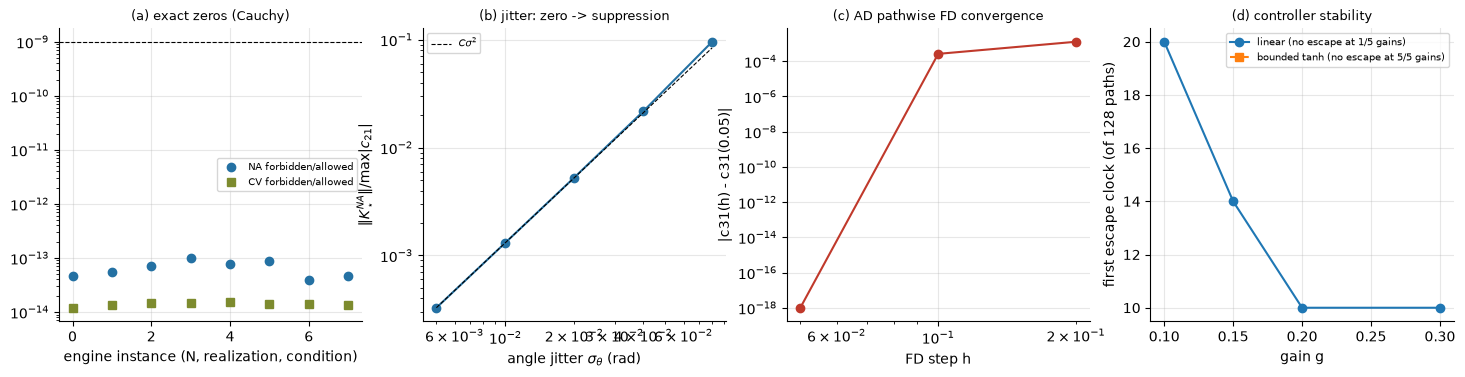

**Fig4a_kernel_method_validation.** (a) Forbidden/allowed coefficient ratios from Cauchy contours on the exact NA and CV engines (8 instances: N in [3, 5], 2 realizations, base and lossy conditions); deterministic, no error bars. (b) Exact NA kernel leakage under homodyne-angle jitter (Gauss-Hermite recursion, one realization, N=5). (c) Pathwise AD c31(1,0) at g=0.4 vs FD step (512 CRN paths; differences are paired, so Monte Carlo noise cancels). (d) First clock at which any of 128 trajectories escapes (inf = none within the run).

In [15]:
fig, axs = plt.subplots(1, 4, figsize=(18, 3.8))
ax = axs[0]; ax.semilogy(range(len(ZERO_DF)), ZERO_DF.NA_forbidden_over_allowed + 1e-18, "o", color=COL["NA"], label="NA forbidden/allowed")
ax.semilogy(range(len(ZERO_DF)), ZERO_DF.CV_forbidden_over_allowed + 1e-18, "s", color=COL["CV"], label="CV forbidden/allowed")
ax.axhline(PREREGISTERED["zero_tol_rel"], color="k", ls="--", lw=0.8); ax.set_xlabel("engine instance (N, realization, condition)"); ax.legend(fontsize=7)
ax.set_title("(a) exact zeros (Cauchy)", fontsize=9)
ax = axs[1]; ax.loglog(SIG, JIT, "o-", color=COL["NA"]); ax.loglog(SIG, C_supp * np.array(SIG) ** 2, "k--", lw=0.8, label=r"$C\sigma^2$")
ax.set_xlabel(r"angle jitter $\sigma_\theta$ (rad)"); ax.set_ylabel(r"$\|K_\star^{NA}\|/\max|c_{21}|$"); ax.legend(fontsize=7); ax.set_title("(b) jitter: zero -> suppression", fontsize=9)
ax = axs[2]; hs = sorted(STEP); ax.loglog(hs, [np.abs(STEP[h] - STEP[0.05]).max() + 1e-18 for h in hs], "o-", color=COL["AD"])
ax.set_xlabel("FD step h"); ax.set_ylabel("|c31(h) - c31(0.05)|"); ax.set_title("(c) AD pathwise FD convergence", fontsize=9)
ax = axs[3]
for lab, mk in (("linear", "o-"), ("bounded tanh", "s--")):
    d = ESC_DF[ESC_DF.controller == lab]; n_inf = int((~np.isfinite(d.first_escape_clock)).sum())
    ax.plot(d.g, np.where(np.isfinite(d.first_escape_clock), d.first_escape_clock, np.nan), mk,
            label=f"{lab}" + (f" (no escape at {n_inf}/{len(d)} gains)" if n_inf else ""))
ax.set_xlabel("gain g"); ax.set_ylabel("first escape clock (of 128 paths)"); ax.legend(fontsize=7); ax.set_title("(d) controller stability", fontsize=9)
show_fig(fig, "Fig4a_kernel_method_validation",
         f"(a) Forbidden/allowed coefficient ratios from Cauchy contours on the exact NA and CV engines ({len(ZERO_DF)} instances: N in {CFG['N_list']}, "
         f"2 realizations, base and lossy conditions); deterministic, no error bars. (b) Exact NA kernel leakage under homodyne-angle jitter "
         f"(Gauss-Hermite recursion, one realization, N={CFG['N_main']}). (c) Pathwise AD c31(1,0) at g=0.4 vs FD step (512 CRN paths; "
         f"differences are paired, so Monte Carlo noise cancels). (d) First clock at which any of 128 trajectories escapes (inf = none within the run).")

## 9. Independent adaptive-boundary diagnostics (no task performance used)

All three quantities are functions of the dynamics only. None of them uses a target.

* **Unconditional (ensemble) contraction $\Lambda_{\mathrm{ch}}$.** Two initial states $\bar\rho^{(1)}_0,\bar\rho^{(2)}_0$ are driven by the same input and the same innovations. Because $\bar\rho$ is a non-Gaussian mixture for $g\ne0$, the trace distance is not available. We use the distance relevant to the readout, $D_k=\|\overline{\mathcal M}^{(2)}_k-\overline{\mathcal M}^{(1)}_k\|_F$ between ensemble second-moment matrices, and fit $\Lambda_{\mathrm{ch}}$ as the slope of $\log D_k$ over its linear range. It is labelled the **second-moment contraction exponent**. At $g=0$ it is the exact channel exponent (test N6b).
* **Conditional trajectory sensitivity $\lambda_{\mathrm{traj}}$** (Benettin, with renormalization every clock). The state is $(\mathbf R^c,\Gamma^c,\mathbf y_{k-1})$, including the controller memory. Two couplings are computed and **they are different physical questions**:
  * *common innovation* ($\lambda_{\mathrm{CI}}$): two copies share the standard-normal innovations, while each produces its own outcomes and adapts to them. This is a synthetic coupling, not a single experiment.
  * *common record* ($\lambda_{\mathrm{CR}}$, filter stability): the second copy is an observer's filter started from the wrong state and updated with the first copy's record and bases. This is the physically meaningful question of whether the observer forgets its initial condition.
* **Adaptive causal susceptibility $\chi_{\mathrm{ad}}$** (§7.3), from pathwise CRN finite differences with a U-statistic over 16 independent path blocks. At $g=0$ the same Monte Carlo engine supplies the paired null.

**Lock rule** (fixed before any task performance is computed). For the main size, $g$ is *admissible* if three conditions hold:
- no realization diverges in the diagnostics;
- no trajectory escapes ($|\Gamma|>10^8$ or $|\mathbf R|,|\mathbf y|>10^4$) during stability screens over the **full task horizon** (washout + train + test clocks, no targets). These use $\min(128, M_{\rm diag}/4)$ paths per diagnostic realization, and 128 paths on every realization the pilot will use;
- $\overline{\Lambda}_{\mathrm{ch}}\le-$`channel_margin`. The operating point is $g^\star=\arg\max_{g>0\ \mathrm{admissible}}\overline{\chi}_{\mathrm{ad}}(g)$. The boundary estimates are the interpolated zero crossings of $\overline\Lambda_{\mathrm{ch}}$ and $\overline\lambda_{\mathrm{CI}}$ and the location of the $\chi_{\mathrm{ad}}$ peak. With a single system size, or without finite-size sharpening, any boundary is called a **finite-size adaptive crossover**, never a phase transition.

> **Revision note (transparency).** The first full preflight execution exposed two defects, neither of which concerns task scores:
> 1. Some $N=5$ reservoir draws were non-fading already at $g=0$ (fixed by echo-state screening, §5.2).
> 2. Escapes were only checked every 100 clocks against $|\Gamma|>10^{12}$ and over a 200-clock window, so the locked point $g=0.6$ let realizations overflow during the 4700-clock task. The resulting NaN realizations were dropped by the pilot analysis instead of being counted.
>
> A second execution showed that escapes of the conditional *mean* were still unchecked, and that admissibility had been screened on only 3 realizations while the pilot uses 10.
>
> The rule "no realization diverges" is unchanged. Only its detection was repaired: covariance, mean and outcomes are checked every 10 clocks, over the full task horizon, on every pilot realization. Excluded units are now reported, and any diverged run at $g^\star$ fails the pilot gate. That first execution's pilot scores exist and were seen. The witness, $\delta_{\min}$ and every other preregistered quantity were left unchanged.

In [16]:
def boundary_diagnostics(res, u, g, M, seed, xp=np, d0=1e-6, burn=None):
    D = res.dev(xp); N, n = res.N, D["n"]; K = len(u); c = PREREGISTERED["controller_scale"]; burn = K // 4 if burn is None else burn
    ri = rng_for("diag-init", seed); Pm = ri.normal(size=(n, n)); Pm = Pm @ Pm.T; Pm /= np.linalg.norm(Pm); v = ri.normal(size=n); v /= np.linalg.norm(v)
    G0 = np.stack([np.eye(n)] + [np.eye(n) + d0 * Pm / np.sqrt(2)] * 3); m0 = np.stack([np.zeros(n)] + [d0 * v / np.sqrt(2)] * 3)
    Gam = xp.asarray(np.repeat(G0, M, axis=0)); mu = xp.asarray(np.repeat(m0, M, axis=0)); y = xp.zeros((4 * M, N))
    zr = rng_for("diag-z", seed); A_, B_, C_, D_ = (slice(i * M, (i + 1) * M) for i in range(4))
    lci, lcr, Dk, SEk, scale, BMS = [], [], [], [], [], []
    for k in range(K):
        ds = D["alpha"] * float(u[k]) + g * c * xp.tanh(y / c)
        ds[C_] = ds[A_]                                                           # the filter uses the record's bases
        GCC, GCV, GVV, mC, mV = _moments(D, xp, Gam, mu, ds)
        try:
            L = xp.linalg.cholesky(GVV)
        except Exception:                                                          # noqa: BLE001
            return dict(diverged=k, Lambda_ch=np.inf, lambda_CI=np.nan, lambda_CR=np.nan)
        z = xp.asarray(np.tile(zr.standard_normal((M, N)), (4, 1)))
        yn = mV + (L @ z[..., None])[..., 0]; yn[C_] = yn[A_]
        Gam, mu = _update(xp, GCC, GCV, GVV, mC, mV, yn); y = yn
        if not bool(xp.isfinite(Gam[A_]).all() & (xp.abs(Gam[A_]).max() < 1e12)):
            return dict(diverged=k, Lambda_ch=np.inf, lambda_CI=np.nan, lambda_CR=np.nan)
        for grp, store, with_y in ((B_, lci, True), (C_, lcr, False)):
            dG, dm = Gam[grp] - Gam[A_], mu[grp] - mu[A_]; dy = (y[grp] - y[A_]) if with_y else 0.0 * y[grp]
            d = xp.sqrt((dG ** 2).sum((1, 2)) + (dm ** 2).sum(1) + (dy ** 2).sum(1))
            d = xp.maximum(d, 1e-300); store.append(xp.log(d / d0))
            f = (d0 / d)
            Gam[grp] = Gam[A_] + dG * f[:, None, None]; mu[grp] = mu[A_] + dm * f[:, None]
            if with_y:
                y[grp] = y[A_] + dy * f[:, None]
        dM = (Gam[D_] + mu[D_][:, :, None] * mu[D_][:, None, :]) - (Gam[A_] + mu[A_][:, :, None] * mu[A_][:, None, :])
        bm = dM.reshape(16, M // 16, n, n).mean(1)                                 # 16 independent path blocks
        BMS.append(bm if xp is np else xp.asnumpy(bm))
        Dk.append(float(xp.sqrt((bm.mean(0) ** 2).sum()))); SEk.append(float(xp.sqrt((bm.var(0, ddof=1) / 16).sum())))
        scale.append(float(xp.sqrt(((Gam[A_] + mu[A_][:, :, None] * mu[A_][:, None, :]).mean(0) ** 2).sum())))
    tolist = (lambda a: a) if xp is np else xp.asnumpy
    lci = np.array([tolist(a) for a in lci]); lcr = np.array([tolist(a) for a in lcr])
    # Fit only while the ensemble difference is resolved above its Monte Carlo floor: with finite M the slowly decaying
    # conditional-covariance part of the difference cancels only in expectation, and its unresolved residual must not set the slope.
    rel = np.array(Dk) / np.array(scale); ks = np.arange(K)
    ok = (ks >= 1) & (np.array(Dk) > 2 * np.array(SEk)) & (rel > 1e-13) & (rel < 1e-2) & np.isfinite(rel)
    ok &= np.cumprod(ok | (ks < 1)).astype(bool)                                     # contiguous resolved window from the start
    Lam = float(np.polyfit(ks[ok], np.log(np.array(Dk)[ok]), 1)[0]) if ok.sum() >= 3 else np.nan
    Lam_se = np.nan
    if ok.sum() >= 3:                       # leave-one-block-out jackknife of the fitted slope (Monte Carlo uncertainty)
        Bk = np.array(BMS)[ok]; Sb = Bk.sum(1)
        jk = np.array([np.polyfit(ks[ok], np.log(np.linalg.norm((Sb - Bk[:, j]) / 15, axis=(1, 2))), 1)[0] for j in range(16)])
        Lam_se = float(np.sqrt(15 / 16 * ((jk - jk.mean()) ** 2).sum()))
    lam_win = np.nan
    if g == 0 and ok.sum() >= 3:            # exact reference over the SAME window: Delta M' = X_C Delta M X_C^T from the same perturbation
        dMx = d0 * Pm / np.sqrt(2) + np.outer(d0 * v / np.sqrt(2), d0 * v / np.sqrt(2)); ex = []
        for k in range(K):
            XC = res.XC0 + np.tensordot(res.alpha * float(u[k]), res.dXC, 1); dMx = XC @ dMx @ XC.T; ex.append(np.linalg.norm(dMx))
        lam_win = float(np.polyfit(ks[ok], np.log(np.array(ex)[ok]), 1)[0])
    return dict(diverged=None, Lambda_ch=Lam, Lambda_ch_se=Lam_se, Lambda_exact_window=lam_win, lambda_CI=float(lci[burn:].mean()), lambda_CR=float(lcr[burn:].mean()),
                lambda_CI_paths_sd=float(lci[burn:].mean(0).std()), n_fit=int(ok.sum()))

def diag_unit(N, g, rid, cond_name="base"):
    cond = cond_of(); res = make_mb(rid, N, cond); K = CFG["diag_steps"]; u = input_sequence(rid, 1000, K)
    out = boundary_diagnostics(res, u, g, CFG["diag_trajectories"], ("diag", N, g, rid), xp=DEVICE["pilot"])
    out["Lambda_exact_g0"] = exact_channel_exponent(res, u) if g == 0 else np.nan
    # stability screen over the FULL task horizon (no targets): any trajectory escape makes this g inadmissible
    Kt = CFG["washout"] + CFG["train"] + CFG["test"]
    st = mb_trajectories(res, input_sequence(rid, 1001, Kt), g, rng_for("stab", N, g, rid), min(128, max(16, CFG["diag_trajectories"] // 4)), xp=DEVICE["pilot"])
    out["escape_clock"] = st["diverged"]
    vt = feature_variance_total(res, rid); blocks = []
    if out["diverged"] is None:
        for (tc, tl) in KSTAR:
            bl = ad_kernel_blocks(res, g, (tc, 3, tl, 1), CFG["kernel_trajectories"], ("chi", N, g, rid, tc, tl), CFG["kernel_steps"],
                                  CFG["kernel_fd_step"], xp=DEVICE["kernel"])
            if bl is None:
                out["chi_failed"] = True; break
            blocks.append(bl)
    out["chi"], out["chi_se"] = chi_from_blocks(blocks, vt) if len(blocks) == len(KSTAR) else (np.nan, np.nan)
    out["comp_norms"] = [float(np.linalg.norm(b.mean(0))) for b in blocks]
    return out

DIAG_ROWS = []
if RUN_MODE != "unit":
    with section("9 boundary diagnostics"):
        for N_ in CFG["N_list"]:
            for g in CFG["gain_grid"]:
                for rid in EXPLORATORY_SEED_BANK[:CFG["diag_realizations"]]:
                    r = STORE.cached("diag", dict(N=N_, g=g, rid=rid, K=CFG["diag_steps"], M=CFG["diag_trajectories"], Mk=CFG["kernel_trajectories"],
                                                  Kk=CFG["kernel_steps"], h=CFG["kernel_fd_step"], base=BASE, ctrl=PREREGISTERED["controller_scale"],
                                                  stab=CFG["washout"] + CFG["train"] + CFG["test"]),
                                     lambda: diag_unit(N_, g, rid))
                    if r.get("failed"):
                        FAILED_UNITS.append(dict(stage="diag", N=N_, g=g, rid=rid, reason=r["reason"])); continue
                    DIAG_ROWS.append(dict(N=N_, g=g, rid=rid, **r))
            print(f"  N={N_}: done ({len(DIAG_ROWS)} units)")
        ledger_use("diagnostics", "exploratory", range(CFG["diag_realizations"]))
    DIAG = pd.DataFrame(DIAG_ROWS)
    g0 = DIAG[(DIAG.g == 0) & DIAG.diverged.isna()]
    z6 = ((g0.Lambda_ch - g0.Lambda_exact_window).abs() / (g0.Lambda_ch_se + 1e-12)).max(); e6b = float((g0.Lambda_ch - g0.Lambda_exact_window).abs().max())
    record_test("N6b", "numerical", "g=0: Monte Carlo second-moment exponent = exact channel recursion over the same fitted window "
                "(max |diff| / jackknife SE over realizations and sizes)", f"{z6:.2f} (max |diff| {e6b:.3f})", "< 4", z6 < 4)
    # stability screen of the operating-point candidates on every realization the pilot will use (task independent: no targets)
    Kt = CFG["washout"] + CFG["train"] + CFG["test"]; STAB = []
    with section("9 stability screen (pilot realizations)"):
        for g in CFG["gain_grid"]:
            for rid in EXPLORATORY_SEED_BANK[:max(CFG["pilot_realizations"], CFG["diag_realizations"])]:
                r = STORE.cached("stab", dict(N=CFG["N_main"], g=g, rid=rid, K=Kt, M=128, base=BASE, ctrl=PREREGISTERED["controller_scale"]),
                                 lambda: dict(escape=mb_trajectories(make_mb(rid, CFG["N_main"], cond_of()), input_sequence(rid, 1001, Kt), g,
                                                                     rng_for("stab2", g, rid), 128, xp=DEVICE["pilot"])["diverged"]))
                STAB.append(dict(N=CFG["N_main"], g=g, rid=rid, escape=r.get("escape") if not r.get("failed") else -1))
    STAB = pd.DataFrame(STAB); esc_screen = STAB.assign(e=STAB.escape.notna()).groupby(["N", "g"]).e.sum()
    print("stability screen: realizations with an escaping trajectory, by g (N_main):", esc_screen.to_dict())
    print("realization screening (exact asymptotic NA exponent at g=0):", g0.groupby("N").Lambda_exact_g0.agg(["min", "max"]).round(3).to_dict("index"))
    AGG = DIAG.assign(div=DIAG.diverged.notna(), esc=DIAG.escape_clock.notna()).groupby(["N", "g"]).agg(
        Lambda_ch=("Lambda_ch", lambda s: np.inf if np.isinf(s).any() else float(s.mean())),   # inf = a realization diverged; NaN = unresolved
        lambda_CI=("lambda_CI", "mean"), lambda_CR=("lambda_CR", "mean"), chi=("chi", "mean"),
        chi_sd=("chi", "std"), chi_se_mc=("chi_se", lambda s: float(np.sqrt((s ** 2).sum()) / max(len(s), 1))),
        n=("rid", "count"), diverged=("div", "sum"), escapes=("esc", "sum")).reset_index()
    AGG["chi_se"] = np.maximum(AGG.chi_se_mc, AGG.chi_sd.fillna(0) / np.sqrt(AGG.n))
    AGG["escapes"] = AGG.escapes + [int(esc_screen.get((n_, g_), 0)) for n_, g_ in zip(AGG.N, AGG.g)]
    display(AGG.round(5))
else:
    DIAG = AGG = pd.DataFrame()
    print("unit mode: boundary diagnostics are not run (no scientific conclusions in unit mode)")

  N=3: done (24 units)


  N=5: done (48 units)
[9 boundary diagnostics] 626.5 s | peak RSS 1170 MB
PASS [N6b] (critical) g=0: Monte Carlo second-moment exponent = exact channel recursion over the same fitted window (max |diff| / jackknife SE over realizations and sizes): 1.52 (max |diff| 0.111) (criterion < 4)


[9 stability screen (pilot realizations)] 133.8 s | peak RSS 1170 MB
stability screen: realizations with an escaping trajectory, by g (N_main): {(5, 0.0): 0, (5, 0.1): 0, (5, 0.2): 0, (5, 0.3): 2, (5, 0.4): 2, (5, 0.5): 2, (5, 0.6): 2, (5, 0.8): 7}
realization screening (exact asymptotic NA exponent at g=0): {3: {'min': -0.851, 'max': -0.779}, 5: {'min': -0.668, 'max': -0.382}}


,N,g,Lambda_ch,lambda_CI,lambda_CR,chi,chi_sd,chi_se_mc,n,diverged,escapes,chi_se
0,3,0.0,-0.90487,-0.40671,-0.51072,-0.00000,0.00001,0.00003,3,0,0,0.00003
1,3,0.1,-0.72496,-0.40562,-0.51016,0.00002,0.00006,0.00003,3,0,0,0.00003
2,3,0.2,-0.45368,-0.39641,-0.51562,0.00022,0.00015,0.00006,3,0,0,0.00009
3,3,0.3,-0.39050,-0.38193,-0.52205,0.00049,0.00014,0.00007,3,0,0,0.00008
4,3,0.4,-0.51344,-0.36140,-0.53085,0.00126,0.00081,0.00015,3,0,0,0.00047
5,3,0.5,-0.46249,-0.33331,-0.54114,0.00286,0.00116,0.00030,3,0,0,0.00067
6,3,0.6,-0.39206,-0.29694,-0.55269,0.00667,0.00240,0.00084,3,0,0,0.00138
7,3,0.8,-0.32681,-0.19928,-0.57770,0.08028,0.09994,0.05327,3,0,0,0.05770
8,5,0.0,-0.49254,-0.27002,-0.49365,0.00000,0.00000,0.00000,3,0,0,0.00000
9,5,0.1,-0.59535,-0.27550,-0.49289,-0.00000,0.00000,0.00000,3,0,0,0.00000


In [17]:
def crossing(xs, ys, level=0.0):
    xs, ys = np.asarray(xs, float), np.asarray(ys, float)
    ys = np.where(np.isfinite(ys), ys, 1e6)
    for i in range(len(xs) - 1):
        if ys[i] < level <= ys[i + 1]:
            return float(xs[i] + (level - ys[i]) * (xs[i + 1] - xs[i]) / (ys[i + 1] - ys[i]))
    return None

def make_lock(agg, N, stage):
    a = agg[agg.N == N].sort_values("g")
    adm = a[(a.diverged == 0) & (a.escapes == 0) & (a.Lambda_ch <= -PREREGISTERED["channel_margin"]) & (a.g > 0)]
    g_star = float(adm.loc[adm.chi.idxmax(), "g"]) if len(adm) and adm.chi.notna().any() else None
    row = a[a.g == g_star].iloc[0] if g_star is not None else None
    lock = dict(stage=stage, created=time.strftime("%Y-%m-%d %H:%M:%S"), N_main=N, g_star=g_star,
                chi_at_g_star=None if row is None else float(row.chi), chi_se_at_g_star=None if row is None else float(row.chi_se),
                g_edge_channel=crossing(a.g, a.Lambda_ch), g_edge_traj_CI=crossing(a.g, a.lambda_CI), g_edge_traj_CR=crossing(a.g, a.lambda_CR),
                g_chi_peak=float(a.loc[a.chi.idxmax(), "g"]) if a.chi.notna().any() else None,
                admissible_g=[float(x) for x in adm.g], witness_family=KSTAR, readout_policy="ridge, lambda grid " + str(CFG["ridge_grid"]) + ", last 25% of train",
                shots_primary=CFG["shots_primary"], base_condition=BASE, preregistered=PREREGISTERED, rule="argmax chi_ad over admissible g>0")
    blob = json.dumps(lock, sort_keys=True, default=str); lock["sha256"] = hashlib.sha256(blob.encode()).hexdigest()
    path = RES / f"lock_manifest_{stage}.json"; path.write_text(json.dumps(lock, indent=1, default=str))
    return lock

LOCK = None
if RUN_MODE != "unit" and len(AGG):
    LOCK = make_lock(AGG, CFG["N_main"], "preflight" if RUN_MODE == "preflight" else "exploration-diagnostics")
    print(json.dumps({k: LOCK[k] for k in ("g_star", "chi_at_g_star", "chi_se_at_g_star", "g_edge_channel", "g_edge_traj_CI", "g_edge_traj_CR",
                                             "g_chi_peak", "admissible_g", "sha256")}, indent=1))
    G_STAR = LOCK["g_star"]
    a0 = AGG[(AGG.N == CFG["N_main"]) & (AGG.g == 0)].iloc[0]
    CHI_NULL_Z = float(a0.chi / a0.chi_se) if a0.chi_se > 0 else np.nan
    CHI_SNR = (LOCK["chi_at_g_star"] / LOCK["chi_se_at_g_star"]) if G_STAR is not None and LOCK["chi_se_at_g_star"] else 0.0
    print(f"chi_ad null at g=0: z = {CHI_NULL_Z:.2f} | chi_ad SNR at g* = {CHI_SNR:.2f}")
else:
    G_STAR, CHI_SNR, CHI_NULL_Z = None, 0.0, np.nan

{
 "g_star": 0.2,
 "chi_at_g_star": 1.0272851373400844e-06,
 "chi_se_at_g_star": 1.3012066062332866e-06,
 "g_edge_channel": null,
 "g_edge_traj_CI": 0.7980307812558983,
 "g_edge_traj_CR": null,
 "g_chi_peak": 0.6,
 "admissible_g": [
  0.1,
  0.2
 ],
 "sha256": "ae0a747ad2d90ca68544400ae58297ec45ccbd6262ea9d715e533eb6e84c3469"
}
chi_ad null at g=0: z = 0.42 | chi_ad SNR at g* = 0.79


### 9.1 Figures 5–8: diagnostic maps and the inferred adaptive boundary

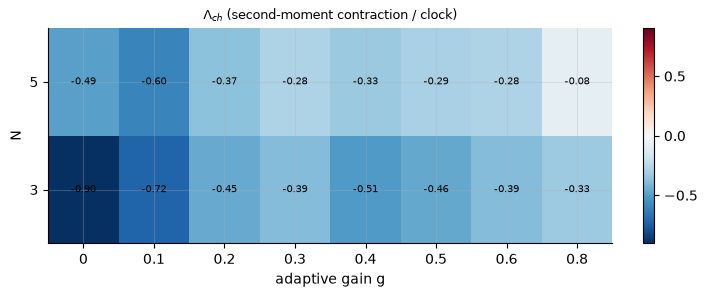

**Fig5_channel_exponent_map.** Mean over realizations (3 realizations per cell, 2048 trajectories, 200 clocks); 'div' = at least one realization diverged (non-fading).

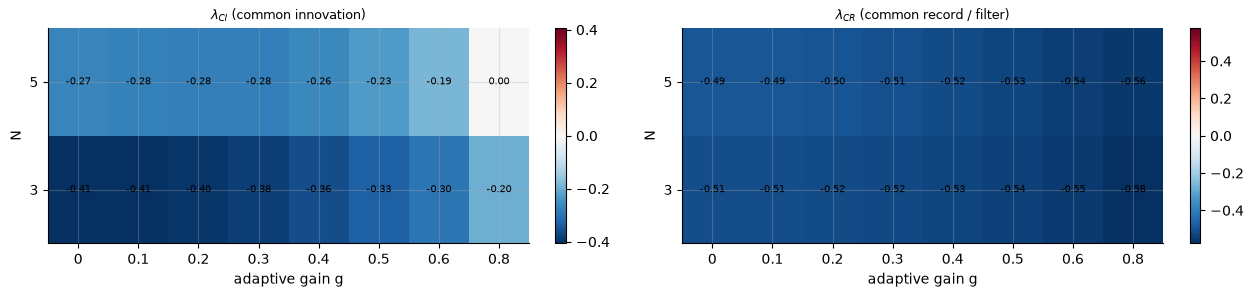

**Fig6_trajectory_exponent_map.** Benettin exponents per clock, averaged over trajectories and realizations (3 realizations per cell, 2048 trajectories, 200 clocks). CI and CR are different couplings: CI shares innovations (synthetic), CR is filter stability.

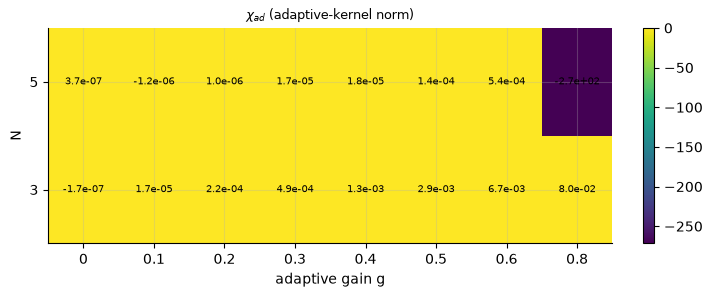

**Fig7_adaptive_susceptibility_map.** U-statistic estimate (unbiased; can be negative from noise), 4096 CRN paths in 16 blocks per realization, 3 realizations; g=0 column is the Monte Carlo null (exact value 0 by Theorem 2).

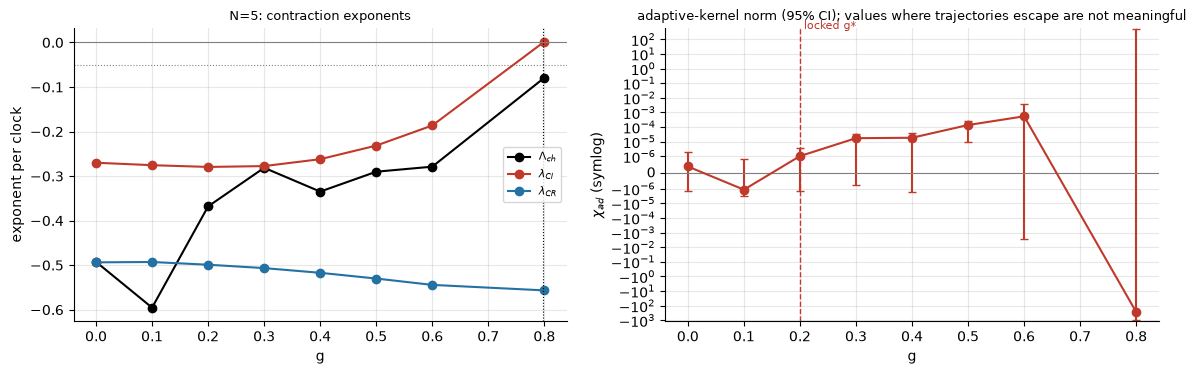

**Fig8_inferred_adaptive_boundary.** N=5, 3 realizations per cell, 2048 trajectories, 200 clocks. Dashed: zero crossing of Lambda_ch (ensemble edge); dotted: zero crossing of lambda_CI (trajectory edge), when inside the scanned range. Error bars: 95% CI from max(Monte Carlo jackknife, between-realization) SE. Single-size crossovers are finite-size adaptive crossovers, not phase transitions.

In [18]:
if RUN_MODE != "unit" and len(AGG):
    def heat(ax, col, title, cmap, center=None, fmt="{:.2f}"):
        piv = AGG.pivot(index="N", columns="g", values=col); vals = piv.values.astype(float); vv = np.where(np.isfinite(vals), vals, np.nan)
        lim = np.nanmax(np.abs(vv)) if center is not None else None
        im = ax.imshow(vv, aspect="auto", cmap=cmap, vmin=-lim if lim else None, vmax=lim if lim else None, origin="lower")
        ax.set_xticks(range(len(piv.columns)), [f"{x:g}" for x in piv.columns]); ax.set_yticks(range(len(piv.index)), piv.index)
        for i in range(vals.shape[0]):
            for j in range(vals.shape[1]):
                ax.text(j, i, "div" if not np.isfinite(vals[i, j]) else fmt.format(vals[i, j]), ha="center", va="center", fontsize=7)
        ax.set_xlabel("adaptive gain g"); ax.set_ylabel("N"); ax.set_title(title, fontsize=9); plt.colorbar(im, ax=ax, fraction=0.04)
    cap_n = f"{CFG['diag_realizations']} realizations per cell, {CFG['diag_trajectories']} trajectories, {CFG['diag_steps']} clocks"
    fig, ax = plt.subplots(figsize=(8, 2.8)); heat(ax, "Lambda_ch", r"$\Lambda_{ch}$ (second-moment contraction / clock)", "RdBu_r", center=0)
    show_fig(fig, "Fig5_channel_exponent_map", f"Mean over realizations ({cap_n}); 'div' = at least one realization diverged (non-fading).")
    fig, axs = plt.subplots(1, 2, figsize=(15, 2.8)); heat(axs[0], "lambda_CI", r"$\lambda_{CI}$ (common innovation)", "RdBu_r", center=0)
    heat(axs[1], "lambda_CR", r"$\lambda_{CR}$ (common record / filter)", "RdBu_r", center=0)
    show_fig(fig, "Fig6_trajectory_exponent_map", f"Benettin exponents per clock, averaged over trajectories and realizations ({cap_n}). CI and CR are different "
             "couplings: CI shares innovations (synthetic), CR is filter stability.")
    fig, ax = plt.subplots(figsize=(8, 2.8)); heat(ax, "chi", r"$\chi_{ad}$ (adaptive-kernel norm)", "viridis", fmt="{:.1e}")
    show_fig(fig, "Fig7_adaptive_susceptibility_map", f"U-statistic estimate (unbiased; can be negative from noise), {CFG['kernel_trajectories']} CRN paths in 16 blocks per "
             f"realization, {CFG['diag_realizations']} realizations; g=0 column is the Monte Carlo null (exact value 0 by Theorem 2).")
    a = AGG[AGG.N == CFG["N_main"]].sort_values("g")
    fig, axs = plt.subplots(1, 2, figsize=(14, 3.8))
    ax = axs[0]
    for col, lab, cc in (("Lambda_ch", r"$\Lambda_{ch}$", "k"), ("lambda_CI", r"$\lambda_{CI}$", COL["AD"]), ("lambda_CR", r"$\lambda_{CR}$", COL["NA"])):
        ax.plot(a.g, np.where(np.isfinite(a[col]), a[col], np.nan), "o-", color=cc, label=lab)
    ax.axhline(0, color="gray", lw=0.8); ax.axhline(-PREREGISTERED["channel_margin"], color="gray", lw=0.8, ls=":")
    for key, ls in (("g_edge_channel", "--"), ("g_edge_traj_CI", ":")):
        if LOCK[key] is not None:
            ax.axvline(LOCK[key], color="k", ls=ls, lw=0.8)
    ax.set_xlabel("g"); ax.set_ylabel("exponent per clock"); ax.legend(fontsize=8); ax.set_title(f"N={CFG['N_main']}: contraction exponents", fontsize=9)
    ax = axs[1]; ax.errorbar(a.g, a.chi, yerr=1.96 * a.chi_se, fmt="o-", color=COL["AD"], capsize=3); ax.axhline(0, color="gray", lw=0.8)
    if G_STAR is not None:
        ax.axvline(G_STAR, color=COL["AD"], ls="--", lw=1); ax.text(G_STAR, ax.get_ylim()[1] * 0.9, " locked g*", color=COL["AD"], fontsize=8)
    ax.set_yscale("symlog", linthresh=1e-6); ax.set_xlabel("g"); ax.set_ylabel(r"$\chi_{ad}$ (symlog)")
    ax.set_title("adaptive-kernel norm (95% CI); values where trajectories escape are not meaningful", fontsize=9)
    show_fig(fig, "Fig8_inferred_adaptive_boundary", f"N={CFG['N_main']}, {cap_n}. Dashed: zero crossing of Lambda_ch (ensemble edge); dotted: zero crossing of "
             "lambda_CI (trajectory edge), when inside the scanned range. Error bars: 95% CI from max(Monte Carlo jackknife, between-realization) SE. "
             "Single-size crossovers are finite-size adaptive crossovers, not phase transitions.")

## 10. Validation and unit tests

### 10.1 Statistical machinery (defined before it is tested)
* **Unit of analysis.** A realization: one reservoir draw ($\alpha,\beta$, CV networks) with its own inputs and innovations. All comparisons are paired within a realization.
* **Test.** One-sided paired $t$-test on realization means of $\Delta$, with Holm's correction over $\{H_A,H_B\}$ at family-wise $\alpha$.
* **Confidence interval.** Hierarchical percentile bootstrap: resample realizations, then resample the input × innovation replicates within each resampled realization. Shot noise and readout-fit noise are inside every replicate, because each replicate draws new shots and refits its readout. Their variance therefore propagates through the replicate level, and it is also estimated separately by the nested variance-component analysis used for power.
* **Effect size.** Standardized effect $d=\bar\Delta/\mathrm{sd}(\text{realization means})$, and $P(\Delta>\delta_{\min})$ as the bootstrap fraction.

In [19]:
def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); adj = np.empty_like(p); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, min(1.0, (len(p) - rank) * p[i])); adj[i] = run
    return adj

def paired_onesided(D):
    """D: (R, J) realization x replicate differences. Returns (mean, t, one-sided p) on realization means."""
    m = np.nanmean(D, 1); m = m[np.isfinite(m)]; n = len(m)
    if n < 2:
        return float(np.mean(m)) if n else np.nan, np.nan, np.nan
    se = m.std(ddof=1) / np.sqrt(n); t = m.mean() / se if se > 0 else np.inf * np.sign(m.mean())
    return float(m.mean()), float(t), float(sst.t.sf(t, n - 1))

def hier_bootstrap(D, B, rng):
    R, J = D.shape; out = np.empty(B)
    for b in range(B):
        rr = rng.integers(0, R, R); jj = rng.integers(0, J, (R, J))
        out[b] = np.nanmean(D[rr[:, None], jj])
    return out

def variance_components(D3):
    """Nested random-effects moments for (R, I, J) = realization x input x innovation replicate: (s2_real, s2_input, s2_rep)."""
    R, I, J = D3.shape
    s2_rep = float(np.nanmean(np.nanvar(D3, axis=2, ddof=1))) if J > 1 else 0.0
    mi = np.nanmean(D3, 2); s2_inp = max(0.0, float(np.nanmean(np.nanvar(mi, axis=1, ddof=1))) - s2_rep / J) if I > 1 else 0.0
    mr = np.nanmean(mi, 1); s2_real = max(0.0, float(np.nanvar(mr, ddof=1)) - (s2_inp + s2_rep / J) / I) if R > 1 else 0.0
    return s2_real, s2_inp, s2_rep

def analyse(D, delta_min, B, rng):
    mean, t, p = paired_onesided(D); boot = hier_bootstrap(D, B, rng); m = np.nanmean(D, 1)
    return dict(n_realizations=int(np.isfinite(m).sum()), mean=mean, ci_low=float(np.percentile(boot, 2.5)), ci_high=float(np.percentile(boot, 97.5)),
                d=float(mean / np.nanstd(m, ddof=1)) if np.nanstd(m, ddof=1) > 0 else np.nan, t=t, p_one_sided=p,
                P_exceeds_delta_min=float((boot > delta_min).mean()), median=float(np.nanmedian(m)))

def power_holm(deltas, comps, rho, n, I, J, alpha, sims, rng):
    """Monte Carlo power of the preregistered analysis (paired one-sided t on realization means, Holm over 2) under a nested
    normal model with variance components comps[c] = (s2_real, s2_input, s2_rep) and between-comparison correlation rho."""
    v = [c[0] + c[1] / I + c[2] / (I * J) for c in comps]; cov = np.array([[v[0], rho * np.sqrt(v[0] * v[1])], [rho * np.sqrt(v[0] * v[1]), v[1]]])
    m = rng.multivariate_normal(deltas, cov, size=(sims, n))                       # (sims, n, 2) realization means
    t = m.mean(1) / (m.std(1, ddof=1) / np.sqrt(n)); p = sst.t.sf(t, n - 1)
    rej = np.zeros_like(p, bool)
    for s in range(sims):
        rej[s] = holm(p[s]) < alpha
    return float(rej[:, 0].mean()), float(rej[:, 1].mean()), float(rej.all(1).mean())

### 10.2 Remaining physics, numerical, statistical and engine tests
Engine-level tests P1–P13, N1, N3 and P7 ran in §5, and the selection-rule tests ran in §8.

In [20]:
with section("10 validation suite"):
    rng = rng_for("suite")
    # P3 physicality along conditional AD trajectories, NA unconditional, CV ----------------------------------------------
    r3 = make_mb(0, CFG["N_main"], cond_of(squeezing_db=10.0)); D3d = r3.dev(np); n3 = D3d["n"]; M3 = 64
    Gam = np.broadcast_to(np.eye(n3), (M3, n3, n3)).copy(); mu = np.zeros((M3, n3)); y = np.zeros((M3, r3.N)); u3 = input_sequence(0, 3, 150)
    Gu = np.eye(n3); zr = rng_for("phys"); worst_eig = np.inf
    for k in range(150):
        ds = D3d["alpha"] * u3[k] + 0.5 * np.tanh(y)
        GCC, GCV, GVV, mC, mV = _moments(D3d, np, Gam, mu, ds)
        y = mV + (np.linalg.cholesky(GVV) @ zr.standard_normal((M3, r3.N))[..., None])[..., 0]
        Gam, mu = _update(np, GCC, GCV, GVV, mC, mV, y)
        XCu = r3.XC0 + np.tensordot(D3d["alpha"] * u3[k], r3.dXC, 1); Gu = XCu @ Gu @ XCu.T + r3.YCC
        if k % 10 == 0:
            worst_eig = min(worst_eig, np.linalg.eigvalsh(Gam + 1j * omega(r3.N)).min(), np.linalg.eigvalsh(Gu + 1j * omega(r3.N)).min())
    cvp = make_cv(0, CFG["N_main"], cond_of()); sig = np.eye(2 * CFG["N_main"])
    for k in range(100):
        sig = cvp.S1 @ (cvp.R * sig + (1 - cvp.R) * cvp.sigma_anc(u3[k])[0]) @ cvp.S1.T
    worst_eig = min(worst_eig, np.linalg.eigvalsh(sig + 1j * omega(CFG["N_main"])).min())
    record_test("P3", "physics", "Gamma + i Omega >= 0: conditional AD trajectories (g=0.5, 10 dB), NA unconditional, CV loop (min eigenvalue)",
                worst_eig, ">= -1e-9", worst_eig >= -1e-9)
    # P4 homodyne law: normalization and sampled outcomes ----------------------------------------------------------------
    GVV0 = (r3.XV0 @ r3.XV0.T + r3.YVV + r3.sig2 * np.eye(r3.N)); xs = np.linspace(-12, 12, 4001) * np.sqrt(GVV0[0, 0])
    norm1 = float(np.trapezoid(sst.norm.pdf(xs, 0, np.sqrt(GVV0[0, 0])), xs))
    o4 = mb_trajectories(r3, np.zeros(1) + 0.3, 0.0, rng_for("ks"), 4000, keep_y=True)
    XV1 = r3.XV0 + np.tensordot(D3d["alpha"] * 0.3, r3.dXV, 1); G1 = XV1 @ XV1.T + r3.YVV + r3.sig2 * np.eye(r3.N)
    w = np.linalg.solve(np.linalg.cholesky(G1), o4["y"][0].T).ravel(); ks_p = float(sst.kstest(w, "norm").pvalue)
    record_test("P4", "physics", "homodyne law: density integrates to 1; whitened sampled outcomes ~ N(0,1) (KS p-value)", f"int={norm1:.6f}, KS p={ks_p:.3f}",
                "|int-1|<1e-6 and p>1e-3", abs(norm1 - 1) < 1e-6 and ks_p > 1e-3)
    # P8 identity-channel limit; P9 deterministic (perfect-correlation) measurement limit ---------------------------------
    A0 = np.zeros((3, 3)); X8 = pg.gaussian_channel(mb_step_pattern(A0, np.zeros(3), 1.0, 1.5)).matrix[:6]
    e8 = np.abs(np.linalg.matrix_power(X8, 4) - np.eye(6)).max()
    record_test("P8", "physics", "identity limit: edgeless cluster, s=0, T=1 -> X_C = F per mode, X_C^4 = I", e8, "< 1e-12", e8 < 1e-12)
    rr = 2.0; tms = np.block([[np.cosh(2 * rr) * np.eye(2), np.sinh(2 * rr) * np.diag([1, -1])], [np.sinh(2 * rr) * np.diag([1, -1]), np.cosh(2 * rr) * np.eye(2)]])
    Gp, _ = _update(np, tms[:2, :2][None], tms[:2, 2:3][None], tms[2:3, 2:3][None], np.zeros((1, 2)), np.zeros((1, 1)), np.zeros((1, 1)))
    e9 = abs(Gp[0, 0, 0] - 1 / np.cosh(2 * rr))
    record_test("P9", "physics", "deterministic-measurement limit: EPR state, conditional Var(x) = 1/cosh(2r) -> 0 (analytic)", e9, "< 1e-12", e9 < 1e-12)
    # N2 seed reproducibility; N4 batch vs scalar / per-path input / complex code path ------------------------------------
    rN2 = make_mb(1, CFG["N_main"], cond_of()); uN2 = input_sequence(1, 0, 80)
    a1 = mb_trajectories(rN2, uN2, 0.4, rng_for("rep"), 64, shots_list=(64,)); a2 = mb_trajectories(rN2, uN2, 0.4, rng_for("rep"), 64, shots_list=(64,))
    record_test("N2", "numerical", "deterministic seed reproduction (bitwise identical features)", "identical" if np.array_equal(a1["raw"][64], a2["raw"][64]) and
                np.array_equal(a1["rb"], a2["rb"]) else "differ", "identical", np.array_equal(a1["raw"][64], a2["raw"][64]) and np.array_equal(a1["rb"], a2["rb"]))
    a3 = mb_trajectories(rN2, np.repeat(uN2[:, None], 64, 1), 0.4, rng_for("rep"), 64, shots_list=(64,))
    a4 = mb_trajectories(rN2, uN2, 0.4, rng_for("rep"), 64, shots_list=(64,), dtype=np.complex128)
    e4 = max(np.abs(a3["rb"] - a1["rb"]).max(), np.abs(a4["rb"].real - a1["rb"]).max()) / np.abs(a1["rb"]).max()
    record_test("N4", "numerical", "batch execution: per-path inputs and complex code path reproduce the scalar-input real run", e4, "< 1e-12", e4 < 1e-12)
    # N6 trajectory-count convergence; N7 shot-count convergence ----------------------------------------------------------
    rN6 = make_mb(0, CFG["N_main"], cond_of())
    se_small = ad_kernel_blocks(rN6, 0.4, (1, 3, 0, 1), 256, "conv", CFG["kernel_steps"], 0.1).std(0).mean()
    se_big = ad_kernel_blocks(rN6, 0.4, (1, 3, 0, 1), 1024, "conv2", CFG["kernel_steps"], 0.1).std(0).mean()
    record_test("N6", "numerical", "trajectory-count convergence: block-mean spread ratio for 4x more paths (expect 2 = M^-1/2)", se_small / se_big,
                "in [1.5, 2.7]", 1.5 <= se_small / se_big <= 2.7, critical=False)
    o7 = mb_trajectories(rN6, input_sequence(0, 1, 300), 0.4, rng_for("shots"), 1024, shots_list=(64, 256, 1024))
    dev = [np.sqrt(np.mean((o7["raw"][S][50:] - o7["rb"][50:]) ** 2)) for S in (64, 256, 1024)]
    sl = np.polyfit(np.log([64, 256, 1024]), np.log(dev), 1)[0]
    record_test("N7", "numerical", "shot-count convergence: raw-feature error vs RB estimate scales as S^slope (expect -0.5)", sl, "in [-0.65, -0.3]",
                -0.65 <= sl <= -0.3, critical=False)
    record_test("N8", "numerical", "Fock-cutoff convergence", "not applicable: all engines exactly Gaussian (FOCK_CUTOFF=None)", "n/a", True, critical=False)
    record_test("N9", "numerical", "time-step convergence", "not applicable: exact discrete-time channels, no integrator", "n/a", True, critical=False)
    # N10 checkpoint / resume equivalence ------------------------------------------------------------------------------------
    tmp = CKPT / "_resume_test"; shutil.rmtree(tmp, ignore_errors=True)
    unit = lambda i: dict(v=mb_trajectories(rN2, uN2[:30], 0.3, rng_for("ck", i), 16)["rb"])
    s1 = CheckpointStore(tmp / "a"); full = [s1.cached("u", dict(i=i), lambda i=i: unit(i)) for i in range(4)]
    s2 = CheckpointStore(tmp / "b"); part = []
    try:
        for i in range(4):
            if i == 2:
                raise KeyboardInterrupt("simulated interruption")
            part.append(s2.cached("u", dict(i=i), lambda i=i: unit(i)))
    except KeyboardInterrupt:
        pass
    s3 = CheckpointStore(tmp / "b"); resumed = [s3.cached("u", dict(i=i), lambda i=i: unit(i)) for i in range(4)]
    ok10 = all(np.array_equal(f["v"], r["v"]) for f, r in zip(full, resumed)) and s3.hits == 2 and s3.misses == 2
    record_test("N10", "numerical", "checkpoint/resume: interrupted after 2 of 4 units, resumed -> identical results, 2 hits + 2 recomputed",
                f"hits={s3.hits}, misses={s3.misses}", "identical, 2+2", ok10)
    shutil.rmtree(tmp, ignore_errors=True)
    # N11 non-finite / failed units are recorded, never silently removed ---------------------------------------------------
    bad = mb_trajectories(rN2, input_sequence(0, 2, 400), 0.6, rng_for("div"), 32, controller_scale=0.0, check_every=1)
    sc_bad, _ = readout_nmse(bad["rb"], make_targets(input_sequence(0, 2, 400), False), 50, 200)
    s4 = CheckpointStore(CKPT / "_fail_test", resume=False); f4 = s4.cached("x", {}, lambda: 1 / 0)
    ok11 = bad["diverged"] is not None and all(np.isnan(v) for v in sc_bad.values()) and f4.get("failed") and s4.failures == 1
    shutil.rmtree(CKPT / "_fail_test", ignore_errors=True)
    record_test("N11", "numerical", "diverged trajectories -> NaN scores, failed units stored with reason and counted (no silent removal)",
                f"diverged at clock {bad['diverged']}, failure recorded={bool(f4.get('failed'))}", "flagged", ok11)
    # S1 leakage ------------------------------------------------------------------------------------------------------------
    uS = input_sequence(0, 4, 900); tS = make_targets(uS, False); XS = na_exact(make_mb(0, 3, cond_of()), uS)
    sa, la = readout_nmse(XS, tS, 100, 500); XS2 = XS.copy(); XS2[600:] = XS2[600:] * 7 + 3; sb, lb = readout_nmse(XS2, tS, 100, 500)
    ok1 = la == lb and max(PAD, 100) + 500 <= 600
    record_test("S1", "statistical", "no train/test leakage: corrupting test features leaves scaler and lambda selection unchanged; disjoint blocks",
                "unchanged" if ok1 else "changed", "unchanged", ok1)
    led = json.loads(LEDGER_PATH.read_text()) if LEDGER_PATH.exists() else {}
    ok2 = not (set(EXPLORATORY_SEED_BANK) & set(CONFIRMATORY_SEED_BANK)) and set(led.get("confirmatory", {})) <= {"confirmation"}
    record_test("S2", "statistical", "seed banks disjoint; confirmatory bank used by no stage other than the research confirmation (ledger)", f"overlap={len(set(EXPLORATORY_SEED_BANK) & set(CONFIRMATORY_SEED_BANK))}, "
                f"confirmatory stages={list(led.get('confirmatory', {}))}", "0, none", ok2)
    # S3 lock integrity ------------------------------------------------------------------------------------------------------
    def verify_lock(path):
        L_ = json.loads(Path(path).read_text()); h = L_.pop("sha256"); return hashlib.sha256(json.dumps(L_, sort_keys=True, default=str).encode()).hexdigest() == h
    tl = RES / "_lock_test.json"; L0 = dict(g_star=0.3, N_main=5); L0["sha256"] = hashlib.sha256(json.dumps(L0, sort_keys=True).encode()).hexdigest()
    tl.write_text(json.dumps(L0)); good = verify_lock(tl); L0["g_star"] = 0.5; tl.write_text(json.dumps(L0)); tampered = verify_lock(tl); tl.unlink()
    record_test("S3", "statistical", "lock manifest hash detects any post-lock retuning (tampered manifest rejected)", f"intact={good}, tampered accepted={tampered}",
                "True, False", good and not tampered)
    # S4-S7 synthetic calibration ----------------------------------------------------------------------------------------------
    Dsyn = 0.05 + rng.normal(0, 0.03, (12, 1)) + rng.normal(0, 0.02, (12, 4)); res4 = analyse(Dsyn, 0.03, 2000, rng)
    record_test("S4", "statistical", "paired analysis recovers an injected difference of 0.05 (inside 95% CI)", f"{res4['mean']:.4f} [{res4['ci_low']:.4f}, {res4['ci_high']:.4f}]",
                "0.05 in CI", res4["ci_low"] <= 0.05 <= res4["ci_high"])
    sds = []
    for _ in range(150):
        Dz = rng.normal(0, 0.03, (15, 1)) + rng.normal(0, 0.04, (15, 3)); sds.append(hier_bootstrap(Dz, 300, rng).std())
    se_true = np.sqrt(0.03 ** 2 / 15 + 0.04 ** 2 / 45)
    record_test("S5", "statistical", "hierarchical bootstrap SE / analytic nested SE (15 realizations x 3 replicates)", np.mean(sds) / se_true, "in [0.85, 1.15]",
                0.85 <= np.mean(sds) / se_true <= 1.15)
    sims = 4000; m0 = rng.multivariate_normal([0, 0], [[1, 0.5], [0.5, 1]], size=(sims, 10)); t0_ = m0.mean(1) / (m0.std(1, ddof=1) / np.sqrt(10))
    p0 = sst.t.sf(t0_, 9); fwer = float(np.mean([(holm(p) < PREREGISTERED["alpha"]).any() for p in p0]))
    record_test("S6", "statistical", "null calibration: family-wise false-positive rate of one-sided Holm over 2 comparisons (4000 null datasets)", fwer,
                f"<= {PREREGISTERED['alpha']} + 0.012", fwer <= PREREGISTERED["alpha"] + 0.012)
    pw = power_holm([0.03, 0.03], [(0.02 ** 2, 0, 0.0)] * 2, 0.0, 12, 1, 1, PREREGISTERED["alpha"], 4000, rng)
    nc = 0.03 / (0.02 / np.sqrt(12)); crit = sst.t.isf(PREREGISTERED["alpha"] / 2, 11); pw_an = float(sst.nct.sf(crit, 11, nc))
    record_test("S7", "statistical", "injected effect recovered: simulated Holm power vs noncentral-t lower bound (alpha/2 per test)", f"sim {pw[0]:.3f} vs bound {pw_an:.3f}",
                "sim >= bound - 0.03", pw[0] >= pw_an - 0.03)

PASS [P3] (critical) Gamma + i Omega >= 0: conditional AD trajectories (g=0.5, 10 dB), NA unconditional, CV loop (min eigenvalue): 0.0159 (criterion >= -1e-9)
PASS [P4] (critical) homodyne law: density integrates to 1; whitened sampled outcomes ~ N(0,1) (KS p-value): int=1.000000, KS p=0.066 (criterion |int-1|<1e-6 and p>1e-3)
PASS [P8] (critical) identity limit: edgeless cluster, s=0, T=1 -> X_C = F per mode, X_C^4 = I: 1.22e-16 (criterion < 1e-12)
PASS [P9] (critical) deterministic-measurement limit: EPR state, conditional Var(x) = 1/cosh(2r) -> 0 (analytic): 2.06e-15 (criterion < 1e-12)
PASS [N2] (critical) deterministic seed reproduction (bitwise identical features): identical (criterion identical)
PASS [N4] (critical) batch execution: per-path inputs and complex code path reproduce the scalar-input real run: 1.07e-16 (criterion < 1e-12)


PASS [N6] trajectory-count convergence: block-mean spread ratio for 4x more paths (expect 2 = M^-1/2): 1.93 (criterion in [1.5, 2.7])


PASS [N7] shot-count convergence: raw-feature error vs RB estimate scales as S^slope (expect -0.5): -0.559 (criterion in [-0.65, -0.3])
PASS [N8] Fock-cutoff convergence: not applicable: all engines exactly Gaussian (FOCK_CUTOFF=None) (criterion n/a)
PASS [N9] time-step convergence: not applicable: exact discrete-time channels, no integrator (criterion n/a)
PASS [N10] (critical) checkpoint/resume: interrupted after 2 of 4 units, resumed -> identical results, 2 hits + 2 recomputed: hits=2, misses=2 (criterion identical, 2+2)
PASS [N11] (critical) diverged trajectories -> NaN scores, failed units stored with reason and counted (no silent removal): diverged at clock 5, failure recorded=True (criterion flagged)
PASS [S1] (critical) no train/test leakage: corrupting test features leaves scaler and lambda selection unchanged; disjoint blocks: unchanged (criterion unchanged)
PASS [S2] (critical) seed banks disjoint; confirmatory bank used by no stage other than the research confirmation (ledg

PASS [S5] (critical) hierarchical bootstrap SE / analytic nested SE (15 realizations x 3 replicates): 1.08 (criterion in [0.85, 1.15])
PASS [S6] (critical) null calibration: family-wise false-positive rate of one-sided Holm over 2 comparisons (4000 null datasets): 0.046 (criterion <= 0.05 + 0.012)
PASS [S7] (critical) injected effect recovered: simulated Holm power vs noncentral-t lower bound (alpha/2 per test): sim 0.999 vs bound 0.997 (criterion sim >= bound - 0.03)
[10 validation suite] 3.7 s | peak RSS 1170 MB


### 10.3 Engine table (17.4) and validation dashboard

In [21]:
def _tp(*ids):
    st = {t["id"]: t["passed"] for t in TESTS}; return "PASS" if all(st.get(i, False) for i in ids) else "FAIL"
ENGINE_TABLE = pd.DataFrame([
    ("Piquasso", pq.__version__, "PyPI 8.0.1", "CV-QRC round trip (Covariance, Squeezing, Beamsplitter, GaussianTransform, Attenuator, reduced)", "native", "P13", "1e-10 rel", _tp("P13")),
    ("Piquasso", pq.__version__, "PyPI 8.0.1", "vacuum covariance / quadrature normalization", "native", "P11", "1e-12", _tp("P11")),
    ("PhotoGraphiQ", pg.__version__, PG_INSTALLED_COMMIT[:12], "MB clock pattern -> pg.gaussian_channel (C_Z, rotated homodyne, Outcome byproduct, BS, Loss)", "compiled through the engine", "P1, P2, P5", "1e-11", _tp("P1", "P2", "P5")),
    ("PhotoGraphiQ", pg.__version__, PG_INSTALLED_COMMIT[:12], "finite-squeezing noise and r->inf limit", "idealized (exact extraction)", "P6", "1e-11", _tp("P6")),
    ("PhotoGraphiQ", pg.__version__, PG_INSTALLED_COMMIT[:12], "adaptive Homodyne(atan2(1, s0 + g c tanh(Outcome)))) via pg.run_shots (Piquasso gates)", "native", "N3b", "|z| < 4", _tp("N3b")),
    ("PhotoGraphiQ", pg.__version__, PG_INSTALLED_COMMIT[:12], "GaussianBackend.measure (homodyne conditioning, efficiency)", "native (reference)", "P12", "1e-10", _tp("P12")),
    ("notebook", ENGINE_VERSION, "-", "batched Kalman conditioning + adaptive basis selection (mb_trajectories)", "exact external adapter", "P12, N3b, P7a-c, N4", "see tests", _tp("P12", "N3b", "P7a", "P7b", "P7c", "N4")),
    ("notebook", ENGINE_VERSION, "-", "CV covariance recursion and Gaussian shot sampling", "exact external adapter", "P13, N7", "1e-10 / slope", _tp("P13")),
    ("notebook", ENGINE_VERSION, "-", "analytic U = C_Z F D(s) (independent reference)", "exact external adapter", "P1, N3a", "1e-10", _tp("P1", "N3a")),
], columns=["package", "version", "commit", "operation", "label", "reference test", "tolerance", "result"])
with pd.option_context("display.max_colwidth", 90, "display.width", 260):
    display(ENGINE_TABLE)
TESTS_DF = pd.DataFrame(TESTS)
with pd.option_context("display.max_colwidth", 110, "display.width", 260, "display.max_rows", 200):
    display(TESTS_DF[["id", "category", "critical", "passed", "value", "criterion", "description"]])
CRITICAL_FAILS = TESTS_DF[(TESTS_DF.critical) & (~TESTS_DF.passed)].id.tolist()
print(f"{len(TESTS_DF)} tests | {int(TESTS_DF.passed.sum())} passed | critical failures: {CRITICAL_FAILS or 'none'}")

,package,version,commit,operation,label,reference test,tolerance,result
0,Piquasso,8.0.1,PyPI 8.0.1,"CV-QRC round trip (Covariance, Squeezing, Beamsplitter, GaussianTransform, Attenuator,...",native,P13,1e-10 rel,PASS
1,Piquasso,8.0.1,PyPI 8.0.1,vacuum covariance / quadrature normalization,native,P11,1e-12,PASS
2,PhotoGraphiQ,0.3.1,6d49da06fa6e,"MB clock pattern -> pg.gaussian_channel (C_Z, rotated homodyne, Outcome byproduct, BS,...",compiled through the engine,"P1, P2, P5",1e-11,PASS
3,PhotoGraphiQ,0.3.1,6d49da06fa6e,finite-squeezing noise and r->inf limit,idealized (exact extraction),P6,1e-11,PASS
4,PhotoGraphiQ,0.3.1,6d49da06fa6e,"adaptive Homodyne(atan2(1, s0 + g c tanh(Outcome)))) via pg.run_shots (Piquasso gates)",native,N3b,|z| < 4,PASS
5,PhotoGraphiQ,0.3.1,6d49da06fa6e,"GaussianBackend.measure (homodyne conditioning, efficiency)",native (reference),P12,1e-10,PASS
6,notebook,admb-1.2,-,batched Kalman conditioning + adaptive basis selection (mb_trajectories),exact external adapter,"P12, N3b, P7a-c, N4",see tests,PASS
7,notebook,admb-1.2,-,CV covariance recursion and Gaussian shot sampling,exact external adapter,"P13, N7",1e-10 / slope,PASS
8,notebook,admb-1.2,-,analytic U = C_Z F D(s) (independent reference),exact external adapter,"P1, N3a",1e-10,PASS


,id,category,critical,passed,value,criterion,description
0,P1,physics,True,True,4.44e-16,< 1e-12,"PhotoGraphiQ channel = analytic sqrt(T eta_L) C_Z F D(s) (chain/ring, with loss); U symplectic"
1,P2,physics,True,True,8.88e-16,< 1e-11,"X(s) affine in every s_i and Y independent of s (incl. loss 0.9, ff gain error 0.03; premise of §7)"
2,P5,physics,True,True,4.44e-16,< 1e-12,"analytic loss: native Loss Gamma -> eta Gamma + (1-eta) I; compiled loop loss = sqrt(eta) X_C, eta Y + (1-..."
3,P6,physics,True,True,1.11e-16,< 1e-11,finite-squeezing noise exactly Y0 + e^{-2r} Y1 (ideal limit Y0 extracted exactly)
4,P10,physics,True,True,75.5,> 5,feedforward sign: q=-m keeps the noise O(1); the reversed sign floods it (ratio)
5,P11,physics,True,True,0,< 1e-12,quadrature normalization: vacuum Gamma = I (PhotoGraphiQ; Piquasso hbar=2 covariance/2)
6,P12,engine,True,True,4.44e-16,< 1e-10,"adapter Gaussian conditioning = native GaussianBackend.measure (replayed outcomes, eta_D=0.9)"
7,P13,engine,True,True,4.04e-16,< 1e-10,"CV-QRC recursion = 12 native Piquasso round trips (loss 0.95, eta_D 0.9), relative"
8,N3a,numerical,True,True,1.83e-16,< 1e-10,independent analytic-U NA recursion (ideal squeezing) = PhotoGraphiQ-channel NA features
9,N3b,engine,True,True,1.4,< 4,"native PhotoGraphiQ ADAPTIVE trajectories (600 shots, Piquasso gates, outcome-dependent angles) = adapter ..."


42 tests | 42 passed | critical failures: none


## 11. Preflight pilot experiment

The witness family, the primary comparison, the readout policy and $g^\star$ are frozen (lock manifest, §9) **before** any task score is computed below. The pilot is small and paired:

- realizations × input sequences × innovation replicates, as set in the control panel;
- AD and NA share every random number;
- CV-QRC shares inputs and train/test partitions.

It estimates direction, effect size and the nested variance components. It does not estimate confirmation. Preflight language is restricted to "implementation validated", "pilot effect has / does not have the predicted sign", and "pilot did not resolve the predicted effect".

In [22]:
def score_set(X, T_, W, Ltr, full=True):
    sc, lam = readout_nmse(X, T_ if full else {k: T_[k] for k in T_ if k == "witness" or k.startswith("K*")}, W, Ltr)
    out = summarize_scores(sc); out["lambda_witness"] = lam.get("witness", np.nan); return out

def pilot_unit(rid, N, g, i_inp, rep, cond, M, shots_list, angle_noise=0.0, light=False):
    W, Ltr, Lte = CFG["washout"], CFG["train"], CFG["test"]; K = W + Ltr + Lte
    res = make_mb(rid, N, cond); u = input_sequence(rid, i_inp, K); T_ = make_targets(u, secondary=not light); Sp = CFG["shots_primary"]
    kw = dict(xp=DEVICE["pilot"], shots_list=shots_list, angle_noise=angle_noise, angle_rng=rng_for("angle", rid, i_inp, rep) if angle_noise else None)
    t0 = time.perf_counter(); ad = mb_trajectories(res, u, g, rng_for("z", rid, i_inp, rep), M, **kw); t_ad = time.perf_counter() - t0
    kw["angle_rng"] = rng_for("angle", rid, i_inp, rep) if angle_noise else None
    na = mb_trajectories(res, u, 0.0, rng_for("z", rid, i_inp, rep), M, **kw)
    out = dict(rid=rid, N=N, g=g, inp=i_inp, rep=rep, t_ad=t_ad, sec_per_path_step=t_ad / (K * M), diverged_AD=ad["diverged"], diverged_NA=na["diverged"])
    sets = {"AD": ad["raw"][Sp], "NA": na["raw"][Sp], "AD_rb": ad["rb"], "NA_rb": na["rb"]}
    if not light:
        cv = make_cv(rid, N, cond); Fcv, covs = cv.exact(u, return_cov=True); sets["CV_exact"] = Fcv
        sets["CV"] = cv.shots(covs, Sp, rng_for("cvshots", rid, i_inp, rep))
        cvp = CVReservoir(N, cv.R, ((cv.S1, cv.P1, cv.A1), (cv.S2, cv.P2, cv.A2)), cv.loss, cv.eta_det, r_in=r_pg_from_db(cond["squeezing_db"]) if np.isfinite(cond["squeezing_db"]) else 3.0)
        _, covp = cvp.exact(u, return_cov=True); sets["CV_photon"] = cvp.shots(covp, Sp, rng_for("cvshots-p", rid, i_inp, rep))
        sets["NA_exact"] = na_exact(res, u)
    t1 = time.perf_counter()
    for name, X in sets.items():
        out[name] = score_set(X, T_, W, Ltr, full=not light and name in ("AD", "NA", "CV", "AD_rb", "NA_exact", "CV_exact"))
    out["t_score"], out["n_scored"] = time.perf_counter() - t1, len(sets)
    if not light:                                  # regularization sensitivity: witness NMSE at every fixed lambda of the grid
        out["witness_by_lambda"] = {m: [readout_nmse(sets[m], {"witness": T_["witness"]}, W, Ltr, fixed_lambda=l)[0]["witness"] for l in CFG["ridge_grid"]]
                                    for m in ("AD", "NA", "CV")}
    for S in shots_list:
        if S != Sp:
            out[f"AD@{S}"] = score_set(ad["raw"][S], T_, W, Ltr, full=False); out[f"NA@{S}"] = score_set(na["raw"][S], T_, W, Ltr, full=False)
    if not light:
        out["K*_capacity_AD_rb"] = {c: 1 - v for c, v in readout_nmse(ad["rb"], {f"K*{c}": T_[f"K*{c}"] for c in KSTAR}, W, Ltr)[0].items()}
    return out

PILOT, PILOT_G = [], None
if RUN_MODE in ("preflight", "research", "research_dryrun") and CFG["pilot_realizations"] > 0:
    PILOT_G = G_STAR if G_STAR is not None else float(min(g for g in CFG["gain_grid"] if g > 0))
    if G_STAR is None:
        print(f"WARNING: no admissible g in the scanned range; pilot runs at the unlocked fallback g={PILOT_G} for information only")
    with section("11.1 pilot"):
        rids = EXPLORATORY_SEED_BANK[:CFG["pilot_realizations"]]
        for rid in rids:
            for i_inp in range(CFG["n_inputs"]):
                for rep in range(CFG["n_innovation_reps"]):
                    params = dict(rid=rid, N=CFG["N_main"], g=PILOT_G, i=i_inp, rep=rep, M=CFG["trajectories"], S=CFG["shots_list"], Sp=CFG["shots_primary"],
                                  L=(CFG["washout"], CFG["train"], CFG["test"]), base=BASE, ctrl=PREREGISTERED["controller_scale"], lam=CFG["ridge_grid"])
                    r = STORE.cached("pilot", params, lambda: pilot_unit(rid, CFG["N_main"], PILOT_G, i_inp, rep, cond_of(), CFG["trajectories"], CFG["shots_list"]))
                    if r.get("failed"):
                        FAILED_UNITS.append(dict(stage="pilot", rid=rid, inp=i_inp, rep=rep, reason=r["reason"])); continue
                    PILOT.append(r)
        ledger_use("pilot", "exploratory", range(CFG["pilot_realizations"]))
    PILOT_EXCLUDED = [dict(rid=p["rid"], inp=p["inp"], rep=p["rep"], diverged_AD=p["diverged_AD"], diverged_NA=p["diverged_NA"],
                           nonfinite=[m for m in ("AD", "NA", "CV") if not np.isfinite(p[m]["witness"])]) for p in PILOT
                      if p["diverged_AD"] is not None or p["diverged_NA"] is not None or not all(np.isfinite(p[m]["witness"]) for m in ("AD", "NA", "CV"))]
    print(f"pilot units: {len(PILOT)} (failed: {sum(1 for f in FAILED_UNITS if f['stage'] == 'pilot')}); units excluded from the analysis "
          f"(diverged or non-finite, listed, never silently dropped): {len(PILOT_EXCLUDED)}")
    if PILOT_EXCLUDED:
        display(pd.DataFrame(PILOT_EXCLUDED))

def pilot_array(models_a, model_b, metric="witness", units=None):
    """(R, I, J) array of metric[model_a] - metric[model_b] (positive = model_b better for NMSE metrics)."""
    units = PILOT if units is None else units
    rids = sorted({p["rid"] for p in units}); I = 1 + max(p["inp"] for p in units); J = 1 + max(p["rep"] for p in units)
    A = np.full((len(rids), I, J), np.nan)
    for p in units:
        if models_a in p and model_b in p:
            A[rids.index(p["rid"]), p["inp"], p["rep"]] = p[models_a][metric] - p[model_b][metric]
    return A

if PILOT:
    rngp = rng_for("pilot-analysis"); dA, dB = PREREGISTERED["delta_min_A"], PREREGISTERED["delta_min_B"]
    DA, DB = pilot_array("NA", "AD"), pilot_array("CV", "AD")
    PA = analyse(DA.reshape(len(DA), -1), dA, CFG["bootstrap"], rngp); PB = analyse(DB.reshape(len(DB), -1), dB, CFG["bootstrap"], rngp)
    padj = holm([PA["p_one_sided"], PB["p_one_sided"]]); PA["p_holm"], PB["p_holm"] = padj
    DA_rb, DB_rb = pilot_array("NA_exact", "AD_rb"), pilot_array("CV_exact", "AD_rb")
    PA_rb = analyse(DA_rb.reshape(len(DA_rb), -1), dA, CFG["bootstrap"], rngp); PB_rb = analyse(DB_rb.reshape(len(DB_rb), -1), dB, CFG["bootstrap"], rngp)
    DC = pilot_array("NA", "AD", metric="Cstar") * -1                                      # capacity: AD - NA (higher is better)
    PC = analyse(DC.reshape(len(DC), -1), 0.0, CFG["bootstrap"], rngp)
    PILOT_SUMMARY = pd.DataFrame({"H_A primary: NA - AD (raw)": PA, "H_B primary: CV - AD (raw)": PB, "NA_exact - AD_rb (ideal features)": PA_rb,
                                  "CV_exact - AD_rb (ideal features)": PB_rb, "C* capacity AD - NA (raw)": PC}).T
    display(PILOT_SUMMARY.round(5))
    VC_A, VC_B = variance_components(DA), variance_components(DB)
    mA, mB = np.nanmean(DA, (1, 2)), np.nanmean(DB, (1, 2)); fin = np.isfinite(mA) & np.isfinite(mB)
    RHO_AB = float(np.corrcoef(mA[fin], mB[fin])[0, 1]) if fin.sum() > 2 else 0.5
    print("variance components (realization, input, innovation/shot/readout):", "A:", np.round(VC_A, 7), "B:", np.round(VC_B, 7), "| rho_AB =", round(RHO_AB, 3))
    rows = []
    for m in ("AD", "NA", "CV", "CV_photon", "AD_rb", "NA_rb", "NA_exact", "CV_exact"):
        vals = pd.DataFrame([p[m] for p in PILOT if m in p]); rows.append(dict(model=m, **{c: vals[c].mean() for c in vals.columns if c != "lambda_witness"}))
    SCORES_DF = pd.DataFrame(rows).set_index("model"); display(SCORES_DF.round(4))

[11.1 pilot] 663.2 s | peak RSS 1170 MB
pilot units: 40 (failed: 0); units excluded from the analysis (diverged or non-finite, listed, never silently dropped): 2


,rid,inp,rep,diverged_AD,diverged_NA,nonfinite
0,10006,1,0,540,None,[AD]
1,10006,1,1,430,None,[AD]


,n_realizations,mean,ci_low,ci_high,d,t,p_one_sided,P_exceeds_delta_min,median,p_holm
H_A primary: NA - AD (raw),10.0,-0.00033,-0.00112,0.00075,-0.17471,-0.55248,0.70296,0.000,-0.00006,1.0
H_B primary: CV - AD (raw),10.0,-0.00174,-0.00544,0.00173,-0.33652,-1.06416,0.84251,0.000,-0.00211,1.0
NA_exact - AD_rb (ideal features),10.0,0.00056,-0.00088,0.00278,0.18423,0.58260,0.28723,0.000,-0.00001,NaN
CV_exact - AD_rb (ideal features),10.0,-0.00126,-0.00459,0.00140,-0.28210,-0.89209,0.80222,0.000,-0.00126,NaN
C* capacity AD - NA (raw),10.0,0.00148,-0.00205,0.00785,0.16678,0.52741,0.30533,0.834,0.00081,NaN


variance components (realization, input, innovation/shot/readout): A: [3.0e-06 1.0e-07 2.2e-06] B: [5.20e-06 3.11e-05 2.45e-05] | rho_AB = -0.175


C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\ipykernel_21172\3980276493.py:25: RuntimeWarning: Degrees of freedom <= 0 for slice.
  s2_rep = float(np.nanmean(np.nanvar(D3, axis=2, ddof=1))) if J > 1 else 0.0
C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\ipykernel_21172\3980276493.py:26: RuntimeWarning: Mean of empty slice
  mi = np.nanmean(D3, 2); s2_inp = max(0.0, float(np.nanmean(np.nanvar(mi, axis=1, ddof=1))) - s2_rep / J) if I > 1 else 0.0
C:\Users\Tonmoy Biswas Arko\AppData\Local\Temp\ipykernel_21172\3980276493.py:26: RuntimeWarning: Degrees of freedom <= 0 for slice.
  mi = np.nanmean(D3, 2); s2_inp = max(0.0, float(np.nanmean(np.nanvar(mi, axis=1, ddof=1))) - s2_rep / J) if I > 1 else 0.0


,witness,Cstar,NARMA5,NARMA10,"XOR(1,2)",parity3,MC
model,,,,,,,
AD,1.0077,-0.0418,0.6748,0.7789,0.8778,0.9575,2.0885
NA,1.0072,-0.0460,0.6728,0.7682,0.8658,0.9534,2.3289
CV,1.0054,-0.0380,0.7006,0.7692,1.0030,1.0034,2.4372
CV_photon,1.0057,-0.0337,NaN,NaN,NaN,NaN,NaN
AD_rb,1.0069,-0.0435,0.6413,0.7528,0.7769,0.9118,2.6612
NA_rb,1.0066,-0.0473,NaN,NaN,NaN,NaN,NaN
NA_exact,1.0074,-0.0504,0.6240,0.7325,0.6996,0.8722,3.2430
CV_exact,1.0052,-0.0302,0.2253,0.6473,1.0026,1.0029,7.3943


### 11.2 Negative controls and the classical post-processing disclosure
A genuine **causal adaptive** effect should vanish or weaken when causal measurement dependence is removed. Controls C1, C3, C5 and C6 remove every outcome-to-basis dependence acting on the reservoir. C2 keeps the outcome values but destroys their temporal alignment. **C4 is a mechanism diagnostic, preregistered before seeing data:** it replaces each copy's own outcome by the simultaneous outcome of an independent copy driven by the same input, so the input-dependent outcome statistics are kept and only the copy's own back-action correlation is removed. If C4 keeps the effect, the effect comes from feedforward of input-dependent measurement statistics, not from a copy's own conditional dynamics. §16 then words the claim accordingly. C7–C10 equalize resources for the baselines. D1 is a disclosure, not a control: it shows whether quadratic classical post-processing of NA features captures the witness.

| id | control | expected for a causal adaptive effect |
|---|---|---|
| C1 | adaptive gain $g=0$ ($=n_real{\mathrm{NA}}$) | vanishes (exact) |
| C2 | basis driven by a time-shuffled outcome record of an independent copy | vanishes |
| C3 | outcome-to-basis links removed, controller kept running (its output is discarded) | vanishes (identical to C1 in law) |
| C4 | own outcome replaced by an independent same-input copy's simultaneous outcome | diagnostic |
| C5 | nonadaptive schedule: i.i.d. draws from the pooled controller-output distribution | vanishes (Theorem 2 still holds: additive in $s$) |
| C6 | controller drives a future-disconnected extra mode only | vanishes (exact in law) |
| C7 | baselines given a second independent reservoir (2× features, 2× modes; exact features) | baselines stay at the floor |
| C8 | all models restricted to the $N$ diagonal features | — |
| C9 | readout parameter counts | equal by construction |
| C10 | hyperparameter budget | equal λ grid; $g^\star$ task-independent |
| D1 | NA exact features + all pairwise products (quadratic readout) | disclosure |

In [23]:
def control_unit(rid, N, g, cond, M):
    W, Ltr, Lte = CFG["washout"], CFG["train"], CFG["test"]; K = W + Ltr + Lte; Sp = CFG["shots_primary"]; c = PREREGISTERED["controller_scale"]
    res = make_mb(rid, N, cond); u = input_sequence(rid, 0, K); T_ = make_targets(u, secondary=False); xp = DEVICE["pilot"]
    zr = lambda: rng_for("z", rid, 0, 0); out = {}
    rec = mb_trajectories(res, u, g, rng_for("zrec", rid), M, xp=xp, keep_y=True)          # independent recording copy (same input)
    Yrec = rec["y"]; perm_t = rng_for("perm-t", rid).permutation(K)
    out["C2_time_shuffled"] = mb_trajectories(res, u, 0.0, zr(), M, xp=xp, shots_list=(Sp,), drive=lambda k: g * c * np.tanh(Yrec[perm_t[k]] / c))["raw"][Sp]
    out["C3_links_removed"] = mb_trajectories(res, u, 0.0, zr(), M, xp=xp, shots_list=(Sp,), drive=lambda k: 0.0 * Yrec[k])["raw"][Sp]
    out["C4_cross_copy"] = mb_trajectories(res, u, g, zr(), M, xp=xp, shots_list=(Sp,), perm=np.roll(np.arange(M), 1))["raw"][Sp]
    pool = (g * c * np.tanh(Yrec[W:] / c)).reshape(-1, res.N); pr = rng_for("pool", rid)
    out["C5_iid_matched_marginal"] = mb_trajectories(res, u, 0.0, zr(), M, xp=xp, shots_list=(Sp,),
                                                      drive=lambda k: pool[pr.integers(0, len(pool), (M, res.N)), np.arange(res.N)[None, :].repeat(M, 0)])["raw"][Sp]
    res_d = make_mb(rid, N, cond, dummy=True)
    out["C6_disconnected_target"] = mb_trajectories(res_d, u, g, zr(), M, xp=xp, shots_list=(Sp,), gain_to=N)["raw"][Sp]
    ex2 = na_exact(make_mb(rid + 7_000_000, N, cond), u); out["C7_NA_plus_extra_reservoir"] = np.c_[na_exact(res, u), ex2]
    cv, cv2 = make_cv(rid, N, cond), make_cv(rid + 7_000_000, N, cond); out["C7_CV_plus_extra_reservoir"] = np.c_[cv.exact(u), cv2.exact(u)]
    ad = mb_trajectories(res, u, g, zr(), M, xp=xp, shots_list=(Sp,))["raw"][Sp]; na = mb_trajectories(res, u, 0.0, zr(), M, xp=xp, shots_list=(Sp,))["raw"][Sp]
    dg = [i for i, (a, b) in enumerate(zip(*res.iu)) if a == b]
    out["AD"], out["NA"] = ad, na; out["C8_AD_diag"], out["C8_NA_diag"], out["C8_CV_diag"] = ad[:, dg], na[:, dg], cv.exact(u)[:, dg]
    ne = na_exact(res, u); Z = (ne - ne[W:W + Ltr].mean(0)) / ne[W:W + Ltr].std(0); ii, jj = np.triu_indices(Z.shape[1])
    out["D1_NA_quadratic_postprocessing"] = np.c_[ne, Z[:, ii] * Z[:, jj]]
    return {k: score_set(v, T_, W, Ltr, full=False) for k, v in out.items()}

CONTROLS = []
if PILOT and CFG["control_realizations"] > 0:
    with section("11.2 negative controls"):
        for rid in EXPLORATORY_SEED_BANK[:CFG["control_realizations"]]:
            r = STORE.cached("control", dict(rid=rid, N=CFG["N_main"], g=PILOT_G, M=CFG["trajectories"], Sp=CFG["shots_primary"],
                                             L=(CFG["washout"], CFG["train"], CFG["test"]), base=BASE, lam=CFG["ridge_grid"]),
                             lambda: control_unit(rid, CFG["N_main"], PILOT_G, cond_of(), CFG["trajectories"]))
            if r.get("failed"):
                FAILED_UNITS.append(dict(stage="control", rid=rid, reason=r["reason"])); continue
            CONTROLS.append(dict(rid=rid, **{k: v["witness"] for k, v in r.items()}, **{k + "|C*": v["Cstar"] for k, v in r.items()}))
    CTRL = pd.DataFrame(CONTROLS)
    ctrl_rows = []
    assert len(CTRL), "every negative-control unit failed; see FAILED_UNITS (reasons are stored, never dropped)"
    for k in [c for c in CTRL.columns if c not in ("rid",) and "|C*" not in c]:
        d = CTRL["NA"] - CTRL[k]; se = d.std(ddof=1) / np.sqrt(len(d)) if len(d) > 1 else np.nan
        ctrl_rows.append(dict(control=k, witness_NMSE=CTRL[k].mean(), improvement_vs_NA=d.mean(), se=se, z=d.mean() / se if se and se > 0 else np.nan,
                              Cstar=CTRL[k + "|C*"].mean()))
    CTRL_DF = pd.DataFrame(ctrl_rows).set_index("control"); display(CTRL_DF.round(5))
    zmax = PREREGISTERED["control_z_max"]                      # small n: use the Student-t quantile with the same two-sided level as |z| = zmax
    tmax = float(sst.t.isf(sst.norm.sf(zmax), max(1, len(CTRL) - 1)))
    kill = ["C2_time_shuffled", "C3_links_removed", "C5_iid_matched_marginal", "C6_disconnected_target"]
    CONTROLS_OK = all(abs(CTRL_DF.loc[k, "z"]) < tmax or not np.isfinite(CTRL_DF.loc[k, "z"]) for k in kill) and \
        all(CTRL_DF.loc[k, "witness_NMSE"] > 1 - min(PREREGISTERED["delta_min_A"], 0.02) for k in ("C7_NA_plus_extra_reservoir", "C7_CV_plus_extra_reservoir"))
    print(f"causal-destroying controls consistent with NA (|t| < {tmax:.2f}, the t_{len(CTRL) - 1} equivalent of |z| < {zmax}) and "
          f"resource-equalized baselines at the floor: {CONTROLS_OK}")
else:
    CTRL_DF, CONTROLS_OK = pd.DataFrame(), None

[11.2 negative controls] 326.6 s | peak RSS 1298 MB


,witness_NMSE,improvement_vs_NA,se,z,Cstar
control,,,,,
C2_time_shuffled,1.00769,-0.00016,0.00041,-0.37597,-0.04454
C3_links_removed,1.00753,0.00000,0.00000,NaN,-0.04553
C4_cross_copy,1.00791,-0.00038,0.00032,-1.18401,-0.04640
C5_iid_matched_marginal,1.00649,0.00105,0.00143,0.72978,-0.04635
C6_disconnected_target,1.00897,-0.00144,0.00404,-0.35580,-0.05152
C7_NA_plus_extra_reservoir,1.01062,-0.00309,0.00527,-0.58635,-0.08267
C7_CV_plus_extra_reservoir,1.00530,0.00224,0.00310,0.72102,-0.03032
AD,1.00823,-0.00069,0.00052,-1.33321,-0.04524
NA,1.00753,0.00000,0.00000,NaN,-0.04553


causal-destroying controls consistent with NA (|t| < 6.62, the t_4 equivalent of |z| < 3.0) and resource-equalized baselines at the floor: True


### 11.3 Figures 9–11 and 4b: witness performance, controls, resource Pareto, derivative/IPC cross-check

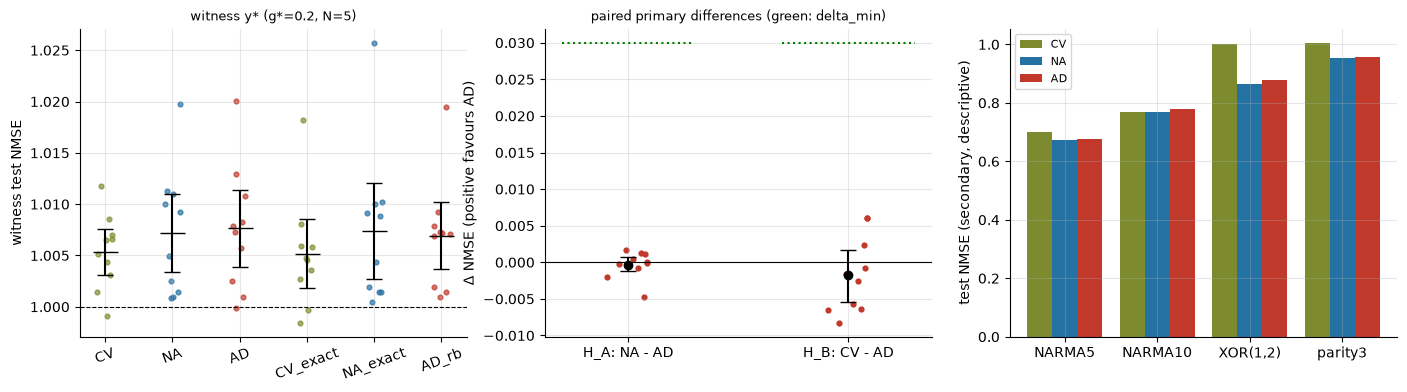

**Fig9_witness_performance.** Pilot: 10 realizations x 2 inputs x 2 innovation replicates (40 paired units), 512 shots, train/test 3000/1500. Points: realization means; black bars: mean +- 1.96 SE across realizations (left); hierarchical-bootstrap 95% CI (2000 resamples) (middle). Dashed line: baseline population floor NMSE = 1 (Theorems 1-2). '_exact'/'_rb' = ideal (infinite-shot) features. Right: secondary tasks, means only, not part of any claim.

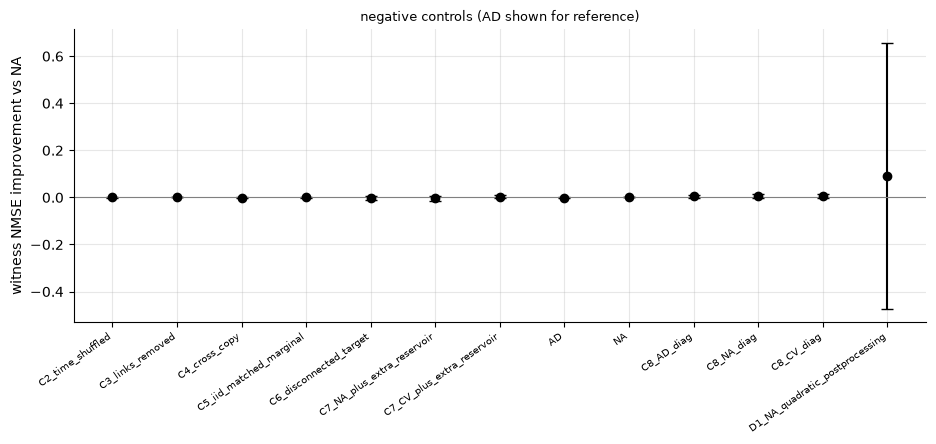

**Fig10_negative_controls.** 5 realizations (input 0, replicate 0), g=0.2; mean +- 1.96 SE of the paired difference to NA across realizations. C7 and D1 use exact (ideal) features, the most favourable setting for the baselines.

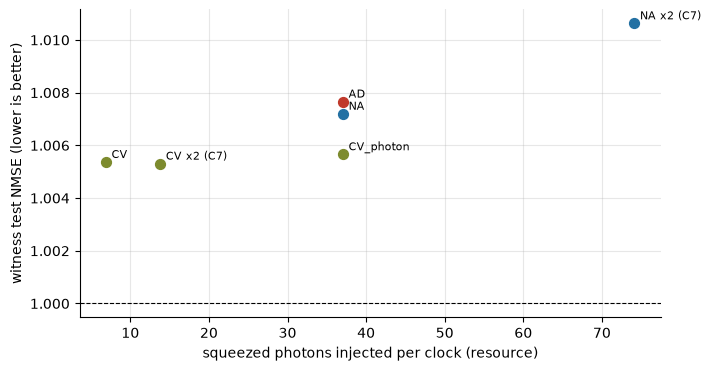

**Fig11_resource_pareto.** Witness NMSE against injected squeezing resource, pilot means. CV_photon has the MB squeezing budget (accounting 2); x2 = a second independent reservoir (2x modes and features). Dashed: baseline population floor. No error bars: means only (see Fig. 9 for uncertainty).

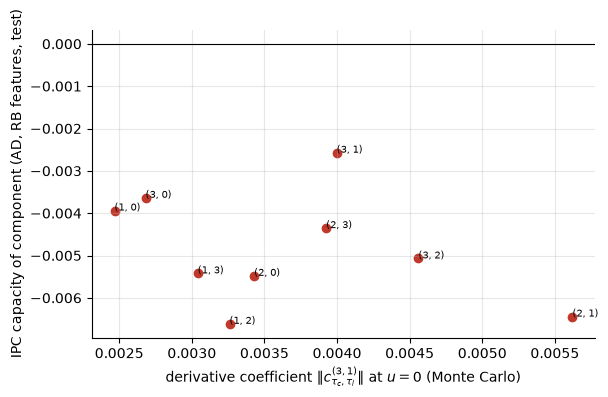

**Fig4b_derivative_vs_IPC.** Cross-check of the two kernel measures for the 9 K* components at g=0.2: derivative norms from 3 realizations (x 4096 paths); capacities averaged over 40 pilot units. Capacities below ~0.005 (features / train length) are within the finite-sample noise floor.

In [24]:
if PILOT:
    n_real = len({p["rid"] for p in PILOT}); n_u = len(PILOT)
    fig, axs = plt.subplots(1, 3, figsize=(17, 4))
    ax = axs[0]; models = ["CV", "NA", "AD", "CV_exact", "NA_exact", "AD_rb"]
    for j, m in enumerate(models):
        per_r = pd.DataFrame([dict(rid=p["rid"], v=p[m]["witness"]) for p in PILOT]).groupby("rid").v.mean()
        ax.scatter(np.full(len(per_r), j) + np.random.default_rng(j).uniform(-0.12, 0.12, len(per_r)), per_r, s=12,
                   color=COL.get(m.split("_")[0], "gray"), alpha=0.7)
        mu_, se_ = per_r.mean(), per_r.std(ddof=1) / np.sqrt(len(per_r)); ax.errorbar(j, mu_, 1.96 * se_, fmt="k_", capsize=6, ms=18)
    ax.axhline(1.0, color="k", ls="--", lw=0.8); ax.set_xticks(range(len(models)), models, rotation=20); ax.set_ylabel("witness test NMSE")
    ax.set_title(f"witness y* (g*={PILOT_G}, N={CFG['N_main']})", fontsize=9)
    ax = axs[1]; per = pd.DataFrame([dict(rid=p["rid"], dA=p["NA"]["witness"] - p["AD"]["witness"], dB=p["CV"]["witness"] - p["AD"]["witness"]) for p in PILOT]).groupby("rid").mean()
    for j, (col, lab, dm) in enumerate((("dA", "NA - AD", PREREGISTERED["delta_min_A"]), ("dB", "CV - AD", PREREGISTERED["delta_min_B"]))):
        ax.scatter(np.full(len(per), j) + np.random.default_rng(9).uniform(-0.1, 0.1, len(per)), per[col], s=12, color=COL["AD"])
        P_ = PA if col == "dA" else PB; ax.errorbar(j, P_["mean"], [[P_["mean"] - P_["ci_low"]], [P_["ci_high"] - P_["mean"]]], fmt="ko", capsize=6)
        ax.hlines(dm, j - 0.3, j + 0.3, color="g", ls=":")
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks([0, 1], ["H_A: NA - AD", "H_B: CV - AD"]); ax.set_ylabel(r"$\Delta$ NMSE (positive favours AD)")
    ax.set_title("paired primary differences (green: delta_min)", fontsize=9)
    ax = axs[2]; sec = ["NARMA5", "NARMA10", "XOR(1,2)", "parity3"]; xx = np.arange(len(sec))
    for j, m in enumerate(["CV", "NA", "AD"]):
        ax.bar(xx + 0.27 * (j - 1), [SCORES_DF.loc[m, s] for s in sec], 0.27, color=COL[m], label=m)
    ax.set_xticks(xx, sec); ax.set_ylabel("test NMSE (secondary, descriptive)"); ax.legend(fontsize=8)
    show_fig(fig, "Fig9_witness_performance", f"Pilot: {n_real} realizations x {CFG['n_inputs']} inputs x {CFG['n_innovation_reps']} innovation replicates ({n_u} paired units), "
             f"{CFG['shots_primary']} shots, train/test {CFG['train']}/{CFG['test']}. Points: realization means; black bars: mean +- 1.96 SE across realizations "
             f"(left); hierarchical-bootstrap 95% CI ({CFG['bootstrap']} resamples) (middle). Dashed line: baseline population floor NMSE = 1 (Theorems 1-2). "
             "'_exact'/'_rb' = ideal (infinite-shot) features. Right: secondary tasks, means only, not part of any claim.")
    if len(CTRL_DF):
        fig, ax = plt.subplots(figsize=(11, 3.8)); order = list(CTRL_DF.index)
        ax.errorbar(range(len(order)), CTRL_DF.improvement_vs_NA, 1.96 * CTRL_DF.se.fillna(0), fmt="o", color="k", capsize=4)
        ax.axhline(0, color="gray", lw=0.8); ax.set_xticks(range(len(order)), order, rotation=35, ha="right", fontsize=7)
        ax.set_ylabel("witness NMSE improvement vs NA"); ax.set_title("negative controls (AD shown for reference)", fontsize=9)
        show_fig(fig, "Fig10_negative_controls", f"{len(CTRL)} realizations (input 0, replicate 0), g={PILOT_G}; mean +- 1.96 SE of the paired difference to NA "
                 "across realizations. C7 and D1 use exact (ideal) features, the most favourable setting for the baselines.")
    fig, ax = plt.subplots(figsize=(7.5, 4))
    pts = [("AD", RESOURCE_DF.loc["squeezed photons injected per clock", "R_AD"], SCORES_DF.loc["AD", "witness"]),
           ("NA", RESOURCE_DF.loc["squeezed photons injected per clock", "R_NA"], SCORES_DF.loc["NA", "witness"]),
           ("CV", RESOURCE_DF.loc["squeezed photons injected per clock", "R_CV"], SCORES_DF.loc["CV", "witness"]),
           ("CV_photon", RESOURCE_DF.loc["squeezed photons injected per clock", "R_AD"], SCORES_DF.loc["CV_photon", "witness"])]
    if len(CTRL_DF):
        pts += [("NA x2 (C7)", 2 * RESOURCE_DF.loc["squeezed photons injected per clock", "R_NA"], CTRL_DF.loc["C7_NA_plus_extra_reservoir", "witness_NMSE"]),
                ("CV x2 (C7)", 2 * RESOURCE_DF.loc["squeezed photons injected per clock", "R_CV"], CTRL_DF.loc["C7_CV_plus_extra_reservoir", "witness_NMSE"])]
    for lab, x, yv in pts:
        ax.scatter(float(x), yv, s=50, color=COL.get(lab.split("_")[0].split(" ")[0], "gray")); ax.annotate(lab, (float(x), yv), fontsize=8, xytext=(4, 3), textcoords="offset points")
    ax.axhline(1, color="k", ls="--", lw=0.8); ax.set_xlabel("squeezed photons injected per clock (resource)"); ax.set_ylabel("witness test NMSE (lower is better)")
    show_fig(fig, "Fig11_resource_pareto", "Witness NMSE against injected squeezing resource, pilot means. CV_photon has the MB squeezing budget (accounting 2); "
             "x2 = a second independent reservoir (2x modes and features). Dashed: baseline population floor. No error bars: means only (see Fig. 9 for uncertainty).")
    if "K*_capacity_AD_rb" in PILOT[0] and len(DIAG):
        capm = pd.DataFrame([p["K*_capacity_AD_rb"] for p in PILOT]).mean()
        cn = [v for v in DIAG[(DIAG.N == CFG["N_main"]) & (DIAG.g == PILOT_G)].get("comp_norms", pd.Series(dtype=object))
              if isinstance(v, list) and len(v) == len(KSTAR)]
        norms = np.mean(np.array(cn), 0) if cn else None
        fig, ax = plt.subplots(figsize=(6.5, 4))
        if norms is not None and np.ndim(norms):
            ax.scatter(norms, capm.values, color=COL["AD"])
            for (c, v), nm in zip(capm.items(), norms):
                ax.annotate(c.replace("K*", ""), (nm, v), fontsize=7)
        ax.axhline(0, color="k", lw=0.8); ax.set_xlabel(r"derivative coefficient $\|c^{(3,1)}_{\tau_c,\tau_l}\|$ at $u=0$ (Monte Carlo)")
        ax.set_ylabel("IPC capacity of component (AD, RB features, test)")
        show_fig(fig, "Fig4b_derivative_vs_IPC", f"Cross-check of the two kernel measures for the 9 K* components at g={PILOT_G}: derivative norms from "
                 f"{CFG['diag_realizations']} realizations (x {CFG['kernel_trajectories']} paths); capacities averaged over {n_u} pilot units. Capacities below "
                 f"~{len(KSTAR) and (CFG['N_main'] * (CFG['N_main'] + 1) // 2) / CFG['train']:.3f} (features / train length) are within the finite-sample noise floor.")

## 12. Prospective power and runtime calculation

### 12.1 Power (fixed analysis, planned confirmatory sample)
The smallest effects of scientific interest were fixed in the control panel before the pilot: $\delta^{(A)}_{\min}=\delta^{(B)}_{\min}=0.03$. That is 3 % of the witness variance captured beyond the baselines' structural floor of NMSE $=1$. Below this, the witness capacity is not operationally useful, and it is within about $2\times$ the finite-sample capacity noise floor $F/L_{\rm train}$ at preflight scale. Power is simulated for the **exact preregistered analysis**: a paired one-sided $t$ on realization means, with Holm over $\{H_A,H_B\}$. The simulation uses a nested normal model whose variance components (realization; input sequence; innovation, shot and readout refit) and between-comparison correlation are estimated from the pilot, at the planned research design ($n_{\rm confirm}$ realizations × $n_{\rm inputs}$ inputs × 1 replicate). The pilot variances come from shorter sequences than the research run, so using them unscaled is conservative.

Power is reported for:
- the raw pilot effect;
- a positive-part James–Stein shrunken effect, $\hat\delta\max(0,1-\mathrm{SE}^2/\hat\delta^2)$;
- $\delta_{\min}$;
- a pessimistic effect, $0.5\times$ the pilot estimate.

**High power does not guarantee a positive result.** It guarantees sensitivity only conditional on the true effect being at least $\delta_{\min}$.

,delta_A,delta_B,power_H_A,power_H_B,power_both
effect,,,,,
raw pilot,-0.0003,-0.0017,0.0000,0.0000,0.0000
shrunken pilot,-0.0000,-0.0000,0.0260,0.0225,0.0005
delta_min,0.0300,0.0300,1.0000,1.0000,1.0000
pessimistic (0.5 x pilot),-0.0002,-0.0009,0.0018,0.0000,0.0000


planned n_confirm = 150: power at delta_min = (np.float64(1.0), np.float64(1.0)); smallest n on the grid with both >= 0.9: 10
[12.1 power] 0.8 s | peak RSS 1298 MB


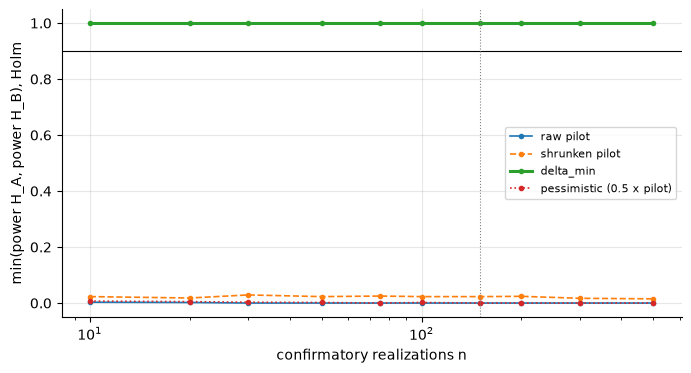

**Fig12_power_vs_n.** Monte Carlo power (1000 simulations per point) of the preregistered analysis, with variance components from the pilot (10 realizations); design 2 inputs x 1 replicate per realization; vertical line: planned n_confirm=150.

In [25]:
RESEARCH = CONFIGS["research"]
POWER = {}
if PILOT:
    with section("12.1 power"):
        rngw = rng_for("power"); n_plan, I_plan, J_plan = RESEARCH["n_confirm"], RESEARCH["n_inputs"], 1
        seA = (PA["ci_high"] - PA["ci_low"]) / (2 * 1.96); seB = (PB["ci_high"] - PB["ci_low"]) / (2 * 1.96)
        shrink = lambda m, se: m * max(0.0, 1 - se ** 2 / m ** 2) if m != 0 else 0.0
        effects = {"raw pilot": (PA["mean"], PB["mean"]), "shrunken pilot": (shrink(PA["mean"], seA), shrink(PB["mean"], seB)),
                   "delta_min": (PREREGISTERED["delta_min_A"], PREREGISTERED["delta_min_B"]),
                   "pessimistic (0.5 x pilot)": (PREREGISTERED["pessimistic_fraction"] * PA["mean"], PREREGISTERED["pessimistic_fraction"] * PB["mean"])}
        comps = [VC_A, VC_B]
        if not all(np.isfinite(sum(c)) and sum(c) > 0 for c in comps):
            comps = [(max(1e-8, np.nanvar(np.nanmean(DA, (1, 2)), ddof=1)), 0, 0), (max(1e-8, np.nanvar(np.nanmean(DB, (1, 2)), ddof=1)), 0, 0)]
        rows = []
        for lab, (eA, eB) in effects.items():
            pA, pB, pBoth = power_holm([eA, eB], comps, RHO_AB if np.isfinite(RHO_AB) else 0.5, n_plan, I_plan, J_plan, PREREGISTERED["alpha"], CFG["power_sims"], rngw)
            rows.append(dict(effect=lab, delta_A=eA, delta_B=eB, power_H_A=pA, power_H_B=pB, power_both=pBoth))
        POWER_DF = pd.DataFrame(rows).set_index("effect"); display(POWER_DF.round(4))
        NS = [10, 20, 30, 50, 75, 100, 150, 200, 300, 500]
        CURVE = {lab: [power_holm(list(effects[lab]), comps, RHO_AB if np.isfinite(RHO_AB) else 0.5, n_, I_plan, J_plan, PREREGISTERED["alpha"],
                                  max(500, CFG["power_sims"] // 4), rngw)[:2] for n_ in NS] for lab in effects}
        POWER = dict(n_plan=n_plan, at_delta_min=(POWER_DF.loc["delta_min", "power_H_A"], POWER_DF.loc["delta_min", "power_H_B"]))
        n_needed = next((n_ for n_, pw in zip(NS, CURVE["delta_min"]) if min(pw) >= PREREGISTERED["power_target"]), None)
        POWER["n_needed_delta_min"] = n_needed
        print(f"planned n_confirm = {n_plan}: power at delta_min = {POWER['at_delta_min']}; smallest n on the grid with both >= "
              f"{PREREGISTERED['power_target']}: {n_needed}")
    fig, ax = plt.subplots(figsize=(8, 4))
    for (lab, cv_), ls in zip(CURVE.items(), ["-", "--", "-", ":"]):
        ax.plot(NS, [min(p) for p in cv_], ls, marker="o", ms=3, label=lab, lw=2.2 if lab == "delta_min" else 1.2)
    ax.axhline(PREREGISTERED["power_target"], color="k", lw=0.8); ax.axvline(n_plan, color="gray", ls=":", lw=0.8); ax.set_xscale("log")
    ax.set_xlabel("confirmatory realizations n"); ax.set_ylabel("min(power H_A, power H_B), Holm"); ax.legend(fontsize=8)
    show_fig(fig, "Fig12_power_vs_n", f"Monte Carlo power ({max(500, CFG['power_sims'] // 4)} simulations per point) of the preregistered analysis, with variance "
             f"components from the pilot ({len({p['rid'] for p in PILOT})} realizations); design {I_plan} inputs x 1 replicate per realization; "
             f"vertical line: planned n_confirm={n_plan}.")

### 12.2 Runtime projection from measured throughput
$T_{\rm research}=T_{\rm setup}+\sum_{\rm stages}N_{\rm points}N_{\rm realizations}N_{\rm runs}K_{\rm clocks}M\,t_{\rm path\text{-}step}(N)+T_{\rm readout}+T_{\rm bootstrap}$.

$t_{\rm path\text{-}step}(N)$ is **measured** in this run: pilot units for trajectories, and diagnostic units for the large kernel batches. It is extrapolated to unmeasured $N$ with the fit $t=a+bN^3$. The uncertainty combines the unit-to-unit timing spread with a 25 % extrapolation margin. The conservative estimate is the 90th-percentile throughput plus that margin.

,research-run projection
"stage: exploration: diagnostics (Lambda, lambda)",5.40 h
stage: exploration: stability screens (full horizon),1.66 h
stage: exploration: chi_ad kernels,3.82 h
stage: exploration: performance scan,10.37 h
stage: confirmation: AD/NA/CV at g*,17.30 h
stage: confirmation: boundary-performance scan,3.05 h
stage: confirmation: negative controls,2.85 h
stage: robustness,3.25 h
stage: bootstrap / power / figures,0.02 h
expected total,47.7 h


[12.2 runtime projection] 2.4 s | peak RSS 1298 MB


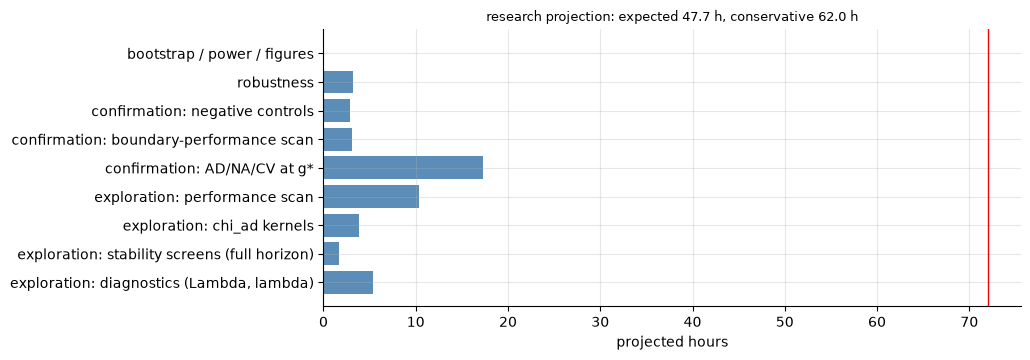

**Fig13_runtime_projection.** Stage-wise projection from throughput measured in this preflight run (40 pilot units; t = a + b N^3 fit over N in [3, 5]); red line: AVAILABLE_RUNTIME_HOURS. Uncertainty: 90th-percentile/median unit time (1.04) x 1.25 extrapolation margin.

In [26]:
RUNTIME = {}
if PILOT:
    with section("12.2 runtime projection"):
        t_unit = np.array([p["sec_per_path_step"] for p in PILOT]); Nm = CFG["N_main"]
        bench ={int(Nm): float(np.median(t_unit))}
        for N_ in CFG["N_list"]:
            if N_ != Nm:
                bench[int(N_)] = _bench(np, make_mb(0, N_, cond_of()), CFG["trajectories"], K=80)[0]
        Ns = np.array(sorted(bench)); ts = np.array([bench[n] for n in Ns])
        if len(Ns) >= 2:
            Amat = np.c_[np.ones(len(Ns)), Ns.astype(float) ** 3]; coef = np.linalg.lstsq(Amat, ts, rcond=None)[0]; coef = np.maximum(coef, [ts.min() * 0.3, 0])
        else:
            coef = np.array([ts[0], 0.0])
        tps = lambda N_: float(max(coef[0] + coef[1] * N_ ** 3, ts.min() * 0.5))
        spread = float(np.percentile(t_unit, 90) / np.median(t_unit)) if len(t_unit) > 2 else 1.3
        kt = _bench(DEVICE["kernel"], make_mb(0, Nm, cond_of()), 8 * RESEARCH["kernel_trajectories"], K=20)[0]
        tps_ker = lambda N_: kt * tps(N_) / tps(Nm)
        RC = RESEARCH; Kseq = RC["washout"] + RC["train"] + RC["test"]; M_ = RC["trajectories"]; G_ = len(RC["gain_grid"])
        n_rob = (len(RC["squeezing_db_grid"]) - 1) + (len(RC["loop_transmissivity_grid"]) - 1) + (len(RC["detector_efficiency_grid"]) - 1) + \
                (len(RC["feedforward_gain_error_grid"]) - 1) + (len(RC["angle_noise_grid"]) - 1)
        readout_s = float(np.median([p["t_score"] / p["n_scored"] for p in PILOT]))    # measured readout cost per scored feature set
        readout_s *= max(1.0, (RC["train"] / CFG["train"]))                            # SVD cost grows ~linearly with the training length
        stages = {
            "exploration: diagnostics (Lambda, lambda)": sum(G_ * RC["diag_realizations"] * 4 * RC["diag_trajectories"] * RC["diag_steps"] * tps(N_) for N_ in RC["N_list"]),
            "exploration: stability screens (full horizon)": sum(G_ * RC["diag_realizations"] * min(128, RC["diag_trajectories"] // 4) * Kseq * tps(N_) for N_ in RC["N_list"])
                + G_ * max(RC["pilot_realizations"], RC["diag_realizations"]) * 128 * Kseq * tps(RC["N_main"]),
            "exploration: chi_ad kernels": sum(G_ * RC["diag_realizations"] * len(KSTAR) * 8 * RC["kernel_trajectories"] * RC["kernel_steps"] * tps_ker(N_) for N_ in RC["N_list"]),
            "exploration: performance scan": sum(G_ * RC["n_explore"] * RC["explore_inputs"] * (Kseq * M_ * tps(N_) + readout_s) for N_ in RC["N_list"]),
            "confirmation: AD/NA/CV at g*": sum(RC["n_confirm"] * RC["n_inputs"] * (2 * Kseq * M_ * tps(N_) + 3 * readout_s) for N_ in RC["N_list"]),
            "confirmation: boundary-performance scan": 5 * (RC["n_confirm"] // 2) * (Kseq * M_ * tps(RC["N_main"]) + readout_s),
            "confirmation: negative controls": RC["control_realizations"] * (7 * Kseq * M_ * tps(RC["N_main"]) + 12 * readout_s),
            "robustness": n_rob * RC["robust_realizations"] * (2 * Kseq * M_ * tps(RC["N_main"]) + 2 * readout_s),
            "bootstrap / power / figures": 0.02 * 3600,
        }
        setup = SECTION_TIMES.get("5.5 engine validation", 60) + SECTION_TIMES.get("10 validation suite", 60) + SECTION_TIMES.get("8 selection-rule validation", 60)
        expected = (setup + sum(stages.values())) / 3600; conservative = expected * spread * 1.25
        bottleneck = max(stages, key=stages.get)
        RUNTIME = dict(expected_h=expected, conservative_h=conservative, stages_h={k: v / 3600 for k, v in stages.items()}, bottleneck=bottleneck,
                       sec_per_path_step=bench, tps_fit=coef.tolist(), kernel_sec_per_path_step=kt, spread_90=spread,
                       # largest live arrays: kernel batch (8 M_k paths x (2N)^2, ~12 temporaries) + one recorded outcome history (K x M x N)
                       peak_ram_gb_est=round((peak_rss_mb() * 2**20 + 12 * 8 * RC["kernel_trajectories"] * (2 * max(RC["N_list"])) ** 2 * 8
                                              + Kseq * RC["trajectories"] * max(RC["N_list"]) * 8) / 2**30 * 1.25, 2),
                       peak_vram_gb_est=(round(cp.get_default_memory_pool().total_bytes() / 2**30, 2) if CUPY_OK else 0.0),
                       checkpoint_mb_now=STORE.size_mb(),
                       units_planned=int(len(RC["N_list"]) * G_ * (RC["diag_realizations"] + RC["n_explore"]) + len(RC["N_list"]) * RC["n_confirm"] * RC["n_inputs"]
                                         + 5 * (RC["n_confirm"] // 2) + RC["control_realizations"] + n_rob * RC["robust_realizations"]),
                       native_fraction=TIMERS["native_s"] / max(1e-9, time.perf_counter() - NOTEBOOK_T0),
                       gpu_fraction=TIMERS["adapter_gpu_s"] / max(1e-9, TIMERS["adapter_s"]))
        RUNTIME["checkpoint_gb_est"] = round(RUNTIME["units_planned"] * STORE.size_mb() / max(1, STORE.misses + STORE.hits) / 1024 * 1.5 + 0.1, 2)
        RT_DF = pd.Series({**{f"stage: {k}": f"{v:.2f} h" for k, v in RUNTIME["stages_h"].items()},
                           "expected total": f"{expected:.1f} h", "conservative (90th pct throughput x 1.25)": f"{conservative:.1f} h",
                           "available budget": f"{AVAILABLE_RUNTIME_HOURS:.0f} h", "dominant bottleneck": bottleneck,
                           "measured s / path-step (by N)": {k: f"{v:.2e}" for k, v in bench.items()},
                           "kernel-batch s / path-step": f"{kt:.2e} ({'GPU' if DEVICE['kernel'] is not np else 'CPU'})",
                           "peak CPU RAM (estimate)": f"{RUNTIME['peak_ram_gb_est']} GB", "peak GPU VRAM (pool)": f"{RUNTIME['peak_vram_gb_est']} GB",
                           "checkpoint size (estimate)": f"{RUNTIME['checkpoint_gb_est']} GB", "parameter-point units planned": RUNTIME["units_planned"],
                           "trajectories per run": M_, "fraction of time in native engines (this run)": f"{RUNTIME['native_fraction']:.1%}",
                           "fraction of adapter time on GPU (this run)": f"{RUNTIME['gpu_fraction']:.1%}"})
        display(RT_DF.to_frame("research-run projection"))
        RUNTIME_OK = conservative <= AVAILABLE_RUNTIME_HOURS
        if not RUNTIME_OK:
            var = {"exploration: chi_ad kernels": "kernel_trajectories", "exploration: diagnostics (Lambda, lambda)": "diag_trajectories",
                   "exploration: performance scan": "n_explore", "confirmation: AD/NA/CV at g*": "trajectories", "robustness": "robust_realizations",
                   "confirmation: negative controls": "control_realizations", "confirmation: boundary-performance scan": "n_confirm"}.get(bottleneck, "trajectories")
            scale = AVAILABLE_RUNTIME_HOURS / conservative
            print(f"PROJECTED RUNTIME EXCEEDS BUDGET: conservative {conservative:.1f} h > {AVAILABLE_RUNTIME_HOURS} h. Dominant bottleneck: '{bottleneck}' "
                  f"(control-panel variable CONFIGS['research']['{var}']). Feasible reduction: multiply it by ~{scale:.2f}. "
                  f"Claim lost under the reduction: {'finite-size scaling (Level 7) if N_list is shortened' if var in ('trajectories',) else 'precision of the boundary/kernel maps (Levels 2-3 weaken), not the primary confirmatory test'}.")
    fig, ax = plt.subplots(figsize=(9, 3.6)); st = RUNTIME["stages_h"]
    ax.barh(list(st), list(st.values()), color="#5b8db8"); ax.axvline(AVAILABLE_RUNTIME_HOURS, color="r", lw=1)
    ax.set_xlabel("projected hours"); ax.set_title(f"research projection: expected {RUNTIME['expected_h']:.1f} h, conservative {RUNTIME['conservative_h']:.1f} h", fontsize=9)
    show_fig(fig, "Fig13_runtime_projection", f"Stage-wise projection from throughput measured in this {RUN_MODE} run ({len(PILOT)} pilot units; t = a + b N^3 fit "
             f"over N in {sorted(bench)}); red line: AVAILABLE_RUNTIME_HOURS. Uncertainty: 90th-percentile/median unit time ({spread:.2f}) x 1.25 extrapolation margin.")
else:
    RUNTIME_OK = None

## 13. Machine-generated go/no-go decision

* **Critical gates:** source audit, physicality, native-engine fidelity, zero-adaptivity nesting, kernel identifiability, structural distinction, negative controls, resource matching, reproducibility.
* **Statistical and runtime gates:** pilot direction, prospective power, runtime.

**Decision rule.** Any critical FAIL gives `NO-GO`. A pilot whose 95 % upper bound lies below $\delta_{\min}$ for either primary comparison is *futile*: the long run would test an effect the pilot already excludes, so the decision is `NO-GO`. Otherwise, a failed statistical or runtime gate gives `CONDITIONAL GO`, with the required changes listed. `GO` requires every gate to pass (pilot direction PASS or WARN).

> `GO` means only: *the program is correct to the tested tolerances, the hypothesis is identifiable, and the planned run has sufficient power to test the predefined effect.* It does **not** mean the longer run will find an advantage.

,gate,requirement,evidence,status,critical
0,Source audit,input implementations identified,4 notebooks hashed; MB+CV sources identified=True,PASS,True
1,Physicality,all critical state/channel tests pass,"P1:ok, P2:ok, P5:ok, P6:ok, P10:ok, P11:ok, P7a:ok, P7b:ok, P7c:ok, S8.NA0:ok, S8.CV0:ok, P3:ok, P4:ok, P8:ok, P9:ok",PASS,True
2,Native-engine fidelity,native and reference calculations agree,"P1:ok, P2:ok, P12:ok, P13:ok, N3a:ok, N3b:ok, N1:ok",PASS,True
3,Zero-adaptivity nesting,R_AD(g=0) = R_NA,"P7a trajectory identity, P7b total-variance identity, P7c ensemble",PASS,True
4,Kernel identifiability,"chi_ad(g*) SNR >= 5.0, g=0 null |z|<3, methods agree","g*=0.2, SNR=0.79, null z=0.42, N5a/N5b=ok",FAIL,True
5,Structural distinction,exact exclusion for NA and CV + nonzero AD kernel,NA/CV exact zeros=True; AD resolved=False,FAIL,True
6,Negative controls,effect absent when causal adaptivity is destroyed; equalized baselines at floor,see §11.2,PASS,True
7,Resource matching,comparison budgets matched (or normalized),matched rows=True; squeezing normalized via CV_photon and C7,PASS,True
8,Pilot direction,both primary differences have the predicted sign; no diverged unit at g*,"H_A -0.0003 [-0.0011,+0.0007], H_B -0.0017 [-0.0054,+0.0017]; futile=True; excluded units=2",FAIL,False
9,Prospective power,"power at delta_min >= 0.9 (both, Holm)","(1.000, 1.000) at n=150; n needed ~ 10",PASS,False



=== PREFLIGHT DECISION: NO-GO ===
 - critical gate failed: Kernel identifiability
 - critical gate failed: Structural distinction
 - preflight language: no advantage is 'established' by this run


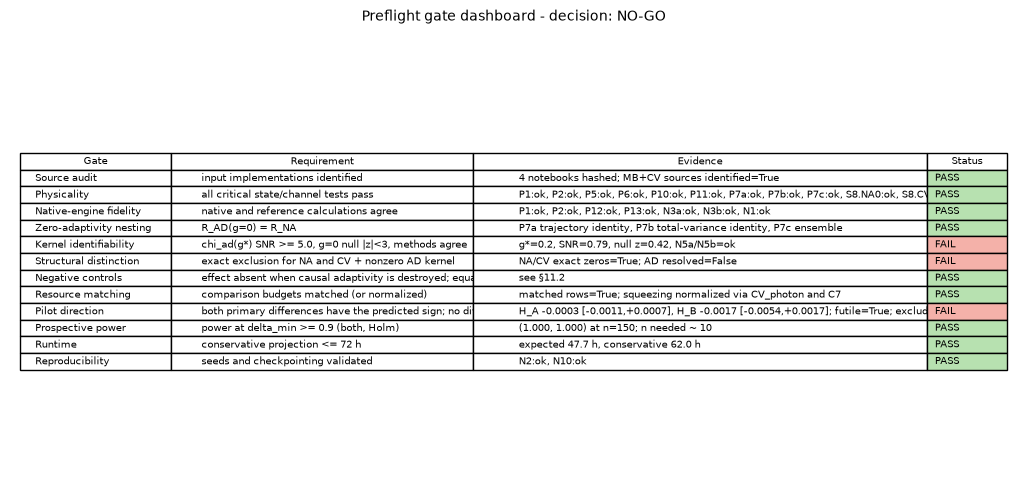

**Fig15_gate_dashboard.** Machine-generated gates from this preflight run. Critical gates: Source audit, Physicality, Native-engine fidelity, Zero-adaptivity nesting, Kernel identifiability, Structural distinction, Negative controls, Resource matching, Reproducibility. Evidence strings quote the numbers computed above; uncertainty definitions are given at each source cell.

In [27]:
def _crit_pass(category=None, ids=None):
    d = TESTS_DF if ids is None else TESTS_DF[TESTS_DF.id.isin(ids)]
    if category:
        d = d[d.category == category]
    d = d[d.critical]
    return bool(len(d)) and bool(d.passed.all()), ", ".join(f"{r.id}:{'ok' if r.passed else 'FAIL'}" for r in d.itertuples())

GATES, DECISION, DECISION_REASONS = [], "not evaluated (unit mode)", []
TESTS_DF = pd.DataFrame(TESTS)
if RUN_MODE != "unit":
    def gate(name, requirement, evidence, status, critical):
        GATES.append(dict(gate=name, requirement=requirement, evidence=evidence, status=status, critical=critical))
    gate("Source audit", "input implementations identified", f"{len(AUDIT_DF)} notebooks hashed; MB+CV sources identified={SOURCE_AUDIT_OK}", "PASS" if SOURCE_AUDIT_OK else "FAIL", True)
    ok, ev = _crit_pass("physics"); gate("Physicality", "all critical state/channel tests pass", ev, "PASS" if ok else "FAIL", True)
    ok, ev = _crit_pass(ids=["P1", "P2", "P12", "P13", "N3a", "N3b", "N1"]); gate("Native-engine fidelity", "native and reference calculations agree", ev, "PASS" if ok else "FAIL", True)
    gate("Zero-adaptivity nesting", "R_AD(g=0) = R_NA", "P7a trajectory identity, P7b total-variance identity, P7c ensemble", "PASS" if NESTING_OK else "FAIL", True)
    kid = (CHI_SNR >= PREREGISTERED["kernel_snr_min"]) and np.isfinite(CHI_NULL_Z) and abs(CHI_NULL_Z) < 3 and _crit_pass(ids=["N5a", "N5b"])[0]
    gate("Kernel identifiability", f"chi_ad(g*) SNR >= {PREREGISTERED['kernel_snr_min']}, g=0 null |z|<3, methods agree",
         f"g*={G_STAR}, SNR={CHI_SNR:.2f}, null z={CHI_NULL_Z:.2f}, N5a/N5b={'ok' if _crit_pass(ids=['N5a', 'N5b'])[0] else 'FAIL'}", "PASS" if kid else "FAIL", True)
    gate("Structural distinction", "exact exclusion for NA and CV + nonzero AD kernel", f"NA/CV exact zeros={STRUCT_ZERO_OK}; AD resolved={kid}",
         "PASS" if (STRUCT_ZERO_OK and kid) else "FAIL", True)
    gate("Negative controls", "effect absent when causal adaptivity is destroyed; equalized baselines at floor",
         "see §11.2" if CONTROLS_OK is not None else "controls not run", "PASS" if CONTROLS_OK else "FAIL", True)
    gate("Resource matching", "comparison budgets matched (or normalized)", f"matched rows={RESOURCE_MATCHED}; squeezing normalized via CV_photon and C7", "PASS" if RESOURCE_MATCHED else "FAIL", True)
    futile = False
    if PILOT:
        both_pos = PA["mean"] > 0 and PB["mean"] > 0; sig = max(PA["p_holm"], PB["p_holm"]) < 0.10
        futile = PA["ci_high"] < PREREGISTERED["delta_min_A"] or PB["ci_high"] < PREREGISTERED["delta_min_B"]
        gate("Pilot direction", "both primary differences have the predicted sign; no diverged unit at g*", f"H_A {PA['mean']:+.4f} [{PA['ci_low']:+.4f},{PA['ci_high']:+.4f}], "
             f"H_B {PB['mean']:+.4f} [{PB['ci_low']:+.4f},{PB['ci_high']:+.4f}]; futile={futile}; excluded units={len(PILOT_EXCLUDED)}",
             "FAIL" if PILOT_EXCLUDED else ("PASS" if both_pos and sig else ("WARN" if both_pos else "FAIL")), False)
        pw_ok = POWER and min(POWER["at_delta_min"]) >= PREREGISTERED["power_target"]
        gate("Prospective power", f"power at delta_min >= {PREREGISTERED['power_target']} (both, Holm)", f"({', '.join(f'{float(x):.3f}' for x in POWER['at_delta_min'])}) at n={POWER['n_plan']}; "
             f"n needed ~ {POWER.get('n_needed_delta_min')}", "PASS" if pw_ok else "FAIL", False)
        gate("Runtime", f"conservative projection <= {AVAILABLE_RUNTIME_HOURS:.0f} h", f"expected {RUNTIME['expected_h']:.1f} h, conservative {RUNTIME['conservative_h']:.1f} h",
             "PASS" if RUNTIME_OK else "FAIL", False)
    ok, ev = _crit_pass(ids=["N2", "N10"]); gate("Reproducibility", "seeds and checkpointing validated", ev, "PASS" if ok else "FAIL", True)
    GATE_DF = pd.DataFrame(GATES)
    with pd.option_context("display.max_colwidth", 120, "display.width", 260):
        display(GATE_DF)
    crit_fail = GATE_DF[GATE_DF.critical & (GATE_DF.status != "PASS")].gate.tolist()
    stat_fail = GATE_DF[(~GATE_DF.critical) & (GATE_DF.status == "FAIL")].gate.tolist()
    if crit_fail:
        DECISION = "NO-GO"; DECISION_REASONS = [f"critical gate failed: {g}" for g in crit_fail]
    elif futile:
        DECISION = "NO-GO"; DECISION_REASONS = ["pilot futility: the 95% upper bound of a primary improvement lies below delta_min, so the long run would test an effect the pilot already excludes"]
    elif stat_fail:
        DECISION = "CONDITIONAL GO"; DECISION_REASONS = [f"statistical/runtime gate failed: {g}" for g in stat_fail]
    else:
        DECISION = "GO"; DECISION_REASONS = ["all gates pass (GO = correct to tested tolerances, identifiable, adequately powered; NOT a guarantee of a positive result)"]
    if RUN_MODE == "preflight":
        DECISION_REASONS.append("preflight language: no advantage is 'established' by this run")
    print(f"\n=== PREFLIGHT DECISION: {DECISION} ===")
    for r in DECISION_REASONS:
        print(" -", r)
    (RES / "preflight_decision.json").write_text(json.dumps(dict(decision=DECISION, reasons=DECISION_REASONS, gates=GATES, lock=LOCK, mode=RUN_MODE), indent=1, default=str))
    colors = {"PASS": "#b7e1b0", "WARN": "#f8e5a0", "FAIL": "#f4b1a9"}
    fig, ax = plt.subplots(figsize=(13, 0.42 * len(GATE_DF) + 1)); ax.axis("off")
    tb = ax.table(cellText=[[r.gate, r.requirement[:60], r.evidence[:85], r.status] for r in GATE_DF.itertuples()], colLabels=["Gate", "Requirement", "Evidence", "Status"],
                  loc="center", cellLoc="left", colWidths=[0.15, 0.3, 0.45, 0.08])
    tb.auto_set_font_size(False); tb.set_fontsize(7)
    for i, r in enumerate(GATE_DF.itertuples(), start=1):
        tb[i, 3].set_facecolor(colors[r.status])
    ax.set_title(f"Preflight gate dashboard - decision: {DECISION}", fontsize=10)
    show_fig(fig, "Fig15_gate_dashboard", f"Machine-generated gates from this {RUN_MODE} run. Critical gates: {', '.join(GATE_DF[GATE_DF.critical].gate)}. "
             "Evidence strings quote the numbers computed above; uncertainty definitions are given at each source cell.")
else:
    print("unit mode: the go/no-go gate is not evaluated (unit mode produces no scientific conclusions).")
    GATE_DF = pd.DataFrame()

## 14. Research-run cells (execute only in `research` / `research_dryrun`)

**14.1 Exploration** (exploratory seed bank, ≥30 paired realizations per point). The §9 diagnostics already ran at research scale. Here an exploratory AD-vs-NA witness scan over the whole gain grid and every size is added. It is reported, but the lock rule never reads it.

**14.2 Programmatic lock.** For every size, $g^\star$ is chosen by the §9 rule from the diagnostics only. The manifest, which records the boundary intervals, operating points, regularization policy, witness, noise conditions and comparison points, is saved with a SHA-256 hash and re-verified before confirmation.

**14.3 Confirmation** (fresh confirmatory seed bank, ≥50 paired realizations; nothing retuned):
- primary AD/NA/CV comparison at $g^\star$ for every locked size;
- a boundary-performance scan at five grid points around $g^\star$;
- negative controls at $g^\star$.

In [28]:
IS_RESEARCH = RUN_MODE in ("research", "research_dryrun")
EXPLORE, CONF, CONF_SCAN, CONF_CTRL, LOCKS = [], [], [], [], {}
def run_units(stage, specs, fn):
    out = []
    for params in specs:
        r = STORE.cached(stage, {**params, "base": BASE, "L": (CFG["washout"], CFG["train"], CFG["test"]), "M": CFG["trajectories"],
                                 "S": CFG["shots_list"], "Sp": CFG["shots_primary"], "lam": CFG["ridge_grid"]}, lambda p=params: fn(p))
        if r.get("failed"):
            FAILED_UNITS.append(dict(stage=stage, **params, reason=r["reason"])); continue
        out.append(r)
    return out

if IS_RESEARCH:
    with section("14.1 exploration scan"):
        specs = [dict(rid=rid, N=N_, g=g, i=i) for N_ in CFG["N_list"] for g in CFG["gain_grid"] for rid in EXPLORATORY_SEED_BANK[:CFG["n_explore"]]
                 for i in range(CFG["explore_inputs"])]
        EXPLORE = run_units("explore", specs, lambda p: pilot_unit(p["rid"], p["N"], p["g"], p["i"], 0, cond_of(), CFG["trajectories"], CFG["shots_list"], light=True))
        ledger_use("exploration", "exploratory", range(CFG["n_explore"]))
        EXP_DF = pd.DataFrame([dict(N=e["N"], g=e["g"], AD=e["AD"]["witness"], NA=e["NA"]["witness"], Cstar_AD=e["AD"]["Cstar"]) for e in EXPLORE])
        display(EXP_DF.groupby(["N", "g"]).mean(numeric_only=True).round(4))
    with section("14.2 lock"):
        for N_ in CFG["N_list"]:
            LOCKS[N_] = make_lock(AGG, N_, f"research-N{N_}")
        def verify_lock_file(N_):
            L_ = json.loads((RES / f"lock_manifest_research-N{N_}.json").read_text()); h = L_.pop("sha256")
            return hashlib.sha256(json.dumps(L_, sort_keys=True, default=str).encode()).hexdigest() == h
        LOCK_VERIFIED = all(verify_lock_file(N_) for N_ in CFG["N_list"])
        display(pd.DataFrame({N_: {k: LOCKS[N_][k] for k in ("g_star", "g_edge_channel", "g_edge_traj_CI", "g_chi_peak", "sha256")} for N_ in LOCKS}))
        print("lock manifests verified:", LOCK_VERIFIED)
    with section("14.3 confirmation"):
        assert LOCK_VERIFIED, "lock manifest altered after locking - confirmatory stage refused"
        led = json.loads(LEDGER_PATH.read_text()) if LEDGER_PATH.exists() else {}
        prior = {s: v for s, v in led.get("confirmatory", {}).items() if s != "confirmation"}
        assert not prior, f"confirmatory seeds were used by another stage before confirmation: {prior}"
        n_c = CFG["n_confirm"]; cb = CONFIRMATORY_SEED_BANK
        specs = [dict(rid=rid, N=N_, g=LOCKS[N_]["g_star"], i=i) for N_ in CFG["N_list"] if LOCKS[N_]["g_star"] is not None
                 for rid in cb[:n_c] for i in range(CFG["n_inputs"])]
        CONF = run_units("confirm", specs, lambda p: pilot_unit(p["rid"], p["N"], p["g"], p["i"], 0, cond_of(), CFG["trajectories"], CFG["shots_list"]))
        gs = sorted(CFG["gain_grid"]); Ls = LOCKS[CFG["N_main"]]
        if Ls["g_star"] is not None:
            j = gs.index(Ls["g_star"]); scan_g = sorted({gs[0], gs[max(0, j - 1)], gs[j], gs[min(len(gs) - 1, j + 1)], gs[-1]})
            CONF_SCAN = run_units("confirm-scan", [dict(rid=rid, N=CFG["N_main"], g=g, i=0) for g in scan_g for rid in cb[:max(2, n_c // 2)]],
                                  lambda p: pilot_unit(p["rid"], p["N"], p["g"], 0, 0, cond_of(), CFG["trajectories"], CFG["shots_list"], light=True))
            CONF_CTRL = run_units("confirm-control", [dict(rid=rid, N=CFG["N_main"], g=Ls["g_star"]) for rid in cb[:CFG["control_realizations"]]],
                                  lambda p: control_unit(p["rid"], p["N"], p["g"], cond_of(), CFG["trajectories"]))
        ledger_use("confirmation", "confirmatory", range(max(n_c, CFG["control_realizations"])))
        print(f"confirmatory units: {len(CONF)} primary, {len(CONF_SCAN)} scan, {len(CONF_CTRL)} control; failed: "
              f"{sum(1 for f in FAILED_UNITS if f['stage'].startswith('confirm'))}")
else:
    print(f"RUN_MODE={RUN_MODE!r}: research cells skipped (nothing in this section was executed).")

RUN_MODE='preflight': research cells skipped (nothing in this section was executed).


## 15. Robustness and confirmatory analysis

**15.1 Robustness probe.** This runs at preflight scale in preflight mode and at confirmatory scale in research mode. Around the base point, one factor is varied at a time: squeezing, loop transmissivity, detector efficiency, feedforward gain error, homodyne-angle jitter, and the shot budget. Each condition is paired AD vs NA at the operating point. Under angle jitter the NA baseline itself leaks into $\mathcal K_\star$ at $O(\sigma_\theta^2)$ (§8), so there the comparison is against a jittered NA. No postselection is used anywhere, so every sample is accepted (acceptance probability 1).

**15.2 Confirmatory analysis** (research only):
- paired mean and median, 95 % hierarchical CI, standardized effect, Holm-corrected $p$, $P(\Delta>\delta_{\min})$;
- sensitivity to fixed regularization;
- raw unit counts and excluded units with reasons;
- both resource accountings;
- the boundary-performance relationship, judged against all seven preregistered criteria, plus a mediation check $g\to\chi_{\rm ad}\to S$ (supportive only).

,dA,se,Cstar_AD,Cstar_NA,diverged,n,acceptance,excluded
condition,,,,,,,,
angle jitter 0.02 rad,-0.00091,0.00036,-0.04664,-0.04573,0.0,3,1.0,NaN
base,-0.00090,0.00032,-0.04603,-0.04532,0.0,3,1.0,NaN
detector efficiency 0.9,-0.00092,0.00030,-0.04547,-0.04462,0.0,3,1.0,NaN
feedforward gain error 0.02,0.00255,0.00274,-0.05489,-0.05263,0.0,3,1.0,NaN
loop transmissivity 0.9,-0.00114,0.00019,-0.04220,-0.04232,0.0,3,1.0,NaN
loop transmissivity 0.95,-0.00108,0.00023,-0.04430,-0.04329,0.0,3,1.0,NaN
squeezing 10 dB,-0.00091,0.00032,-0.04619,-0.04545,0.0,3,1.0,NaN
squeezing 20 dB,-0.00090,0.00032,-0.04598,-0.04528,0.0,3,1.0,NaN
shots 64,0.00048,0.00040,NaN,NaN,NaN,38,NaN,2.0


[15.1 robustness probe] 362.7 s | peak RSS 1298 MB


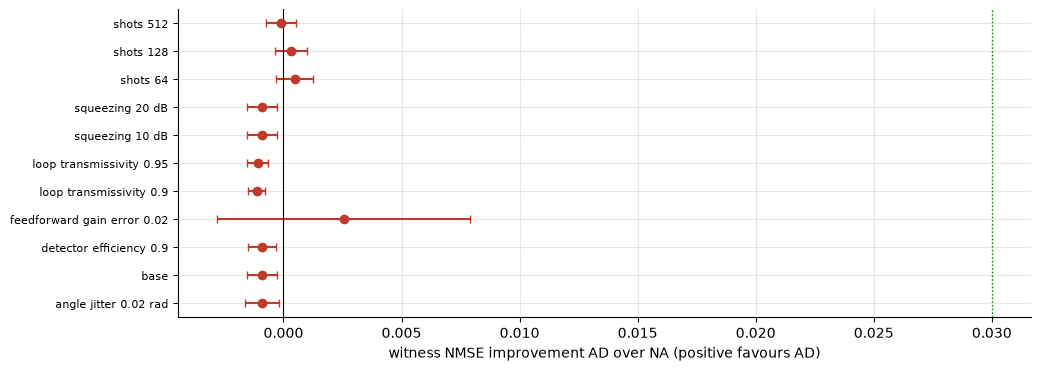

**Fig14_robustness.** One-factor-at-a-time robustness at g=0.2, N=5: 3 realizations per condition (shot rows: all 40 pilot units); mean +- 1.96 SE across realizations. Green: delta_min. All samples accepted (no postselection).

15.2 confirmatory analysis: not executed in this mode (requires RUN_MODE='research').


In [29]:
def robustness_conditions(cfg):
    conds = [("base", {}, 0.0)]
    conds += [(f"squeezing {v:g} dB", dict(squeezing_db=v), 0.0) for v in cfg["squeezing_db_grid"] if v != BASE["squeezing_db"]]
    conds += [(f"loop transmissivity {v:g}", dict(loop_transmissivity=v), 0.0) for v in cfg["loop_transmissivity_grid"] if v != BASE["loop_transmissivity"]]
    conds += [(f"detector efficiency {v:g}", dict(detector_efficiency=v), 0.0) for v in cfg["detector_efficiency_grid"] if v != BASE["detector_efficiency"]]
    conds += [(f"feedforward gain error {v:g}", dict(feedforward_gain_error=v), 0.0) for v in cfg["feedforward_gain_error_grid"] if v != BASE["feedforward_gain_error"]]
    conds += [(f"angle jitter {v:g} rad", {}, v) for v in cfg["angle_noise_grid"] if v != BASE["angle_noise_rad"]]
    return conds

def robustness_run(stage, rids, g):
    rows = []
    for name, over, ang in robustness_conditions(CFG):
        for rid in rids:
            r = STORE.cached(stage, dict(cond=name, over=over, ang=ang, rid=rid, N=CFG["N_main"], g=g, M=CFG["trajectories"], S=CFG["shots_list"], Sp=CFG["shots_primary"],
                                         L=(CFG["washout"], CFG["train"], CFG["test"]), base=BASE, lam=CFG["ridge_grid"]),
                             lambda: pilot_unit(rid, CFG["N_main"], g, 0, 0, cond_of(**over), CFG["trajectories"], CFG["shots_list"], angle_noise=ang, light=True))
            if r.get("failed"):
                FAILED_UNITS.append(dict(stage=stage, cond=name, rid=rid, reason=r["reason"])); continue
            rows.append(dict(condition=name, rid=rid, dA=r["NA"]["witness"] - r["AD"]["witness"], Cstar_AD=r["AD"]["Cstar"], Cstar_NA=r["NA"]["Cstar"],
                             diverged=r["diverged_AD"] is not None, acceptance=1.0))
    return pd.DataFrame(rows)

ROB_DF = pd.DataFrame(); CONF_RES = {}
if PILOT and CFG["robust_realizations"] > 0:
    with section("15.1 robustness probe"):
        rids = (CONFIRMATORY_SEED_BANK[CFG["n_confirm"]:CFG["n_confirm"] + CFG["robust_realizations"]] if IS_RESEARCH
                else EXPLORATORY_SEED_BANK[:CFG["robust_realizations"]])
        ROB_DF = robustness_run("robust", rids, LOCKS[CFG["N_main"]]["g_star"] if IS_RESEARCH and LOCKS.get(CFG["N_main"], {}).get("g_star") is not None else PILOT_G)
        if IS_RESEARCH:
            ledger_use("confirmation", "confirmatory", range(CFG["n_confirm"], CFG["n_confirm"] + CFG["robust_realizations"]))
        shots_rows = []
        for S in CFG["shots_list"]:
            key = "" if S == CFG["shots_primary"] else f"@{S}"
            d = np.array([p["NA" + key]["witness"] - p["AD" + key]["witness"] for p in PILOT]); d = d[np.isfinite(d)]
            shots_rows.append(dict(condition=f"shots {S}", dA=d.mean(), se=d.std(ddof=1) / np.sqrt(len(d)), n=len(d), excluded=len(PILOT) - len(d)))
        ROB_SUM = ROB_DF.groupby("condition").agg(dA=("dA", "mean"), se=("dA", lambda s: s.std(ddof=1) / np.sqrt(len(s)) if len(s) > 1 else np.nan),
                                                 Cstar_AD=("Cstar_AD", "mean"), Cstar_NA=("Cstar_NA", "mean"), diverged=("diverged", "sum"), n=("rid", "count"),
                                                 acceptance=("acceptance", "mean"))
        ROB_SUM = pd.concat([ROB_SUM, pd.DataFrame(shots_rows).set_index("condition")]); display(ROB_SUM.round(5))
    fig, ax = plt.subplots(figsize=(11, 4)); yy = np.arange(len(ROB_SUM))
    ax.errorbar(ROB_SUM.dA, yy, xerr=1.96 * ROB_SUM.se.fillna(0), fmt="o", color=COL["AD"], capsize=3); ax.set_yticks(yy, ROB_SUM.index, fontsize=8)
    ax.axvline(0, color="k", lw=0.8); ax.axvline(PREREGISTERED["delta_min_A"], color="g", ls=":", lw=1)
    ax.set_xlabel("witness NMSE improvement AD over NA (positive favours AD)")
    show_fig(fig, "Fig14_robustness", f"One-factor-at-a-time robustness at g={PILOT_G if not IS_RESEARCH else LOCKS.get(CFG['N_main'], {}).get('g_star')}, N={CFG['N_main']}: "
             f"{CFG['robust_realizations']} realizations per condition (shot rows: all {len(PILOT)} pilot units); mean +- 1.96 SE across realizations. "
             "Green: delta_min. All samples accepted (no postselection).")

if IS_RESEARCH and CONF:
    with section("15.2 confirmatory analysis"):
        rngc = rng_for("confirm-analysis"); tabs = {}
        for N_ in sorted({c["N"] for c in CONF}):
            U = [c for c in CONF if c["N"] == N_]
            DAc, DBc = pilot_array("NA", "AD", units=U), pilot_array("CV", "AD", units=U)
            ra, rb = analyse(DAc.reshape(len(DAc), -1), PREREGISTERED["delta_min_A"], CFG["bootstrap"], rngc), analyse(DBc.reshape(len(DBc), -1), PREREGISTERED["delta_min_B"], CFG["bootstrap"], rngc)
            ra["p_holm"], rb["p_holm"] = holm([ra["p_one_sided"], rb["p_one_sided"]])
            DPc = pilot_array("CV_photon", "AD", units=U); rp = analyse(DPc.reshape(len(DPc), -1), PREREGISTERED["delta_min_B"], CFG["bootstrap"], rngc)
            tabs[(N_, "H_A: NA - AD")], tabs[(N_, "H_B: CV - AD")], tabs[(N_, "accounting 2: CV_photon - AD")] = ra, rb, rp
            lam_s = {l: (np.mean([c["witness_by_lambda"]["NA"][j] - c["witness_by_lambda"]["AD"][j] for c in U]),
                         np.mean([c["witness_by_lambda"]["CV"][j] - c["witness_by_lambda"]["AD"][j] for c in U])) for j, l in enumerate(CFG["ridge_grid"])}
            CONF_RES[N_] = dict(A=ra, B=rb, photon=rp, lambda_sensitivity=lam_s, n_units=len(U))
        CONF_TABLE = pd.DataFrame(tabs).T; display(CONF_TABLE.round(5))
        Nm = CFG["N_main"]
        if Nm in CONF_RES:
            display(pd.DataFrame(CONF_RES[Nm]["lambda_sensitivity"], index=["NA - AD", "CV - AD"]).T.rename_axis("fixed lambda").round(5))
        print("raw counts:", {N_: CONF_RES[N_]["n_units"] for N_ in CONF_RES}, "| excluded units:",
              [f for f in FAILED_UNITS if f["stage"].startswith("confirm")] or "none")
        BP = {}
        if CONF_SCAN:
            sc = pd.DataFrame([dict(g=c["g"], dA=c["NA"]["witness"] - c["AD"]["witness"]) for c in CONF_SCAN]).groupby("g").dA.agg(["mean", "std", "count"])
            sc["se"] = sc["std"] / np.sqrt(sc["count"]); display(sc.round(5))
            g_opt = float(sc["mean"].idxmax()); Lm = LOCKS[Nm]; bnd = Lm["g_edge_channel"] if Lm["g_edge_channel"] is not None else Lm["g_edge_traj_CI"]
            step = np.diff(sorted(CFG["gain_grid"])).max()
            chi_g = AGG[AGG.N == Nm].set_index("g").chi.reindex(sc.index)
            mid_l = CFG["ridge_grid"][2:-2]; lam_ok = all(np.sign(CONF_RES[Nm]["lambda_sensitivity"][l][0]) == np.sign(CONF_RES[Nm]["A"]["mean"]) for l in mid_l)
            tq = float(sst.t.isf(sst.norm.sf(PREREGISTERED["control_z_max"]), max(1, len(CONF_CTRL) - 1)))
            ctrl_ok = bool(CONF_CTRL) and all(abs(np.mean([c[k]["witness"] - c["NA"]["witness"] for c in CONF_CTRL])) <
                                              tq * np.std([c[k]["witness"] - c["NA"]["witness"] for c in CONF_CTRL], ddof=1) / np.sqrt(len(CONF_CTRL)) + 1e-12
                                              for k in ("C2_time_shuffled", "C5_iid_matched_marginal", "C6_disconnected_target"))
            BP = {"1 boundary identified independently": bnd is not None,
                  "2 optimum not at a scan endpoint": g_opt not in (min(sc.index), max(sc.index)),
                  "3 optimum within one grid step of the boundary": bnd is not None and abs(g_opt - bnd) <= step,
                  "4 paired improvement over both baselines": CONF_RES[Nm]["A"]["p_holm"] < PREREGISTERED["alpha"] and CONF_RES[Nm]["B"]["p_holm"] < PREREGISTERED["alpha"],
                  "5 robust to modest grid changes": False,
                  "6 robust to readout regularization": lam_ok,
                  "7 no similar effect in causal-destroying controls": ctrl_ok}
            BP_NOTE = "criterion 5 needs a second, shifted gain grid, which this protocol does not run; correspondence therefore cannot be established here"
            med = float(np.corrcoef(chi_g.values, sc["mean"].values)[0, 1]) if chi_g.notna().all() and len(sc) > 2 else np.nan
            print("boundary-performance criteria:", json.dumps(BP, indent=1), "\nnote:", BP_NOTE, f"\nmediation (supportive only): corr(chi_ad, Delta_A) over g = {med:.3f}")
            CONF_RES["boundary_performance"] = dict(criteria=BP, g_opt=g_opt, boundary=bnd, mediation_corr=med)
else:
    CONF_TABLE = pd.DataFrame()
    if not IS_RESEARCH:
        print("15.2 confirmatory analysis: not executed in this mode (requires RUN_MODE='research').")

## 16. Claim ladder and final verdict

The ladder is evaluated from the executed data, and no level can be skipped. Even Level 6 would be described only as an **adaptive MB-QRC architectural advantage**, never as quantum advantage over classical computation.

| level | claim |
|---|---|
| 0 | implementation compiles |
| 1 | physical and numerical validation passes |
| 2 | the adaptive response sector is structurally identified |
| 3 | an independent adaptive boundary or crossover is identified |
| 4 | AD beats NA on the preregistered witness |
| 5 | AD also beats CV-QRC under matched resources (both accountings) |
| 6 | both advantages survive realistic noise and finite sampling |
| 7 | finite-size scaling supports a genuine transition rather than a crossover |

In [30]:
TESTS_DF = pd.DataFrame(TESTS); CRITICAL_FAILS = TESTS_DF[(TESTS_DF.critical) & (~TESTS_DF.passed)].id.tolist()
Nm = CFG["N_main"]; dmin = PREREGISTERED["delta_min_A"]
def lvl(status, evidence):
    return dict(status=status, evidence=evidence)
L = {}
L[0] = lvl("established", "all cells executed")
L[1] = lvl("established" if not CRITICAL_FAILS else "not supported", f"{int(TESTS_DF.passed.sum())}/{len(TESTS_DF)} tests passed; critical failures: {CRITICAL_FAILS or 'none'}")
if RUN_MODE == "unit":
    for k in range(2, 8):
        L[k] = lvl("not evaluated (unit mode)", "unit mode draws no scientific conclusion")
else:
    struct = STRUCT_ZERO_OK and CHI_SNR >= PREREGISTERED["kernel_snr_min"] and np.isfinite(CHI_NULL_Z) and abs(CHI_NULL_Z) < 3
    L[2] = lvl("established" if struct else ("not supported" if not STRUCT_ZERO_OK else "not resolved"),
               f"exact NA/CV exclusion={STRUCT_ZERO_OK} (forbidden/allowed < {PREREGISTERED['zero_tol_rel']:g}); AD chi_ad SNR at g*={CHI_SNR:.2f} "
               f"(threshold {PREREGISTERED['kernel_snr_min']}), g=0 null z={CHI_NULL_Z:.2f}")
    edges = {k: LOCK.get(k) for k in ("g_edge_channel", "g_edge_traj_CI")} if LOCK else {}
    found = any(v is not None for v in edges.values())
    L[3] = lvl(("established" if IS_RESEARCH else "suggested (pilot-level diagnostics)") if found else "not resolved in the scanned gain range",
               f"edges {edges}; chi peak at g={LOCK.get('g_chi_peak') if LOCK else None}; single size => finite-size adaptive crossover")
    if IS_RESEARCH and Nm in CONF_RES:
        A_, B_, P_ = CONF_RES[Nm]["A"], CONF_RES[Nm]["B"], CONF_RES[Nm]["photon"]
        l4 = A_["p_holm"] < PREREGISTERED["alpha"] and A_["mean"] >= dmin
        l5 = l4 and B_["p_holm"] < PREREGISTERED["alpha"] and B_["mean"] >= PREREGISTERED["delta_min_B"] and P_["mean"] >= PREREGISTERED["delta_min_B"]
        L[4] = lvl("established" if l4 else "not supported", f"H_A: {A_['mean']:+.4f} [{A_['ci_low']:+.4f}, {A_['ci_high']:+.4f}], Holm p={A_['p_holm']:.3g}, n={A_['n_realizations']}")
        L[5] = lvl("established" if l5 else "not supported", f"H_B: {B_['mean']:+.4f}, Holm p={B_['p_holm']:.3g}; photon-matched CV: {P_['mean']:+.4f}")
        rob_ok = len(ROB_DF) and (ROB_DF.groupby("condition").dA.mean() > 0).all()
        L[6] = lvl("established" if (l5 and rob_ok) else "not supported", f"robust conditions all positive: {bool(rob_ok)}")
        fss = len(CFG["N_list"]) >= 3 and all(LOCKS.get(n_, {}).get("g_edge_channel") is not None for n_ in CFG["N_list"])
        L[7] = lvl("suggested" if (l5 and fss) else "not supported", "edges at every N (sharpening not quantified beyond this check)")
    else:
        for k in range(4, 8):
            L[k] = lvl("requires the research run", "confirmatory data not collected in this mode")
LADDER = pd.DataFrame(L).T; LADDER.index.name = "level"; display(LADDER)
highest = -1
for k in range(8):
    if L[k]["status"] == "established":
        highest = k
    else:
        break
print(f"highest established level (no skipping): {highest}")
if IS_RESEARCH:
    fig, ax = plt.subplots(figsize=(9, 3.4)); cmap = {"established": "#4caf50", "suggested": "#ffc107", "not supported": "#e57373"}
    ax.barh(range(8), [1] * 8, color=[next((c for s, c in cmap.items() if L[k]["status"].startswith(s)), "#bdbdbd") for k in range(8)])
    ax.set_yticks(range(8), [f"L{k}: {L[k]['status']}" for k in range(8)], fontsize=8); ax.set_xticks([]); ax.invert_yaxis()
    show_fig(fig, "Fig16_claim_ladder", f"Claim ladder from the executed research data (confirmatory n per size = {CFG['n_confirm']} realizations x "
             f"{CFG['n_inputs']} inputs; uncertainty definitions as in §15). Highest established level: {highest}.")

,status,evidence
level,,
0,established,all cells executed
1,established,42/42 tests passed; critical failures: none
2,not resolved,exact NA/CV exclusion=True (forbidden/allowed ...
3,suggested (pilot-level diagnostics),"edges {'g_edge_channel': None, 'g_edge_traj_CI..."
4,requires the research run,confirmatory data not collected in this mode
5,requires the research run,confirmatory data not collected in this mode
6,requires the research run,confirmatory data not collected in this mode
7,requires the research run,confirmatory data not collected in this mode


highest established level (no skipping): 1


In [31]:
EST, SUG, REJ, NEED = [], [], [], []
if L[1]["status"] == "established":
    EST.append("Implementation validated to the tested tolerances (all critical physics, numerical, statistical and engine tests pass).")
if RUN_MODE != "unit":
    if STRUCT_ZERO_OK:
        EST.append("Selection rule, exact part: on the actual engines (loss, detector inefficiency, finite squeezing, byproduct gain error included) every K* "
                   "coefficient of R_NA and every cross-delay coefficient of R_CV vanishes to rounding (Theorems 1-2); the witness population floor of both baselines "
                   "is NMSE = 1 for any size and shot number (linear readout of second moments).")
    else:
        REJ.append("Proposed selection rule: the exact zeros of Theorems 1-2 failed on the engine.")
    EST.append(f"Homodyne-angle jitter turns the NA zero into a quantitative suppression: ||K*_NA|| / max|c21| <= {C_supp:.3g} sigma_theta^2 (exact recursion).")
    if np.isfinite(ESC_DF[ESC_DF.controller == 'linear'].first_escape_clock).any():
        REJ.append("Unbounded linear outcome-to-basis controller: individual trajectories escape in finite time (multiplicative feedback with Gaussian outcome tails); "
                   "a bounded actuator is required.")
    if L[2]["status"] == "established":
        EST.append(f"Structural adaptive separation: chi_ad(g*={G_STAR}) is resolved at {CHI_SNR:.1f} standard errors while the g=0 Monte Carlo null is consistent "
                   f"with 0 (z={CHI_NULL_Z:.2f}). The adaptive response sector K* exists in R_AD and is excluded in R_NA and R_CV.")
    else:
        _c = (LOCK or {}).get("chi_at_g_star"); _s = (LOCK or {}).get("chi_se_at_g_star")
        SUG.append(f"Adaptive kernel sector: chi_ad(g*) = {_c if _c is not None else float('nan'):.3g} +- {_s if _s is not None else float('nan'):.2g} "
                   f"(SNR {CHI_SNR:.2f} < {PREREGISTERED['kernel_snr_min']}) at the main size N={Nm}: not resolved at this scale. Other sizes (Fig. 7): "
                   + "; ".join(f"N={n_}: max chi/SE = {(AGG[AGG.N == n_].chi / AGG[AGG.N == n_].chi_se).max():.1f}" for n_ in CFG["N_list"]) + ".")
    if LOCK:
        SUG.append(f"Boundary diagnostics (pilot-level, {CFG['diag_realizations']} realizations): ensemble edge g={LOCK['g_edge_channel']}, trajectory edge (CI) "
                   f"g={LOCK['g_edge_traj_CI']}, chi peak g={LOCK['g_chi_peak']}; called a finite-size adaptive crossover at most.")
    if PILOT:
        txt = (f"Pilot (exploratory, n={PA['n_realizations']} realizations): H_A NA-AD = {PA['mean']:+.4f} [95% CI {PA['ci_low']:+.4f}, {PA['ci_high']:+.4f}], "
               f"H_B CV-AD = {PB['mean']:+.4f} [{PB['ci_low']:+.4f}, {PB['ci_high']:+.4f}]; ideal-feature analogues {PA_rb['mean']:+.4f}, {PB_rb['mean']:+.4f}.")
        SUG.append(txt + (" Pilot effect has the predicted sign." if PA["mean"] > 0 and PB["mean"] > 0 else " Pilot did not resolve the predicted effect."))
        if PA["ci_high"] < dmin or PB["ci_high"] < PREREGISTERED["delta_min_B"]:
            REJ.append(f"Operational witness advantage of at least delta_min = {dmin} at the locked operating point g*={PILOT_G}: excluded by the pilot "
                       f"(95% upper bounds {PA['ci_high']:+.4f} / {PB['ci_high']:+.4f}). "
                       + ("Structural separation without operational advantage." if L[2]["status"] == "established"
                          else "The adaptive kernel sector is also unresolved at this operating point."))
        if PILOT_EXCLUDED:
            SUG.append(f"Stability: {len(PILOT_EXCLUDED)} pilot unit(s) at the locked g*={PILOT_G} escaped (listed in §11.1) although the task-independent screen "
                       "passed on another input sequence; stable adaptive operation at this base point is confined to small gains, where chi_ad is unresolved.")
        if len(CTRL_DF) and "C4_cross_copy" in CTRL_DF.index:
            SUG.append(f"Mechanism diagnostic C4 (own outcome replaced by an independent same-input copy): improvement vs NA {CTRL_DF.loc['C4_cross_copy', 'improvement_vs_NA']:+.4f} "
                       f"(z={CTRL_DF.loc['C4_cross_copy', 'z']:.2f}); AD itself {CTRL_DF.loc['AD', 'improvement_vs_NA']:+.4f}. Interpretation is reserved for a resolved effect.")
        if len(CTRL_DF) and "D1_NA_quadratic_postprocessing" in CTRL_DF.index:
            SUG.append(f"Disclosure D1: quadratic classical post-processing of NA features gives witness NMSE {CTRL_DF.loc['D1_NA_quadratic_postprocessing', 'witness_NMSE']:.4f} "
                       f"vs AD {CTRL_DF.loc['AD', 'witness_NMSE']:.4f}; any AD advantage is specific to linear readouts of second moments.")
    if IS_RESEARCH and Nm in CONF_RES:
        for k in (4, 5, 6):
            (EST if L[k]["status"] == "established" else REJ).append(f"Level {k}: {L[k]['evidence']}")
        bp = CONF_RES.get("boundary_performance")
        if bp:
            (EST if all(bp["criteria"].values()) else REJ).append(f"Boundary-performance correspondence: criteria {bp['criteria']}")
    if not IS_RESEARCH:
        RC = CONFIGS["research"]
        NEED.append(f"Confirmatory tests of H_A and H_B at the locked g* with {RC['n_confirm']} fresh paired realizations x {RC['n_inputs']} inputs per size "
                    f"(sizes {RC['N_list']}), {RC['trajectories']} trajectories, {RC['shots_primary']} shots; projected "
                    f"{RUNTIME.get('expected_h', float('nan')):.1f} h expected / {RUNTIME.get('conservative_h', float('nan')):.1f} h conservative on "
                    f"{ENV['CPU']}{' + ' + str(ENV['GPU']) if GPU_VALIDATED else ''}.")
        NEED.append("Boundary-performance relationship (scan at five gain points with fresh seeds), robustness at confirmatory scale, and finite-size scaling across N.")
_futile = bool(PILOT) and (PA["ci_high"] < dmin or PB["ci_high"] < PREREGISTERED["delta_min_B"])
_powered = bool(POWER) and min(POWER["at_delta_min"]) >= PREREGISTERED["power_target"]
VERDICT = ("unit mode: no scientific conclusion" if RUN_MODE == "unit" else
           "the proposed selection rule is false" if not STRUCT_ZERO_OK else
           "adaptive performance advantage supported" if IS_RESEARCH and L.get(5, {}).get("status") == "established" else
           "structural separation exists but gives no operational advantage" if (L[2]["status"] == "established" and _futile) else
           "structural adaptive separation supported" if L[2]["status"] == "established" else
           "exact baseline exclusion holds, but the adaptive sector is unresolved at the main size and the pilot excludes an operational advantage >= delta_min"
           if _futile else
           "pilot data are underpowered" if not _powered else
           "exact baseline exclusion holds, but the adaptive sector is unresolved at the main size")
if RUN_MODE != "unit" and DECISION == "NO-GO" and STRUCT_ZERO_OK:
    VERDICT += "; no long run is scientifically justified"
for title, items in (("Claims established by executed data", EST), ("Claims suggested but not established", SUG), ("Claims rejected", REJ),
                     ("Claims requiring the research run", NEED)):
    print(f"\n## {title}")
    for it in items or ["(none)"]:
        print(" -", it)
print(f"\nFINAL VERDICT ({RUN_MODE}): {VERDICT}" + (f" | preflight decision: {DECISION}" if RUN_MODE != "unit" else ""))
print("Permissible strongest wording if ever established: 'adaptive measurement-based reservoir advantage over matched nonadaptive MB-QRC and "
      "conventional CV-QRC architectures' - never 'quantum advantage'.")


## Claims established by executed data
 - Implementation validated to the tested tolerances (all critical physics, numerical, statistical and engine tests pass).
 - Selection rule, exact part: on the actual engines (loss, detector inefficiency, finite squeezing, byproduct gain error included) every K* coefficient of R_NA and every cross-delay coefficient of R_CV vanishes to rounding (Theorems 1-2); the witness population floor of both baselines is NMSE = 1 for any size and shot number (linear readout of second moments).
 - Homodyne-angle jitter turns the NA zero into a quantitative suppression: ||K*_NA|| / max|c21| <= 13.1 sigma_theta^2 (exact recursion).

## Claims suggested but not established
 - Adaptive kernel sector: chi_ad(g*) = 1.03e-06 +- 1.3e-06 (SNR 0.79 < 5.0) at the main size N=5: not resolved at this scale. Other sizes (Fig. 7): N=3: max chi/SE = 6.2; N=5: max chi/SE = 2.1.
 - Boundary diagnostics (pilot-level, 3 realizations): ensemble edge g=None, trajectory edge (CI) g

## 17. EXACT INSTRUCTIONS FOR THE 48–72 HOUR RUN

In [32]:
RC = CONFIGS["research"]
print("EXACT INSTRUCTIONS FOR THE 48-72 HOUR RUN\n" + "=" * 44)
print(f"Preflight decision recorded for this machine: {DECISION if RUN_MODE != 'unit' else 'not evaluated (unit mode) - run preflight first'}")
if RUN_MODE != "unit" and DECISION == "NO-GO":
    print("NOTE: the gate returned NO-GO. A long run is NOT scientifically justified as configured; the instructions below are given for completeness only.")
print(f"""
1. Control-panel cell: 'USER CONTROL PANEL — CHANGE ONLY THIS CELL FOR LONG RUNS' (first code cell, §2).
2. Line to change:   RUN_MODE = "preflight"   ->   RUN_MODE = "research"
   (leave EXPLORATORY_SEED_BANK, CONFIRMATORY_SEED_BANK and PREREGISTERED unchanged; keep RESUME_FROM_CHECKPOINT = True).
3. Research configuration that will be activated (CONFIGS["research"]):""")
for k, v in RC.items():
    print(f"     {k:28s} = {v}")
print(f"""4. GPU acceleration validated on this machine: {GPU_VALIDATED} (devices chosen by benchmark: {({k: ('gpu' if v is not np else 'cpu') for k, v in DEVICE.items()})};
   CPU/GPU agreement test N1: {next((t['value'] for t in TESTS if t['id'] == 'N1'), 'n/a')}).
5. Estimated runtime: {RUNTIME.get('expected_h', float('nan')):.1f} h expected, {RUNTIME.get('conservative_h', float('nan')):.1f} h conservative (budget AVAILABLE_RUNTIME_HOURS = {AVAILABLE_RUNTIME_HOURS}).
6. Free disk space required: >= {max(2.0, 3 * RUNTIME.get('checkpoint_gb_est', 0.5)):.1f} GB (checkpoints + figures; currently free: {ENV['free disk at results dir (GB)']} GB).
7. RAM / VRAM required: ~{RUNTIME.get('peak_ram_gb_est', float('nan'))} GB RAM (machine: {ENV['RAM (GB)']} GB); VRAM: {RUNTIME.get('peak_vram_gb_est', 0)} GB used by the CuPy pool in this run.
8. Checkpoint location: {Path(CHECKPOINT_DIR).resolve() / 'research'} (results: {Path(RESULTS_DIR).resolve() / 'research'}).
9. Resume after interruption: restart the kernel and use 'Run all' again with RESUME_FROM_CHECKPOINT = True; every finished unit is reloaded, and only
   unfinished units are recomputed (validated by test N10).
10. Failed parameter points: they are listed in the FAILED_UNITS table printed in §16/§17. On disk, any checkpoint pickle with failed=True carries its reason:
   python -c "import pickle,glob;[print(f,pickle.load(open(f,'rb'))['reason']) for f in glob.glob(r'{Path(CHECKPOINT_DIR).resolve() / 'research'}/*.pkl') if isinstance(pickle.load(open(f,'rb')),dict) and pickle.load(open(f,'rb')).get('failed')]"
11. Confirmatory seeds not previously used: §14.3 asserts that the research seed ledger ({Path(RESULTS_DIR).resolve() / 'research' / 'seed_ledger.json'}) shows no use of
   CONFIRMATORY_SEED_BANK by any stage other than 'confirmation', and test S2 checks the same ledger in every mode; preflight never touches that bank.
12. Export the completed notebook with all outputs: Colab -> File -> Download -> .ipynb; locally -> File -> Save, or
   jupyter nbconvert --to notebook --execute --inplace adaptive_cv_mbqrc_advantage_preflight_colab.ipynb  (headless, uses the same checkpoints).
13. Conclusion cells to rerun after completion: §13 (gate), §15 (confirmatory analysis), §16 (claim ladder and verdict) and §17. A plain 'Run all' with
   checkpoints re-creates every cell, recomputing nothing that is already finished.""")
print("\nTo launch the locked research run, return to the cell titled `USER CONTROL PANEL — CHANGE ONLY THIS CELL FOR LONG RUNS`, change "
      "`RUN_MODE = \"preflight\"` to `RUN_MODE = \"research\"`, leave the locked confirmatory seeds unchanged, execute \"Run all\", and retain "
      "`RESUME_FROM_CHECKPOINT = True`.")
hw = []
if RUNTIME and not RUNTIME_OK:
    hw.append(f"CONFIGS['research'] exceeds the budget; see the §12.2 message for the exact variable and the factor to apply.")
if RUNTIME and RUNTIME.get("peak_ram_gb_est", 0) > 0.8 * ENV["RAM (GB)"]:
    hw.append(f"CONFIGS['research']['trajectories'] = {max(256, RC['trajectories'] // 2)}  (projected RAM {RUNTIME['peak_ram_gb_est']} GB is close to the machine's {ENV['RAM (GB)']} GB)")
if not GPU_VALIDATED and NV:
    hw.append("PREFER_GPU = True can stay: the benchmark found the GPU slower than the CPU for these batch sizes, so the CPU is used automatically.")
if psutil.cpu_count(logical=False) and psutil.cpu_count(logical=False) < 4:
    hw.append("BLAS_THREADS = None (few cores: leave the library default)")
print("\nHardware-dependent changes:" + ("".join(f"\n - {h}" for h in hw) if hw else " none required on this machine."))
if FAILED_UNITS:
    display(pd.DataFrame(FAILED_UNITS))
else:
    print("FAILED_UNITS: none")
print(f"\nSection runtimes (s): {({k: round(v, 1) for k, v in SECTION_TIMES.items()})}\nTotal notebook time: {(time.perf_counter() - NOTEBOOK_T0) / 60:.1f} min | "
      f"checkpoint store: {STORE.hits} reused, {STORE.misses} computed, {STORE.failures} failed, {STORE.size_mb():.1f} MB")
(RES / "run_summary.json").write_text(json.dumps(dict(mode=RUN_MODE, decision=DECISION if RUN_MODE != "unit" else None, verdict=VERDICT, ladder=L, runtime=RUNTIME,
                                                     tests=TESTS, failed_units=FAILED_UNITS, figures=FIGS, env=ENV), indent=1, default=str))

EXACT INSTRUCTIONS FOR THE 48-72 HOUR RUN
Preflight decision recorded for this machine: NO-GO
NOTE: the gate returned NO-GO. A long run is NOT scientifically justified as configured; the instructions below are given for completeness only.

1. Control-panel cell: 'USER CONTROL PANEL — CHANGE ONLY THIS CELL FOR LONG RUNS' (first code cell, §2).
2. Line to change:   RUN_MODE = "preflight"   ->   RUN_MODE = "research"
   (leave EXPLORATORY_SEED_BANK, CONFIRMATORY_SEED_BANK and PREREGISTERED unchanged; keep RESUME_FROM_CHECKPOINT = True).
3. Research configuration that will be activated (CONFIGS["research"]):
     N_main                       = 5
     N_list                       = [3, 5, 7]
     gain_grid                    = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]
     diag_realizations            = 30
     diag_trajectories            = 4096
     diag_steps                   = 300
     kernel_trajectories          = 8192
     kernel_steps                 = 25
     

21361

## 18. References

### Connection to computational phases of MBQC (what the literature establishes)
* **Literature-derived concepts.**
  * Adaptive measurement and feedforward as the source of MBQC's computational power: Raussendorf & Briegel (2001); flow and causal measurement order: Danos & Kashefi (2006).
  * CV cluster states and teleportation-based gates: Menicucci *et al.* (2006); Gu *et al.* (2009).
  * The MB-QRC architecture without adaptation: García-Beni *et al.* (2025).
  * Measurement-induced dynamics and purification transitions in monitored circuits: Li, Chen & Fisher (2018); Skinner, Ruhman & Nahum (2019); Gullans & Huse (2020).
* **Computational phases.**
  * **Correction of an attribution in the brief.** *New Journal of Physics* **10**, 023010 (2008) is **Browne, Elliott, Flammia, Merkel, Miyake & Short**, not Gross & Eisert. It shows that 2D cluster states with heralded qubit loss are concentratable to a universal resource above the percolation threshold, and that single-qubit measurements on them are efficiently classically simulable below it. This is a phase transition of the *computational power of a resource state*, controlled by percolation.
  * Gross & Eisert (PRL **98**, 220503 (2007)) introduced correlation-space (MPS/PEPS) MBQC beyond cluster states.
  * Doherty & Bartlett (2009), Else *et al.* (2012) and Raussendorf *et al.* (2017, 2019) relate MBQC power to symmetry-protected phases of matter.
  * **None of these works studies reservoir computing, adaptive reservoirs or the boundary defined in §9.**
* **Adaptations here.** Benettin exponents for conditional Gaussian trajectories; common-innovation versus common-record couplings; a second-moment contraction exponent for non-Gaussian ensembles.
* **New definitions and conjectures here.**
  * The adaptive response family $\mathcal K_\star$ and the selection rules (Theorems 1–3) for these specific architectures.
  * $\chi_{\rm ad}$ and the task-independent lock rule.
  * The **hypothesis** that an adaptive crossover in $g$ exists and organizes performance. It remains a hypothesis until it is supported by finite-size scaling and the confirmatory boundary-performance criteria.

### Citations
1. J. García-Beni, G. L. Giorgi, M. C. Soriano, R. Zambrini, *Scalable photonic platform for real-time quantum reservoir computing*, Phys. Rev. Applied **20**, 014051 (2023).
2. J. García-Beni, I. Paparelle, V. Parigi, G. L. Giorgi, M. C. Soriano, R. Zambrini, *Quantum machine learning via continuous-variable cluster states and teleportation*, EPJ Quantum Technology **12**, 63 (2025).
3. D. E. Browne, M. B. Elliott, S. T. Flammia, S. T. Merkel, A. Miyake, A. J. Short, *Phase transition of computational power in the resource states for one-way quantum computation*, New J. Phys. **10**, 023010 (2008).
4. D. Gross, J. Eisert, *Novel schemes for measurement-based quantum computation*, Phys. Rev. Lett. **98**, 220503 (2007).
5. A. C. Doherty, S. D. Bartlett, *Identifying phases of quantum many-body systems that are universal for quantum computation*, Phys. Rev. Lett. **103**, 020506 (2009).
6. D. V. Else, I. Schwarz, S. D. Bartlett, A. C. Doherty, *Symmetry-protected phases for measurement-based quantum computation*, Phys. Rev. Lett. **108**, 240505 (2012).
7. R. Raussendorf, C. Okay, D.-S. Wang, D. T. Stephen, H. Poulsen Nautrup, *Computationally universal phase of quantum matter*, Phys. Rev. Lett. **122**, 090501 (2019).
8. R. Raussendorf, H. J. Briegel, *A one-way quantum computer*, Phys. Rev. Lett. **86**, 5188 (2001).
9. V. Danos, E. Kashefi, *Determinism in the one-way model*, Phys. Rev. A **74**, 052310 (2006).
10. N. C. Menicucci *et al.*, *Universal quantum computation with continuous-variable cluster states*, Phys. Rev. Lett. **97**, 110501 (2006).
11. M. Gu, C. Weedbrook, N. C. Menicucci, T. C. Ralph, P. van Loock, *Quantum computing with continuous-variable clusters*, Phys. Rev. A **79**, 062318 (2009).
12. Y. Li, X. Chen, M. P. A. Fisher, *Quantum Zeno effect and the many-body entanglement transition*, Phys. Rev. B **98**, 205136 (2018).
13. B. Skinner, J. Ruhman, A. Nahum, *Measurement-induced phase transitions in the dynamics of entanglement*, Phys. Rev. X **9**, 031009 (2019).
14. M. J. Gullans, D. A. Huse, *Dynamical purification phase transition induced by quantum measurements*, Phys. Rev. X **10**, 041020 (2020).
15. J. Dambre, D. Verstraeten, B. Schrauwen, S. Massar, *Information processing capacity of dynamical systems*, Sci. Rep. **2**, 514 (2012).
16. C. Weedbrook *et al.*, *Gaussian quantum information*, Rev. Mod. Phys. **84**, 621 (2012).
17. H. M. Wiseman, G. J. Milburn, *Quantum Measurement and Control* (Cambridge University Press, 2010) — Gaussian conditioning, filter stability.
18. G. Benettin, L. Galgani, A. Giorgilli, J.-M. Strelcyn, *Lyapunov characteristic exponents for smooth dynamical systems*, Meccanica **15**, 9 (1980).
19. S. Holm, *A simple sequentially rejective multiple test procedure*, Scand. J. Stat. **6**, 65 (1979).
20. Z. Kolarovszki *et al.*, *Piquasso: a photonic quantum computer simulation software platform*, Quantum **9**, 1708 (2025).
21. PhotoGraphiQ, `manuscript-experiments` branch, commit `6d49da06fa6ede78bf06ea1df07ccfb3b4f5250e` (installed commit printed in §3).